In [1]:
## a useful function to generate a data list for further analysis
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from curate_trackball_database import create_curated_dataset
from analyse_stimulus_evoked_response import main

Transition indices: [2, 4, 7]


In [2]:
##need to add this additional cell because useful tools are in another folder. Need to integrate these two folders one day
import sys
sys.path.insert(0, 'C:/Users/neuroPC/Documents/GitHub/behavioral_analysis')
from useful_tools import select_animals_gpt

In [3]:
json_file = "./analysis_methods_dictionary.json"
with open(json_file, "r") as f:
    analysis_methods = json.loads(f.read())
    
sheet_name="VCCball"
Datasets="Z:/DATA/experiment_trackball_Optomotor"
thisDataset = f"{Datasets}/{sheet_name}"

In [ ]:
analysis_methods.update({"experiment_name": "long_densities"})
analysis_methods.update({"stim_duration": 60})
analysis_methods.update({"interval_duration": 60})

In [4]:
analysis_methods.update({"experiment_name": "densities"})
analysis_methods.update({"stim_duration": 25})
analysis_methods.update({"interval_duration": 5})

In [5]:
analysis_methods.update({"plotting_optomotor_response": True})
analysis_methods.update({"plotting_deceleration_accerleration": False})
#analysis_methods.update({"plotting_tbt_overview": True})

In [ ]:
analysis_methods

In [ ]:
## this cell searches for a folder with a specified experiment_name under the dataset path and list up all the csv file in that folder.
## In this project, we usually have one csv file in that folder so there is no confusion
dir_list = []
file_type=".csv"
for root, dirs, files in os.walk(thisDataset):
    if analysis_methods.get("experiment_name") in root.split(
        os.path.sep
    ):  ## add this condition to avoid data from other experiments
        if any(name.endswith(file_type) for name in files):
            dir_list.append(root.replace("\\", "/"))


print(f"these directories are found {dir_list}")

In [ ]:
## go through each file in the list
for thisDir in dir_list:
    p_name = "database_curated.pickle"
    thisPickle = os.path.join(thisDir, p_name)
    if "archive" in thisDir:
        print(f"skip archive folder for {thisDir}")
        continue
    ## check if H5 file, the curated dataset, exists or not, if not we assume this is the first time to analyse this data. 
    ## Then the raw data will be processed regardless whether overwrite_curated_dataset is true or not
    if os.path.isfile(thisPickle):
        if analysis_methods.get("overwrite_curated_dataset") == True:
            print(f"re analyse and update dataset {thisPickle}")
            create_curated_dataset(thisDir, analysis_methods)
        else:
            print(f"do not re analyse dataset {thisPickle},skip this file")
            continue
    else:
        print(f"first time to create this file {thisPickle}")
        create_curated_dataset(thisDir, analysis_methods)

In [30]:
# Define the path to your Excel file
dir_list = []
file_type=".pickle"
using_google_sheet=True
sheet_name = "VCCball"
experiment_name=analysis_methods.get("experiment_name")
if analysis_methods.get("load_experiment_condition_from_database") == True:
    if using_google_sheet==True:
        database_id = "1UL4eEUrQMapx9xz11-IyOSlPBcep1I9vBJ2uGgVudb8"
                #https://docs.google.com/spreadsheets/d/1UL4eEUrQMapx9xz11-IyOSlPBcep1I9vBJ2uGgVudb8/edit?usp=sharing
        url = f"https://docs.google.com/spreadsheets/d/{database_id}/gviz/tq?tqx=out:csv&sheet={sheet_name}"
        #df = pd.read_excel(url, engine='openpyxl')## use this function if the file is not google sheet but uploaded excel file

        df = pd.read_csv(url)
    else:
        excel_file_path = "Z:/DATA/experiment_trackball_Optomotor/Locusts Management.xlsx"
        print(f"using a database {excel_file_path} from the server but this file might be outdated")
        # Create a 'with' statement to open and read the Excel file
        with pd.ExcelFile(excel_file_path) as xls:
            # Read the Excel sheet into a DataFrame with the sheet name (folder name)
            df = pd.read_excel(xls, sheet_name)
        ##list up the conditions and answers as strings for input argument to select animal. One condition must pair with one answer
    if analysis_methods.get("select_animals_by_condition") == True:
        animal_of_interest=select_animals_gpt(df,"Experimenter","LS")
        #print(animal_of_interest)
    else:
        animal_of_interest=df
    ID_array=animal_of_interest["ID"].values
    dir_list = [
    root.replace("\\", "/")
    for root, dirs, files in os.walk(thisDataset)
    if any(ID in root for ID in ID_array)
    and experiment_name in root.split(os.path.sep)
    and any(name.endswith(file_type) for name in files)
]
else:
    ## this cell searches for a folder with a specified experiment_name under the dataset path and list up all the hdf5 file in that folder.
    ## However,some changes need to be made once we do sleap or deeplabcut where there are more than one H5 file generated
    for root, dirs, files in os.walk(thisDataset):
        if analysis_methods.get("experiment_name") in root.split(os.path.sep):## add this condition to avoid data from other experiments
            if any(name.endswith(file_type) for name in files):
                dir_list.append(root.replace("\\", "/"))

In [38]:
len(dir_list)

46

In [16]:
LS_list=dir_list[-9:]

In [20]:
LS_list

['Z:/DATA/experiment_trackball_Optomotor/VCCball/L23010/230316/densities',
 'Z:/DATA/experiment_trackball_Optomotor/VCCball/L23011/230316/densities',
 'Z:/DATA/experiment_trackball_Optomotor/VCCball/L23012/230316/densities',
 'Z:/DATA/experiment_trackball_Optomotor/VCCball/L23013/230316/densities',
 'Z:/DATA/experiment_trackball_Optomotor/VCCball/L23018/230404/densities',
 'Z:/DATA/experiment_trackball_Optomotor/VCCball/L23019/230404/densities',
 'Z:/DATA/experiment_trackball_Optomotor/VCCball/L23020/230404/densities',
 'Z:/DATA/experiment_trackball_Optomotor/VCCball/L23021/230404/densities',
 'Z:/DATA/experiment_trackball_Optomotor/VCCball/L23022/230404/densities']

In [ ]:
new_list=dir_list[1:4]+dir_list[5:9]+dir_list[14:16]+dir_list[20:]

In [32]:
new_list=dir_list[:6]+dir_list[7:-9]

In [23]:
new_list=dir_list+LS_list

In [40]:
len(new_list[18:])

18

no PD*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22036/220819/densities. Let's leave this programme
no tracking_*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22036/220819/densities. Let's leave this programme
plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


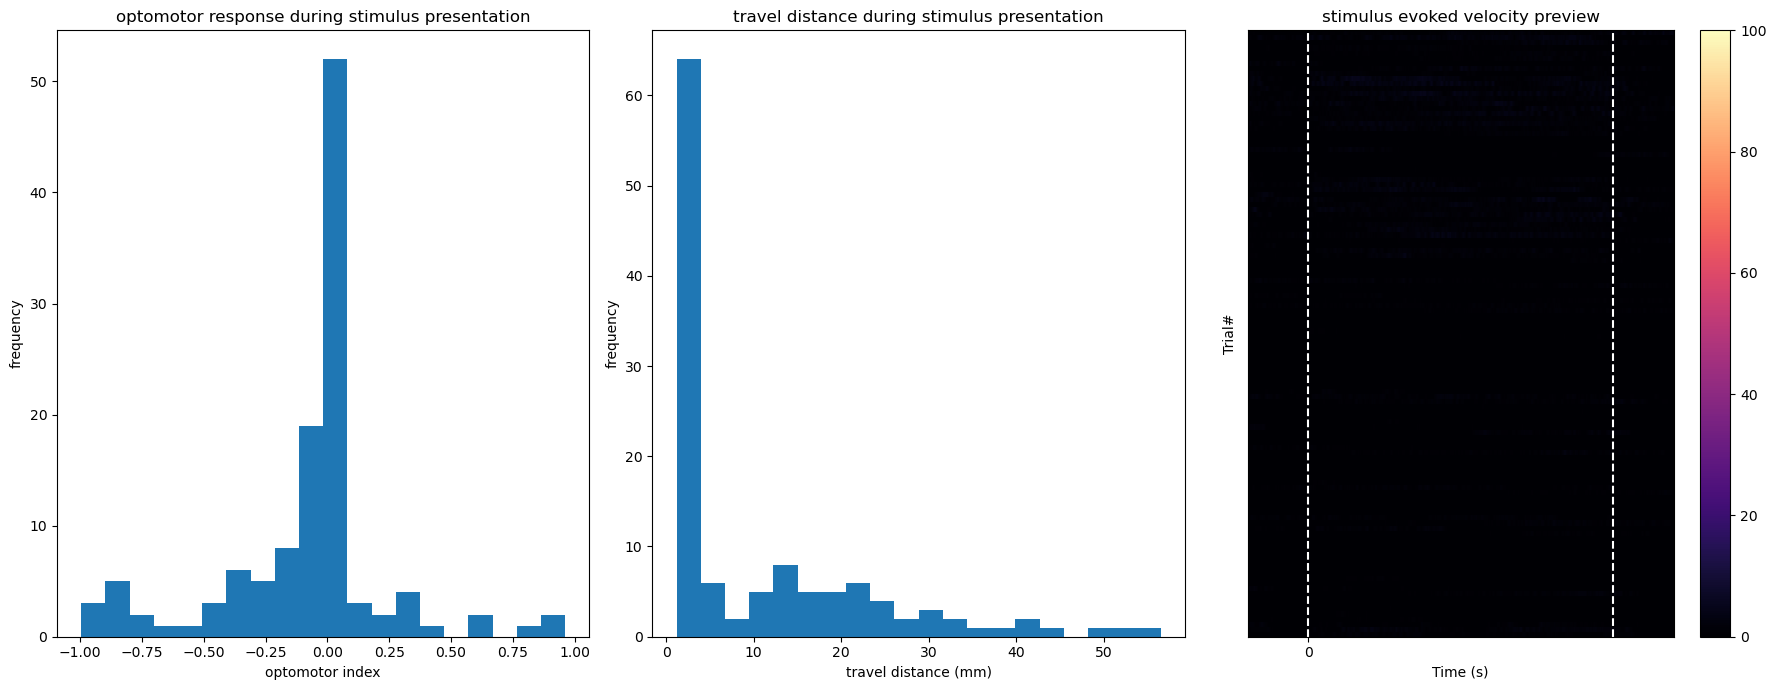

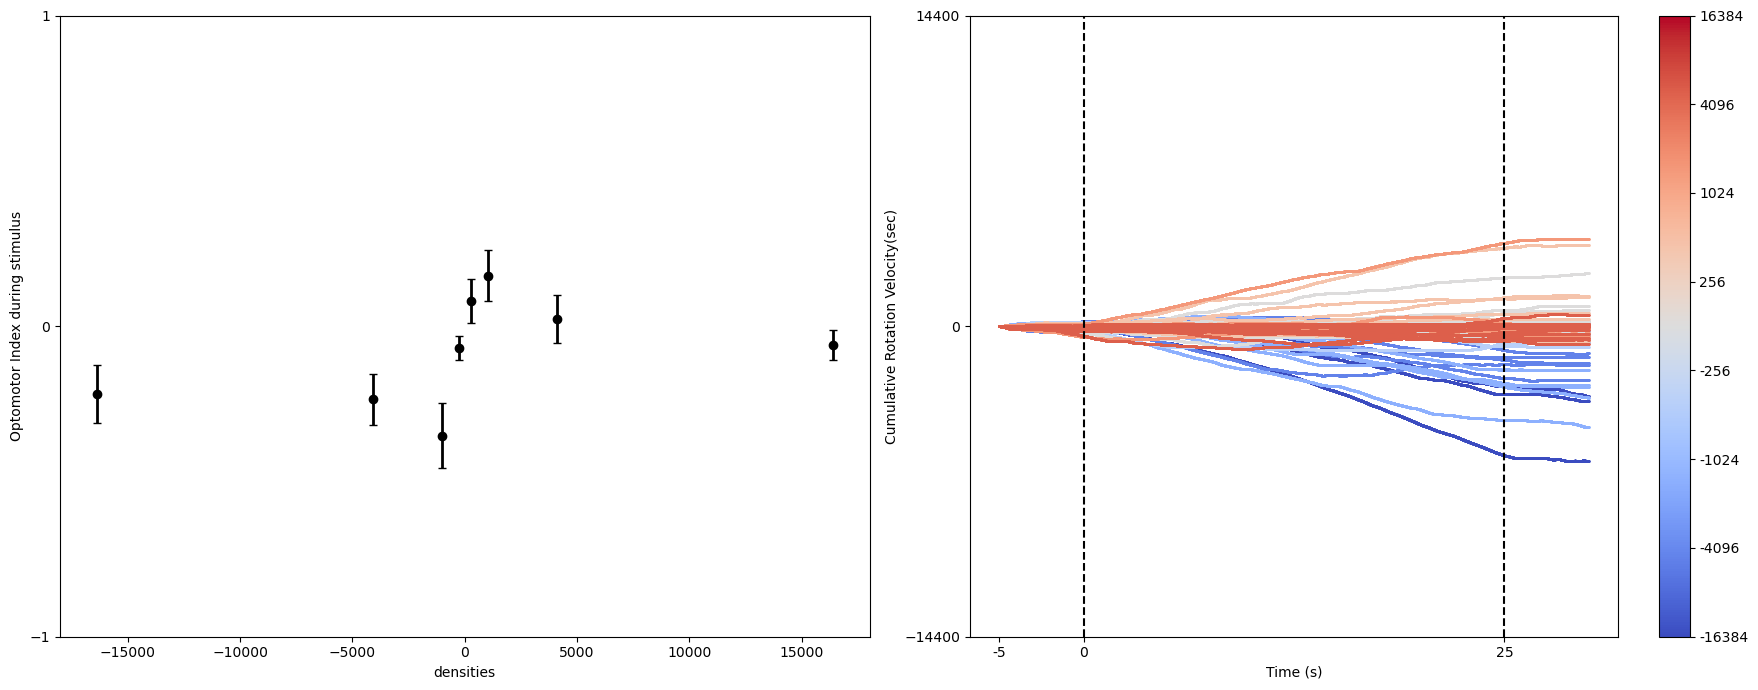

no PD*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22037/220819/densities. Let's leave this programme
no tracking_*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22037/220819/densities. Let's leave this programme
plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


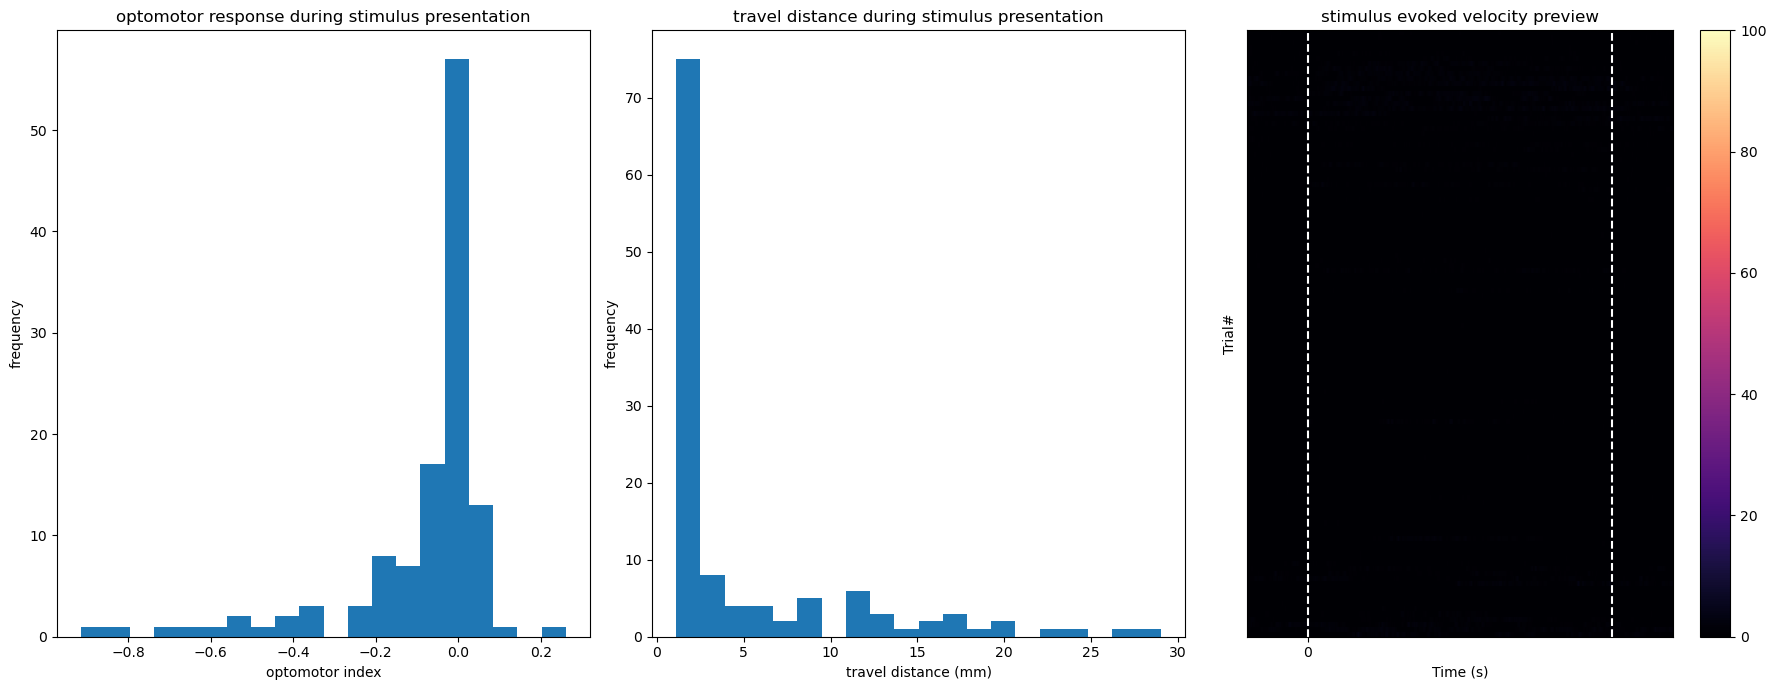

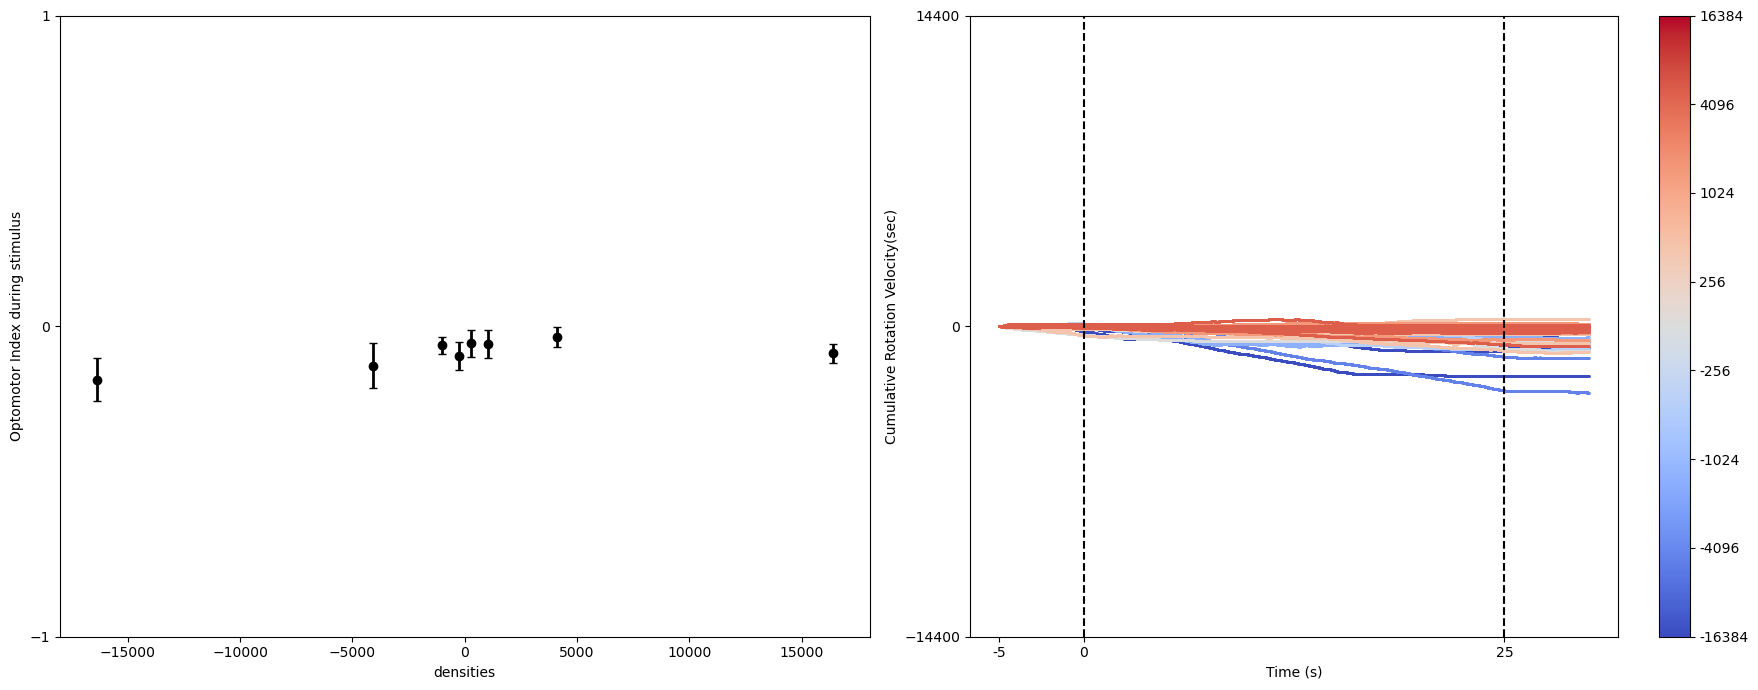

no PD*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22038/220819/densities. Let's leave this programme
no tracking_*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22038/220819/densities. Let's leave this programme
plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


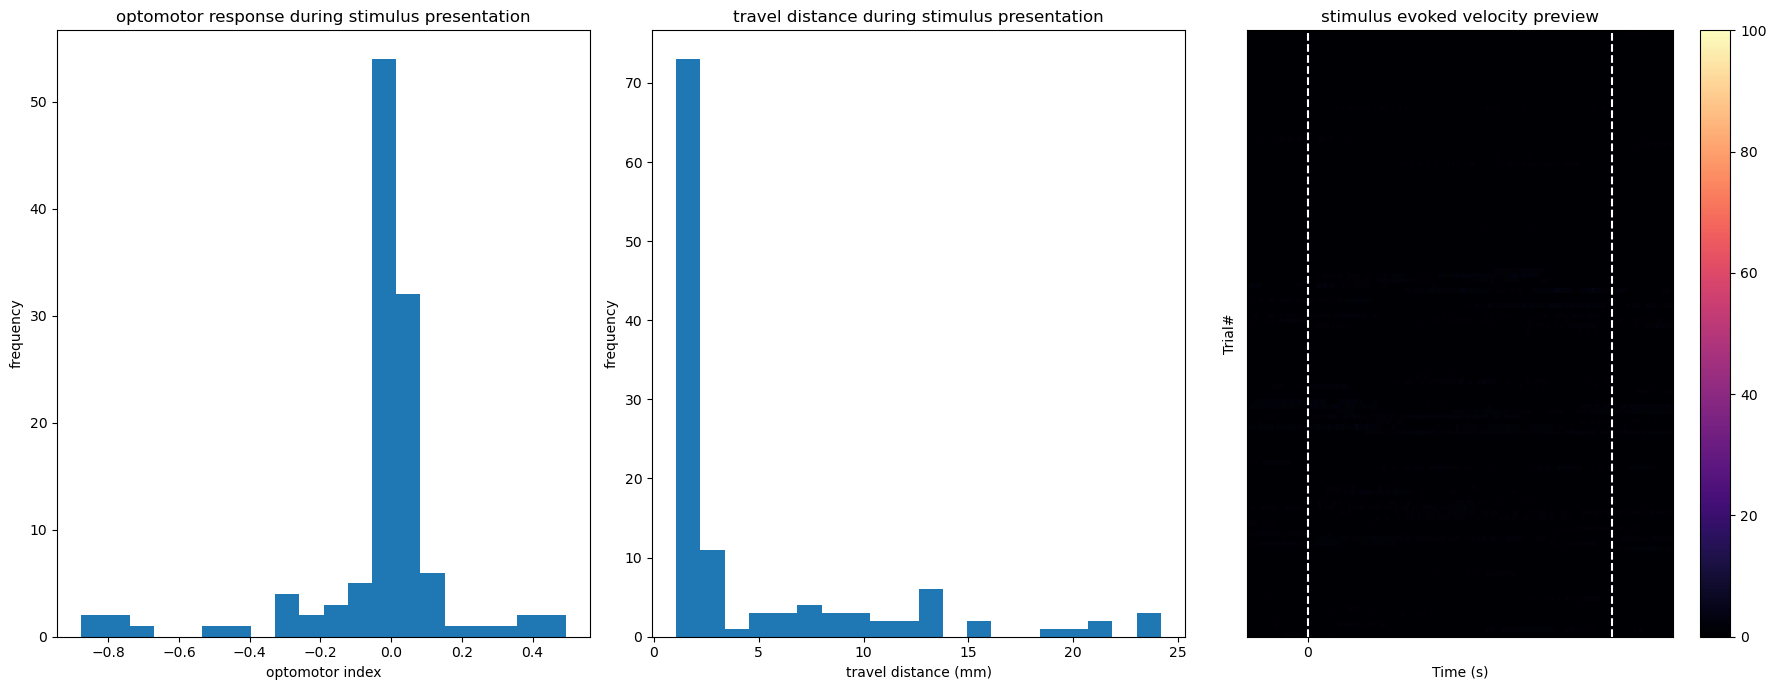

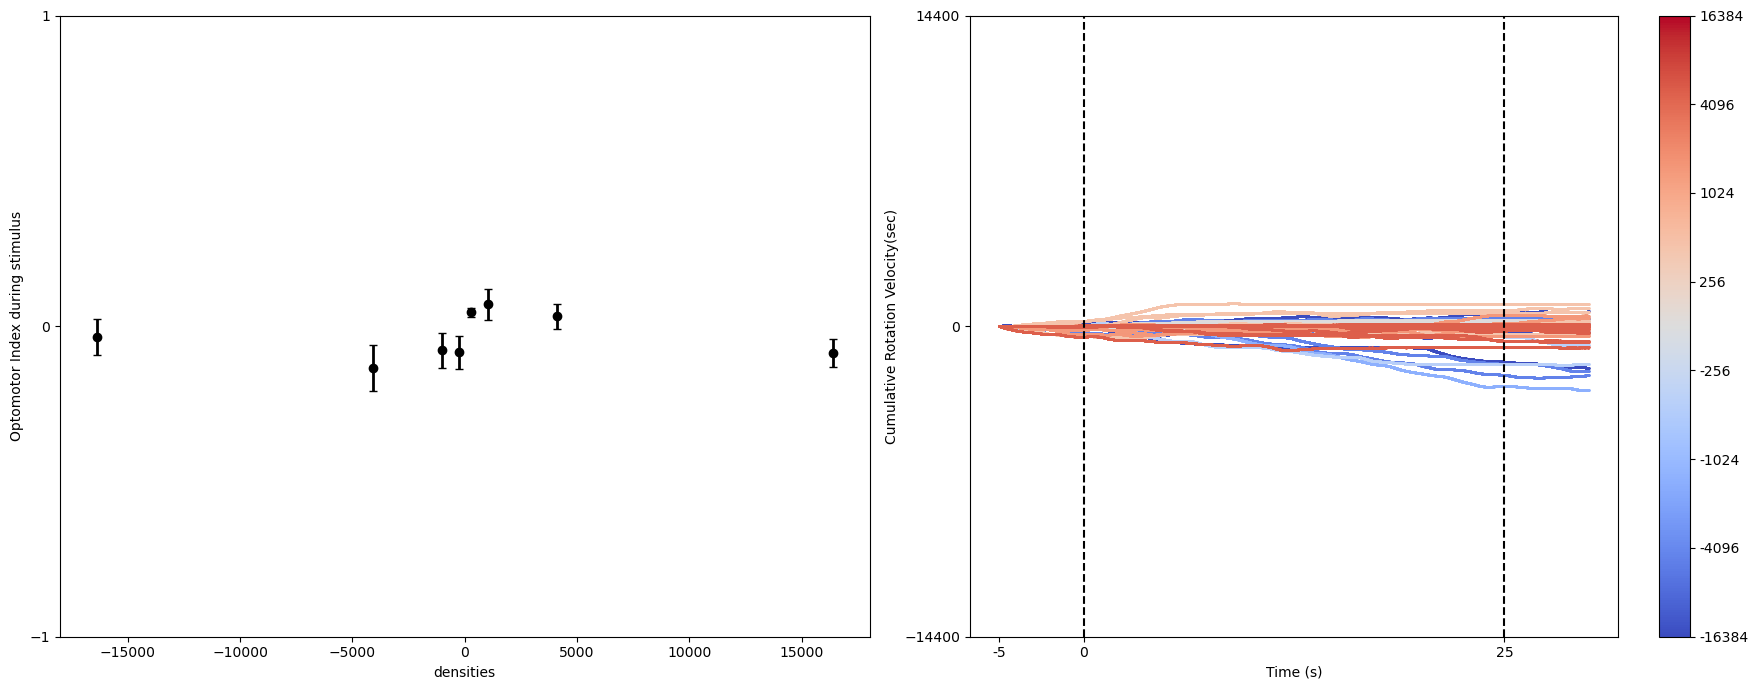

no PD*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22039/220819/densities. Let's leave this programme
no tracking_*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22039/220819/densities. Let's leave this programme
plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


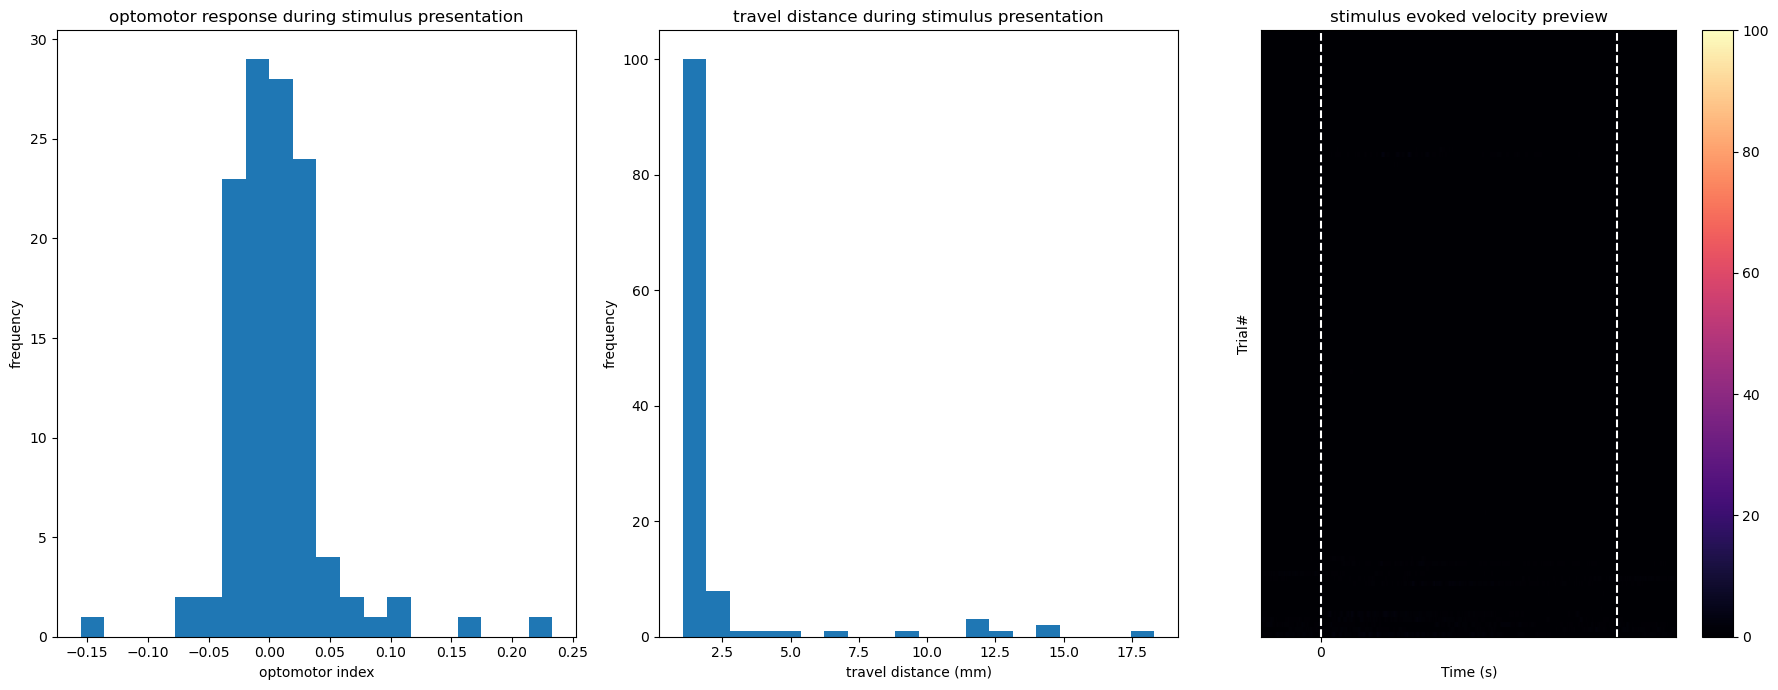

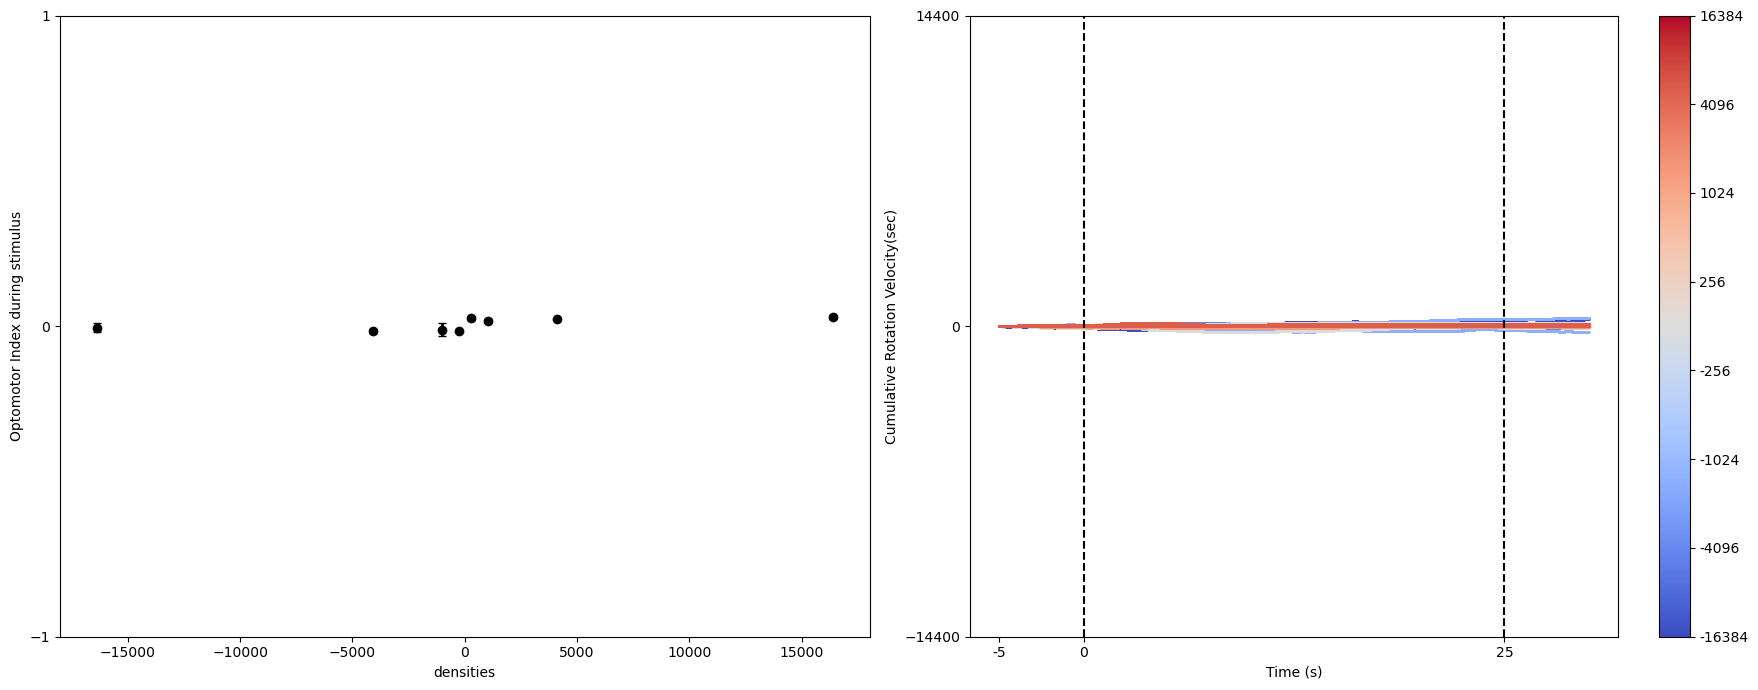

no PD*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22040/220822/densities. Let's leave this programme
no tracking_*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22040/220822/densities. Let's leave this programme
plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


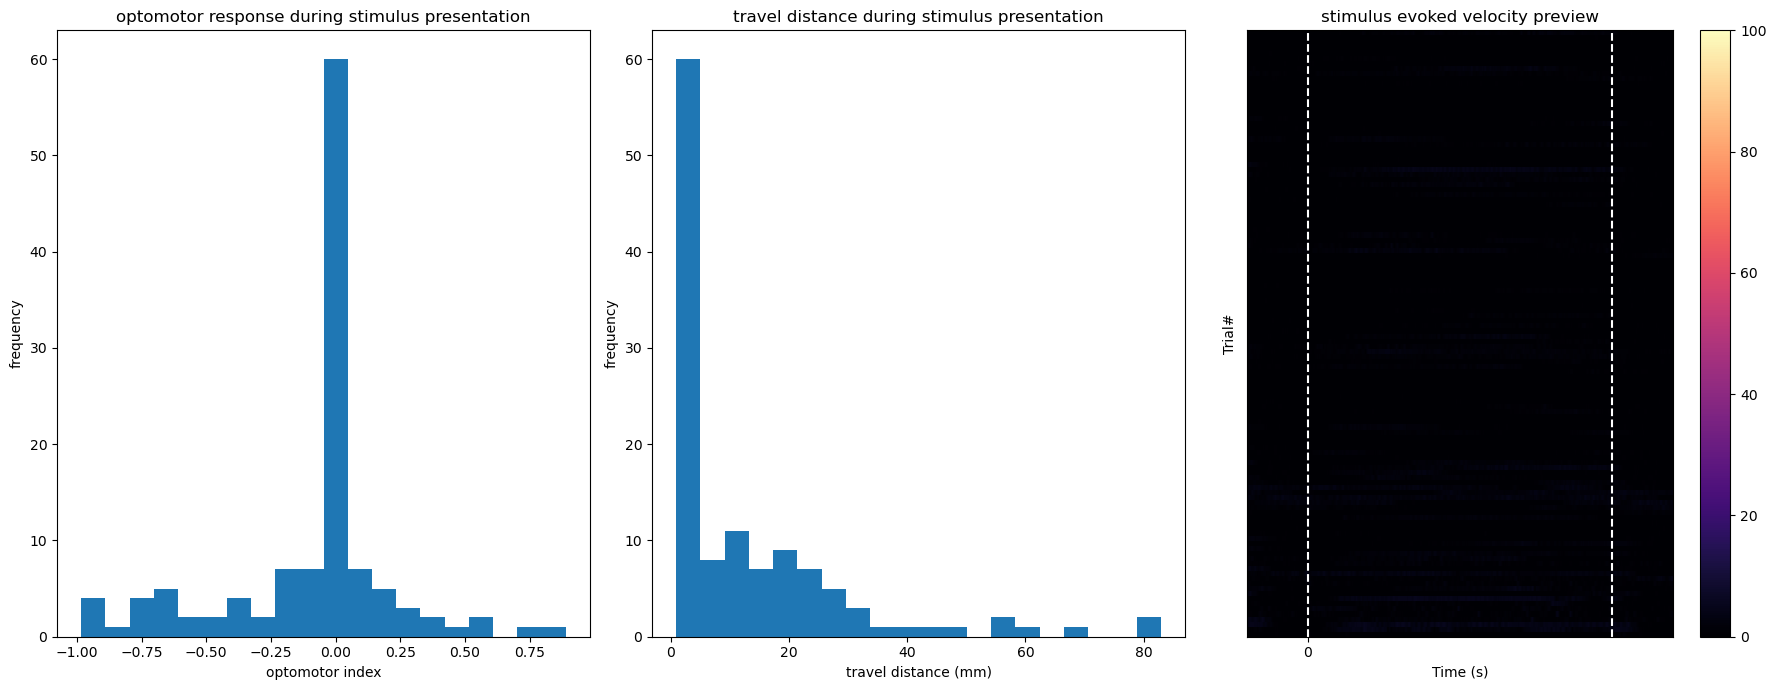

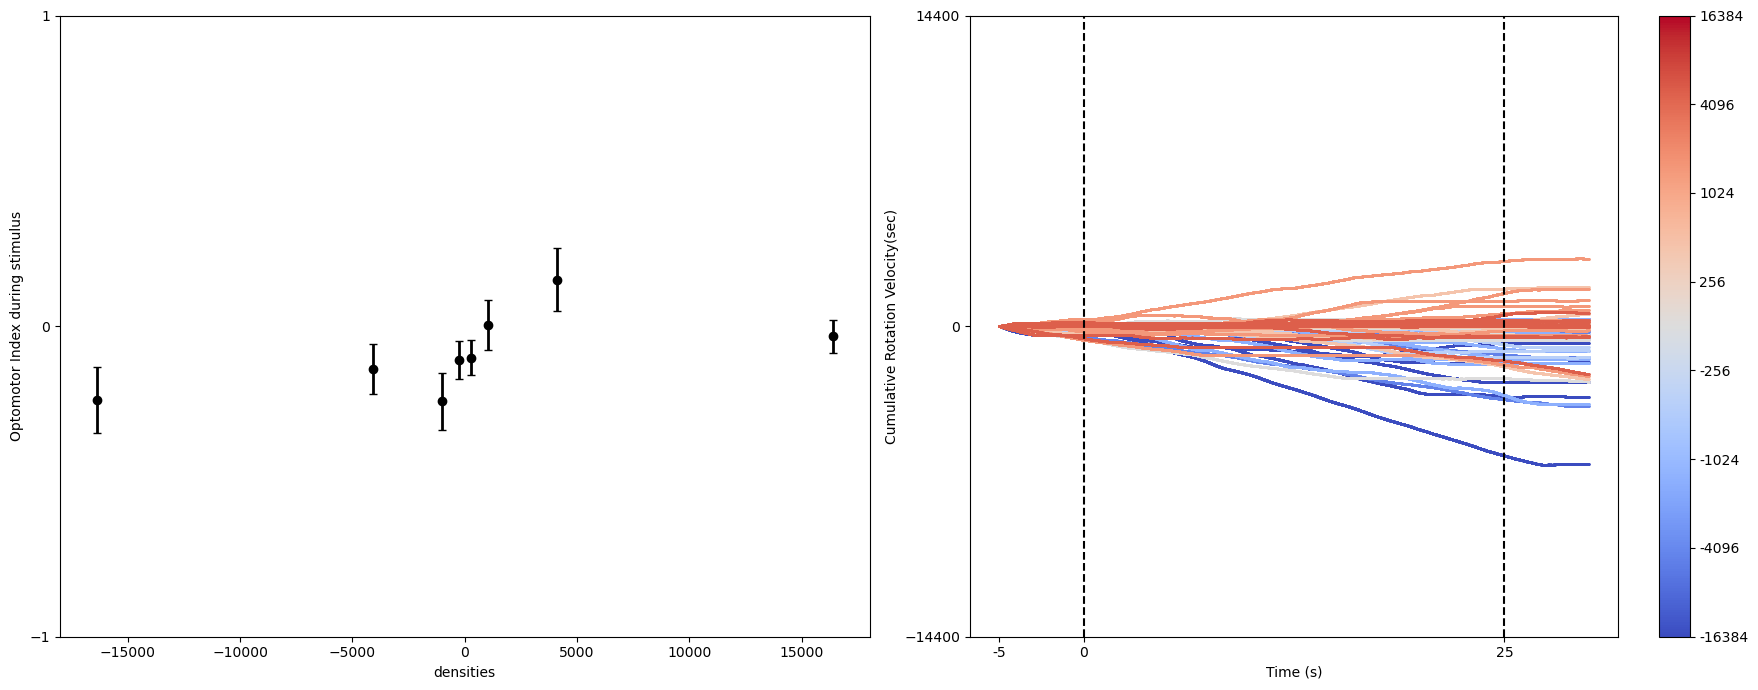

no PD*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22041/220822/densities. Let's leave this programme
no tracking_*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22041/220822/densities. Let's leave this programme
plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


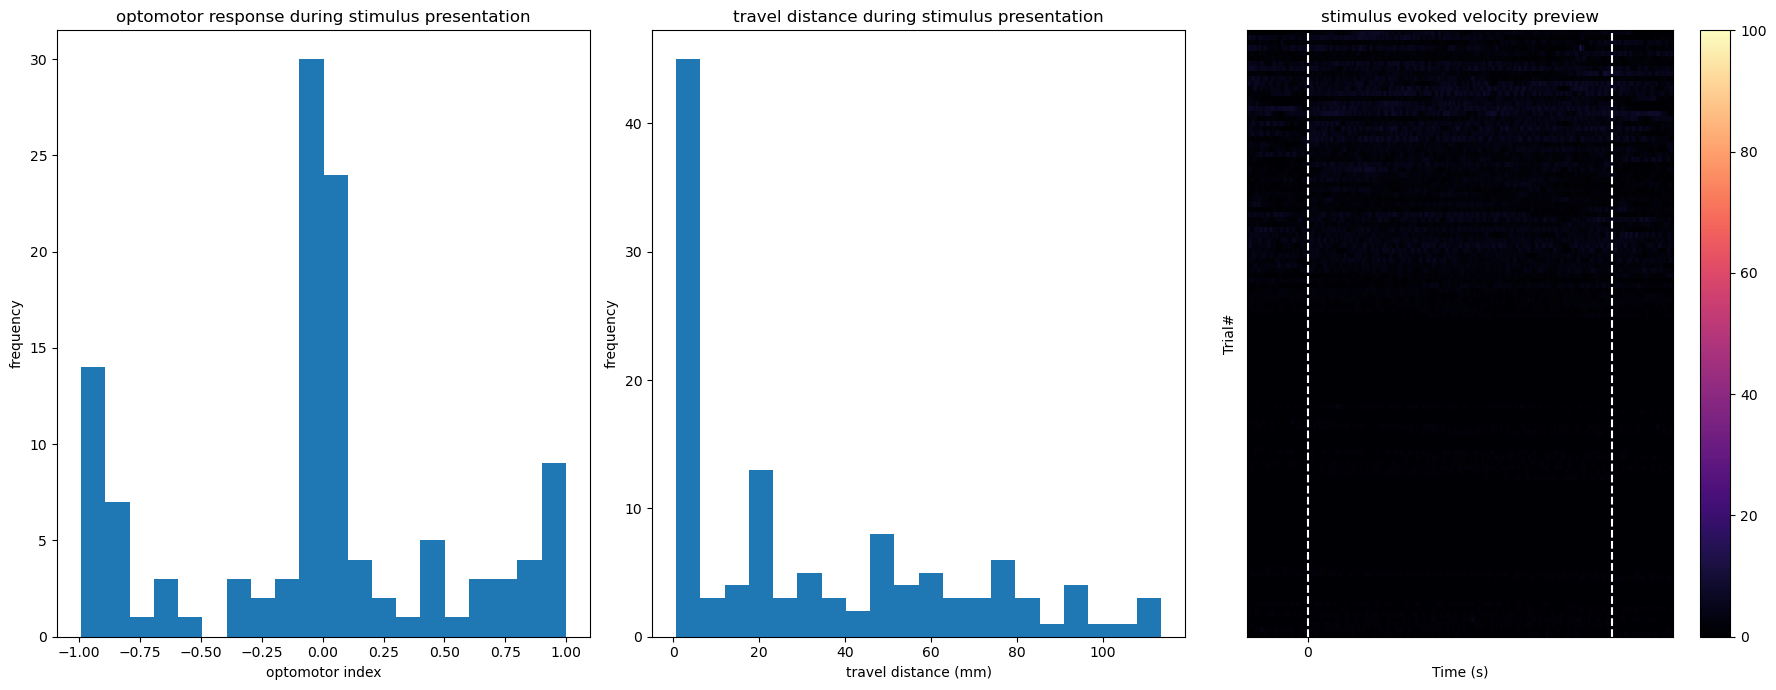

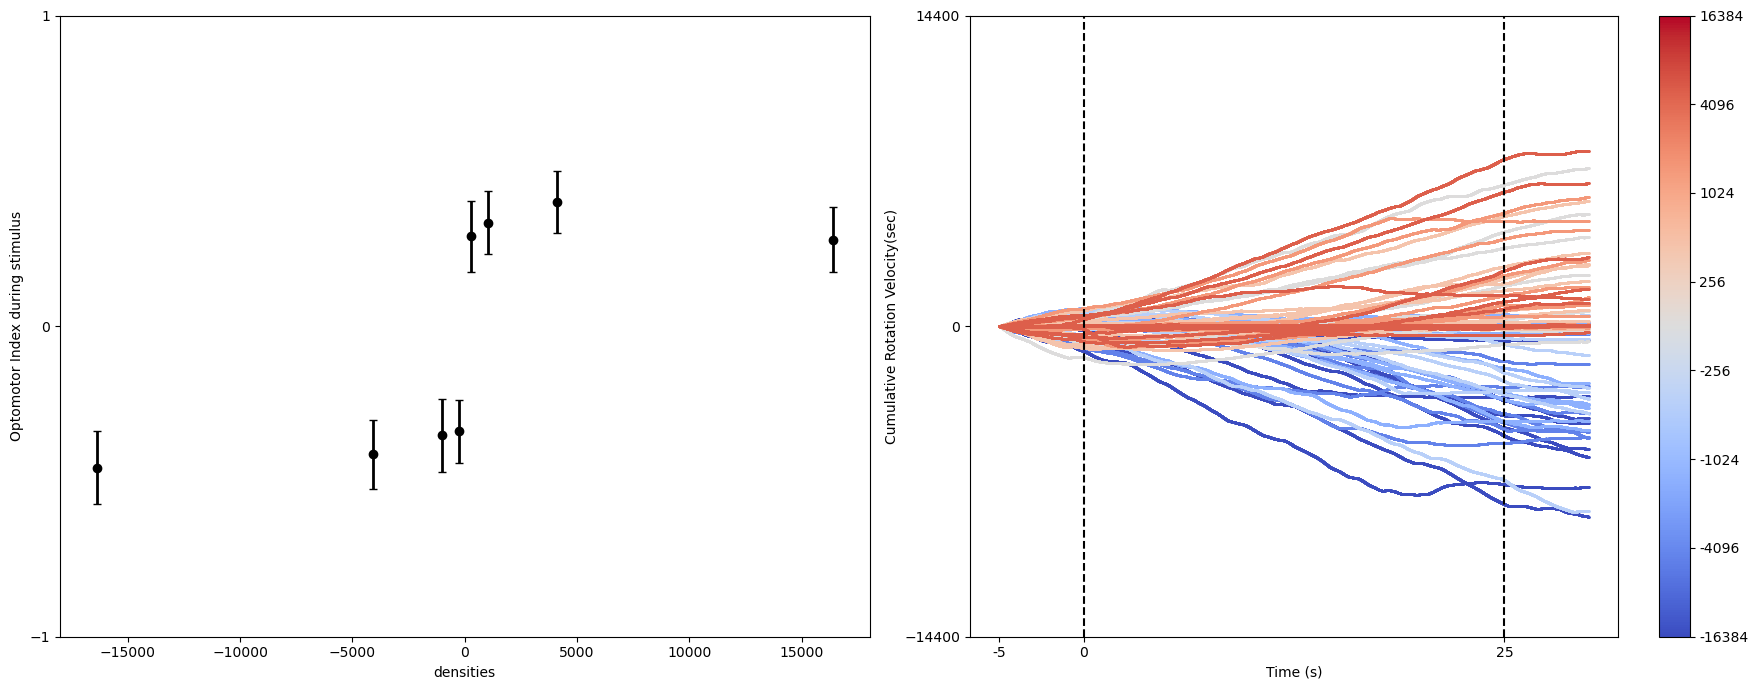

no PD*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22043/220823/densities. Let's leave this programme
no tracking_*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22043/220823/densities. Let's leave this programme
plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


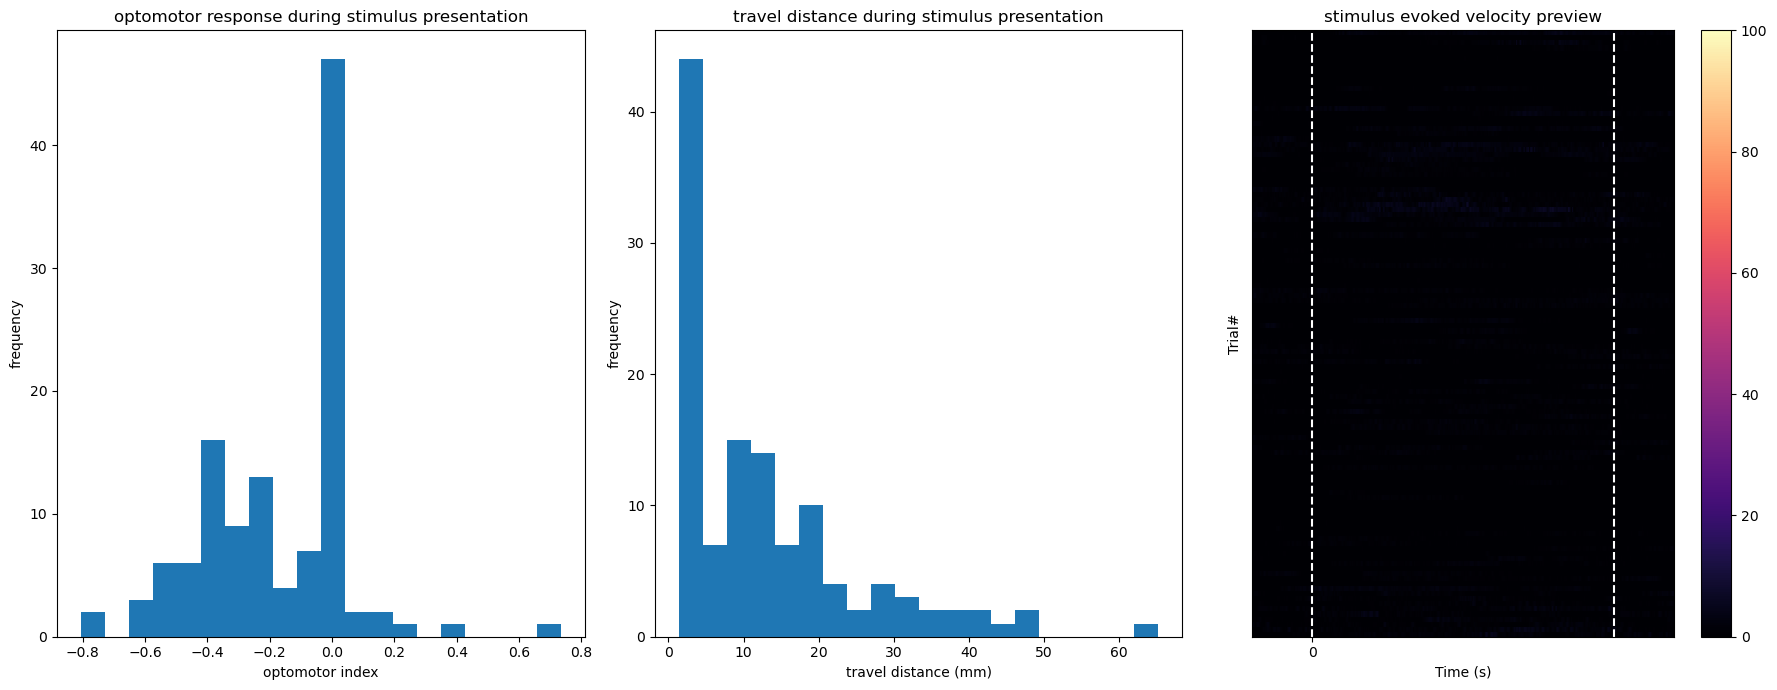

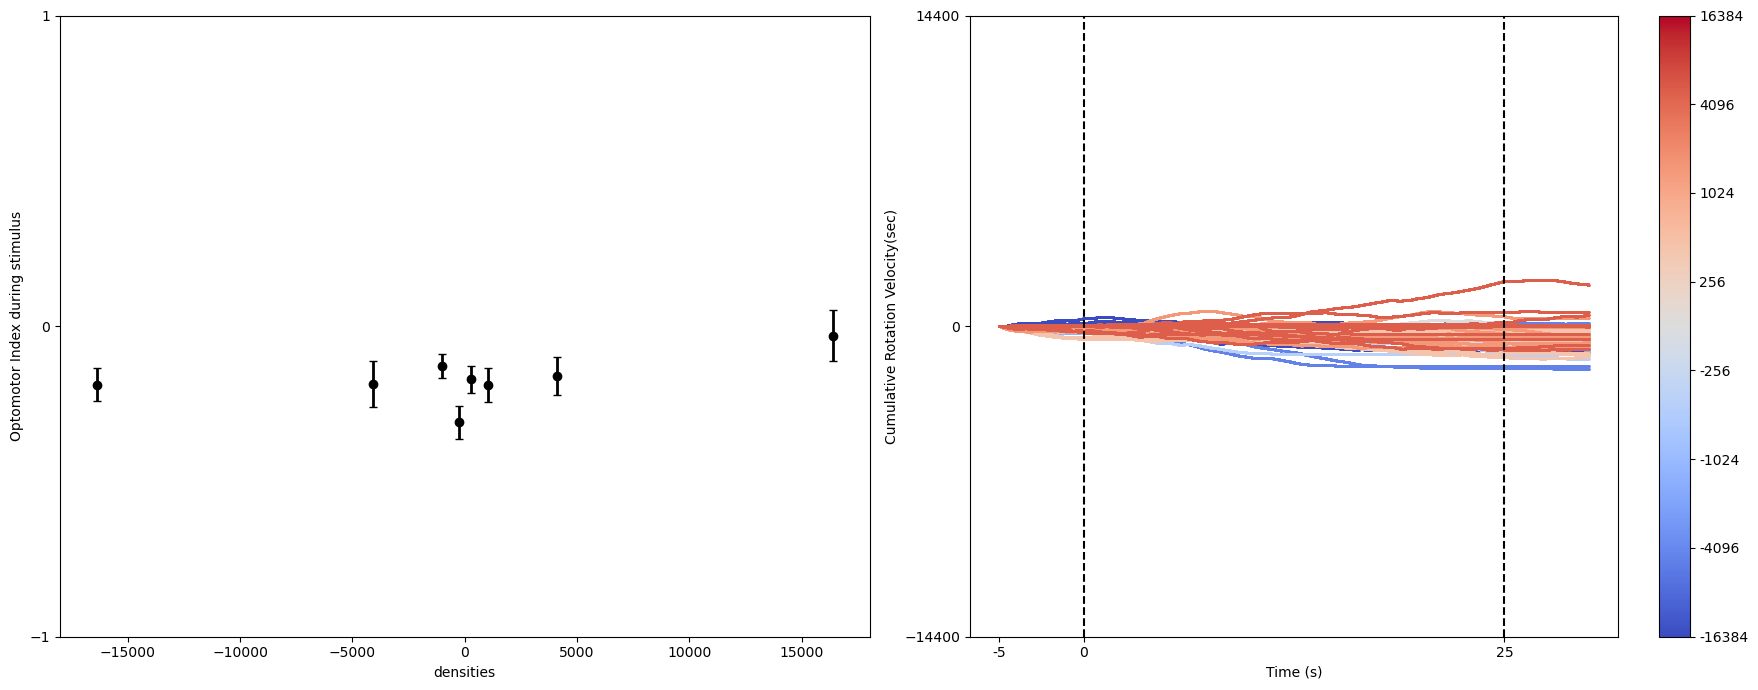

no PD*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22044/220823/densities. Let's leave this programme
no tracking_*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22044/220823/densities. Let's leave this programme
plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


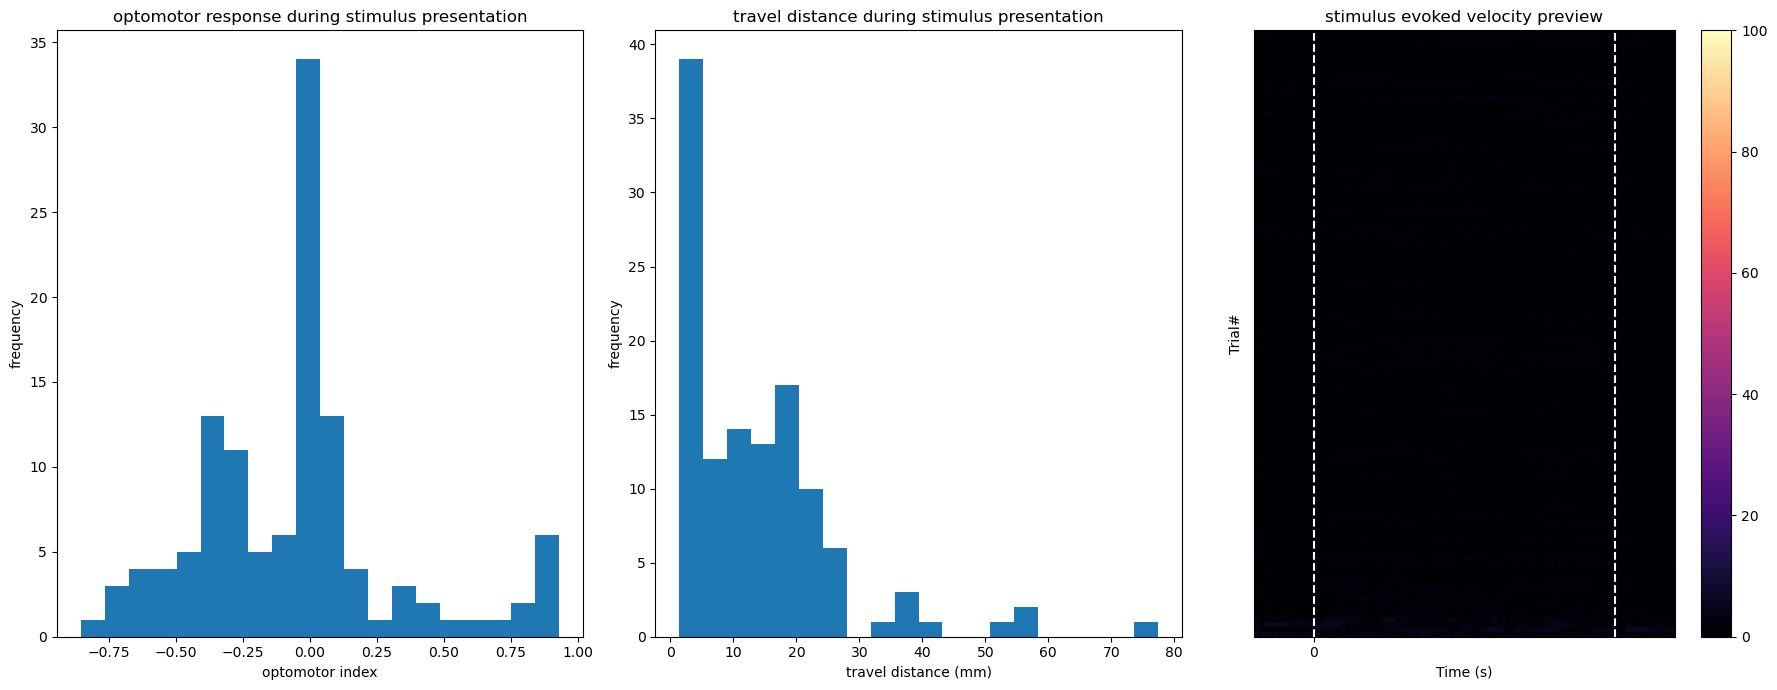

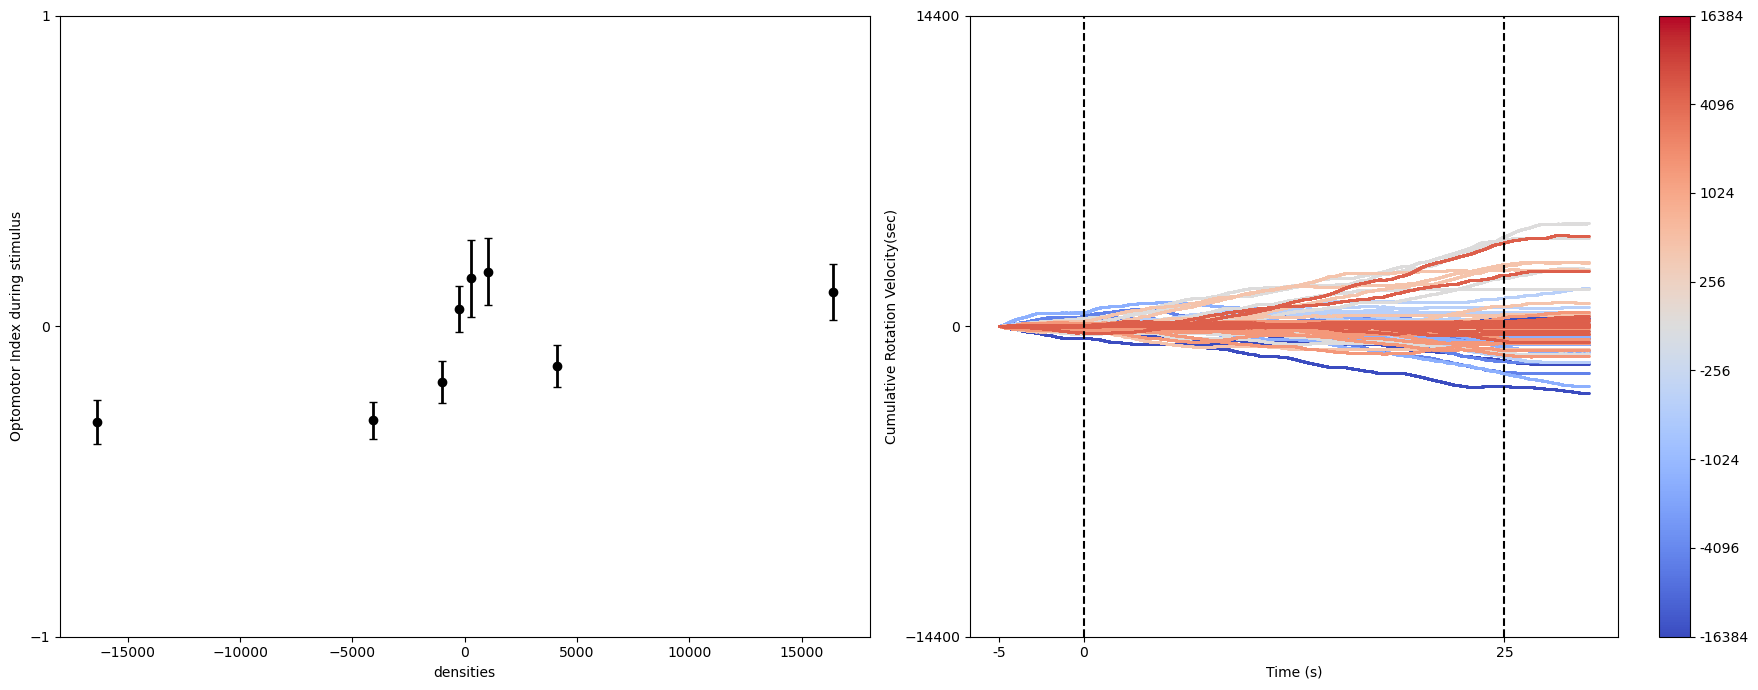

no PD*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22045/220823/densities. Let's leave this programme
no tracking_*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22045/220823/densities. Let's leave this programme
plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


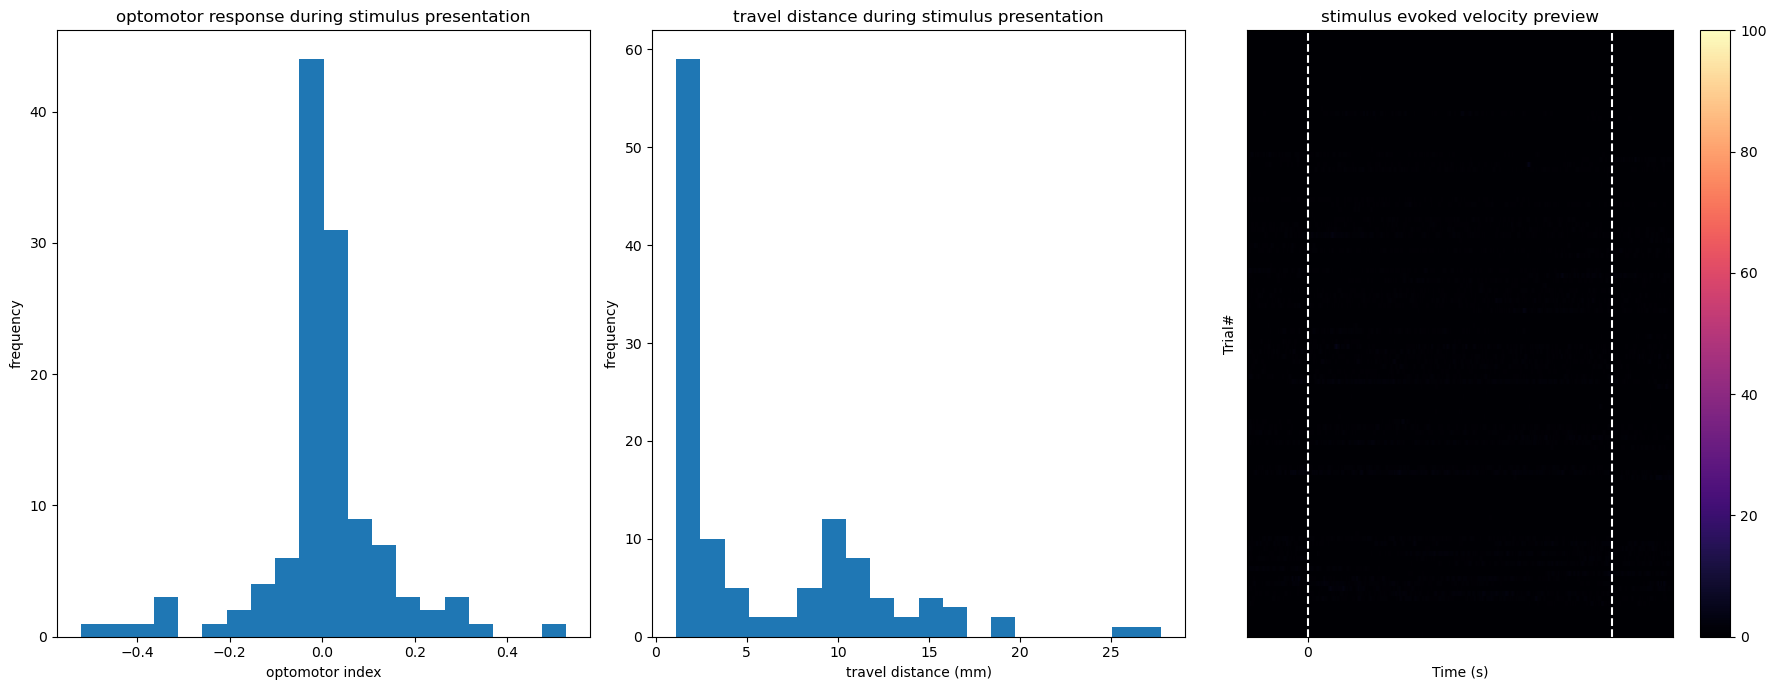

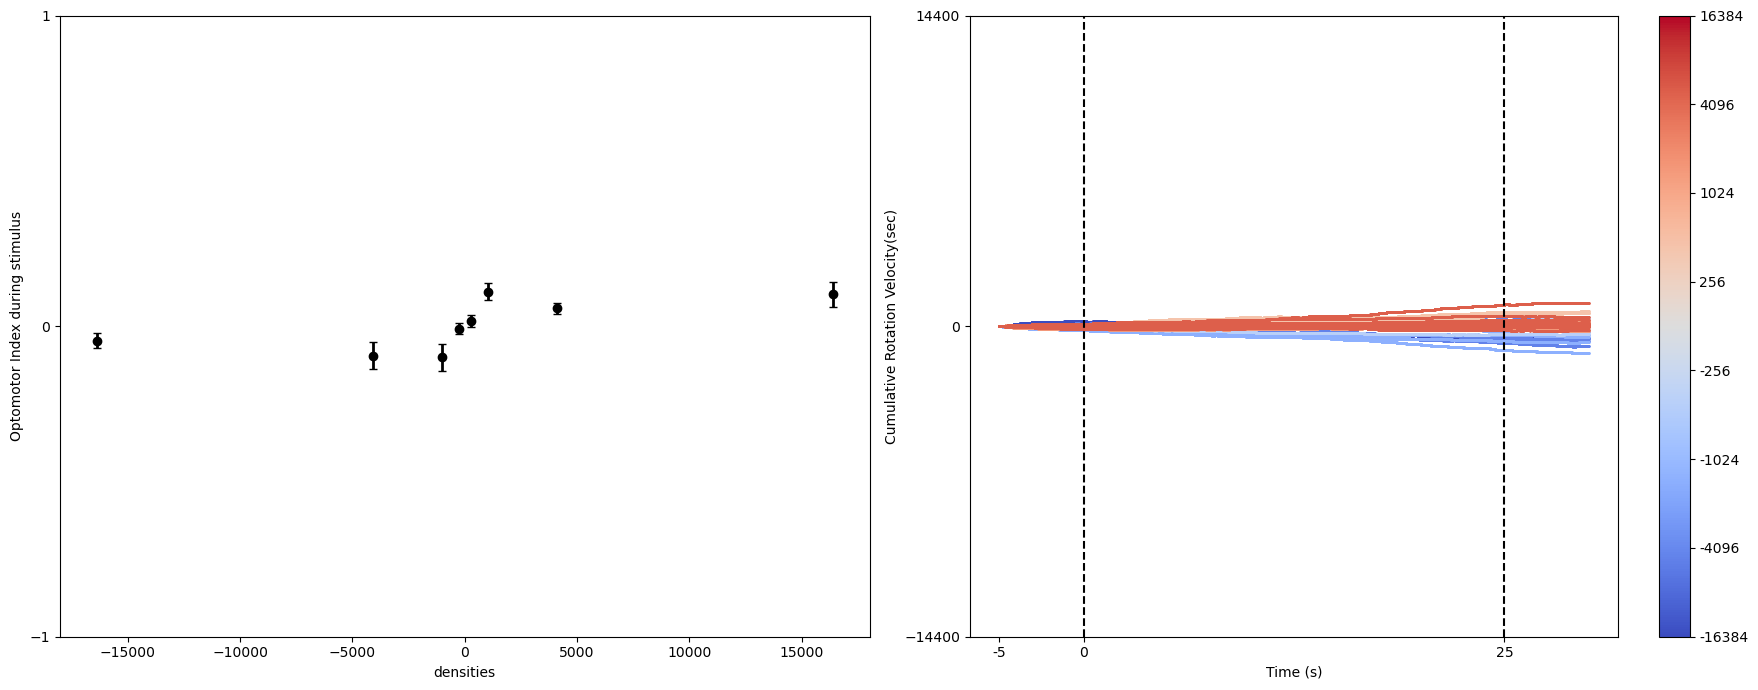

no PD*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22046/220823/densities. Let's leave this programme
no tracking_*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22046/220823/densities. Let's leave this programme
plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


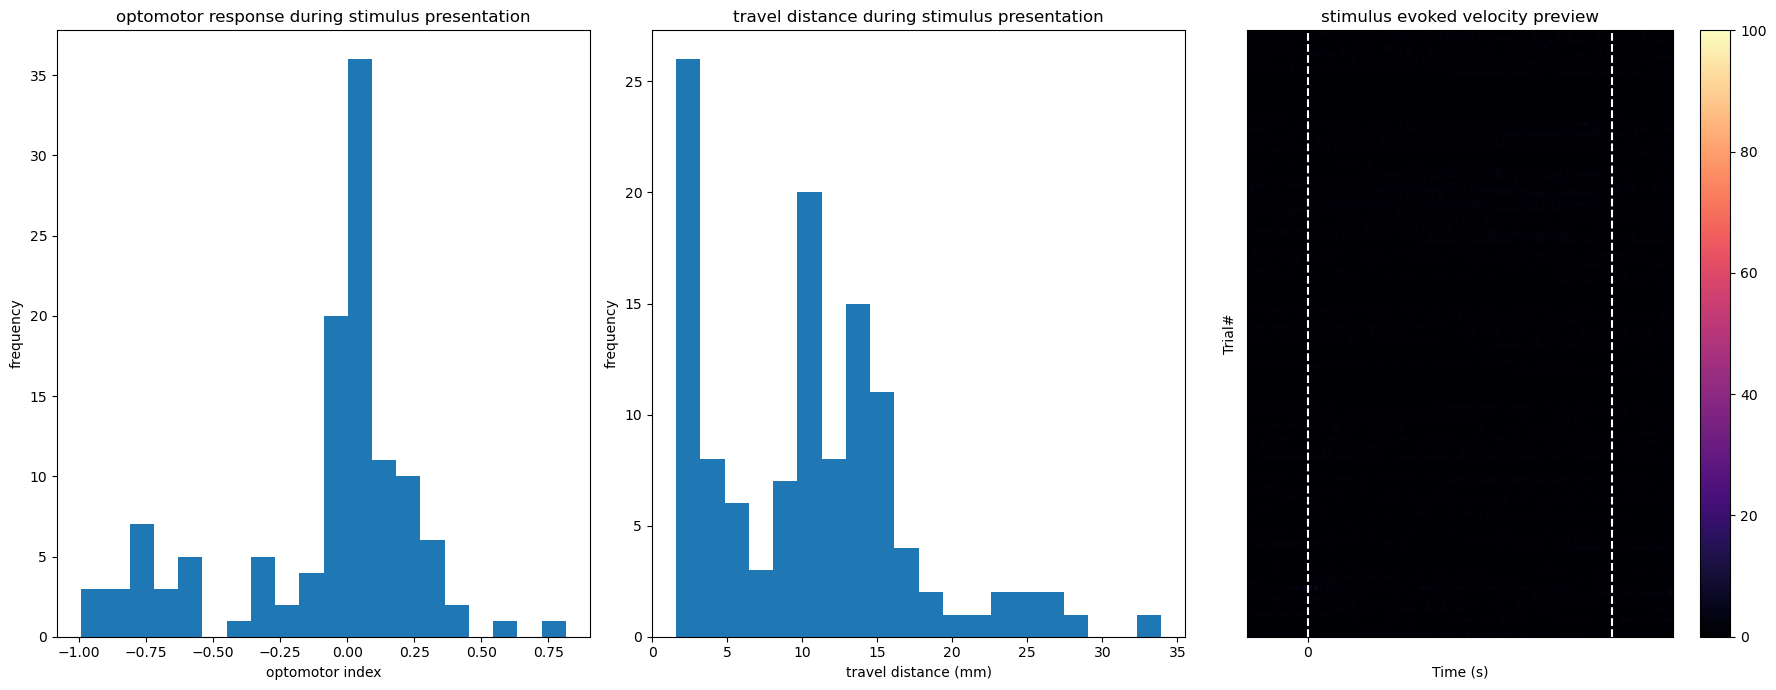

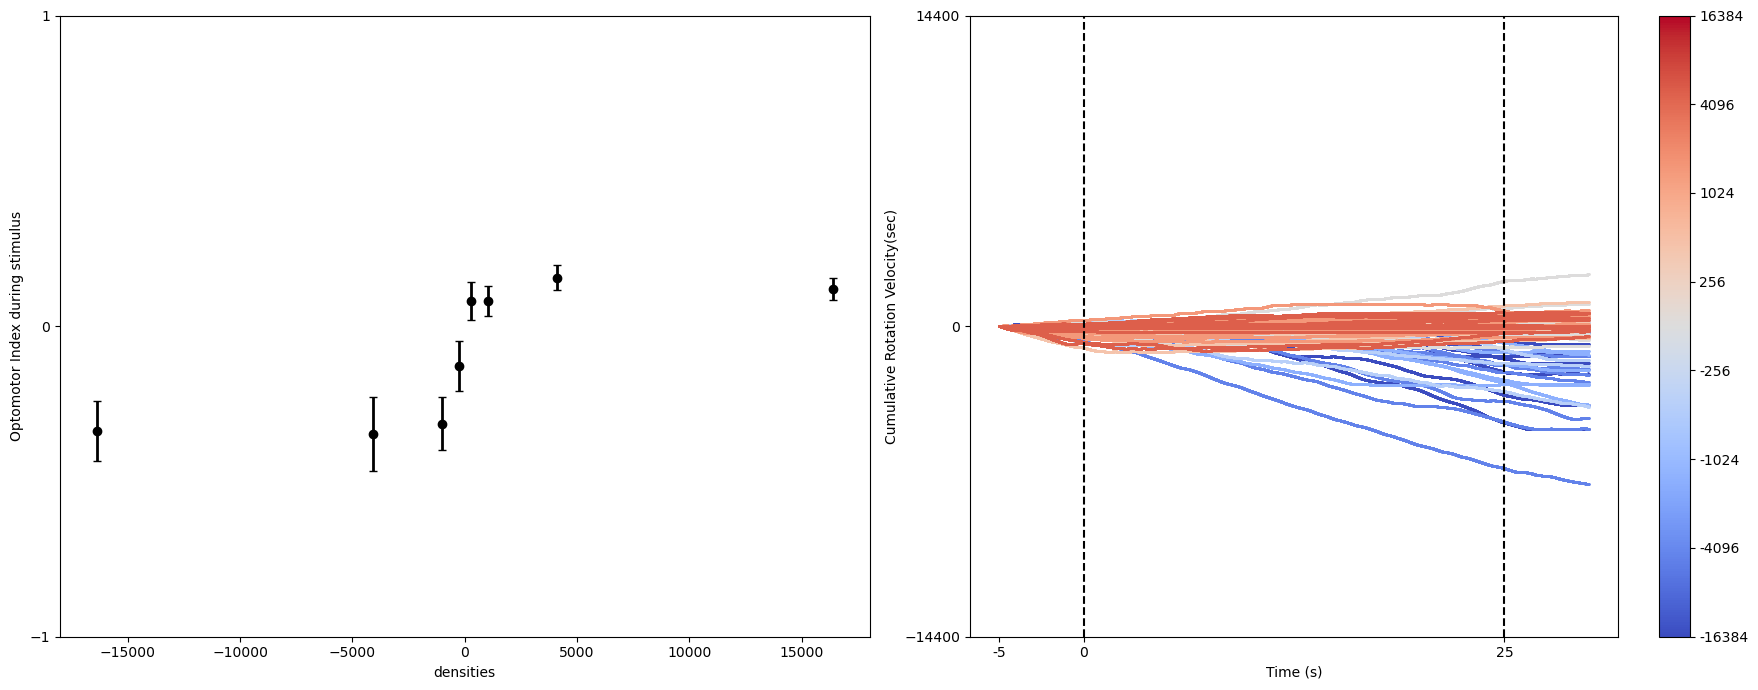

no PD*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22048/220823/densities. Let's leave this programme
no tracking_*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22048/220823/densities. Let's leave this programme
plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


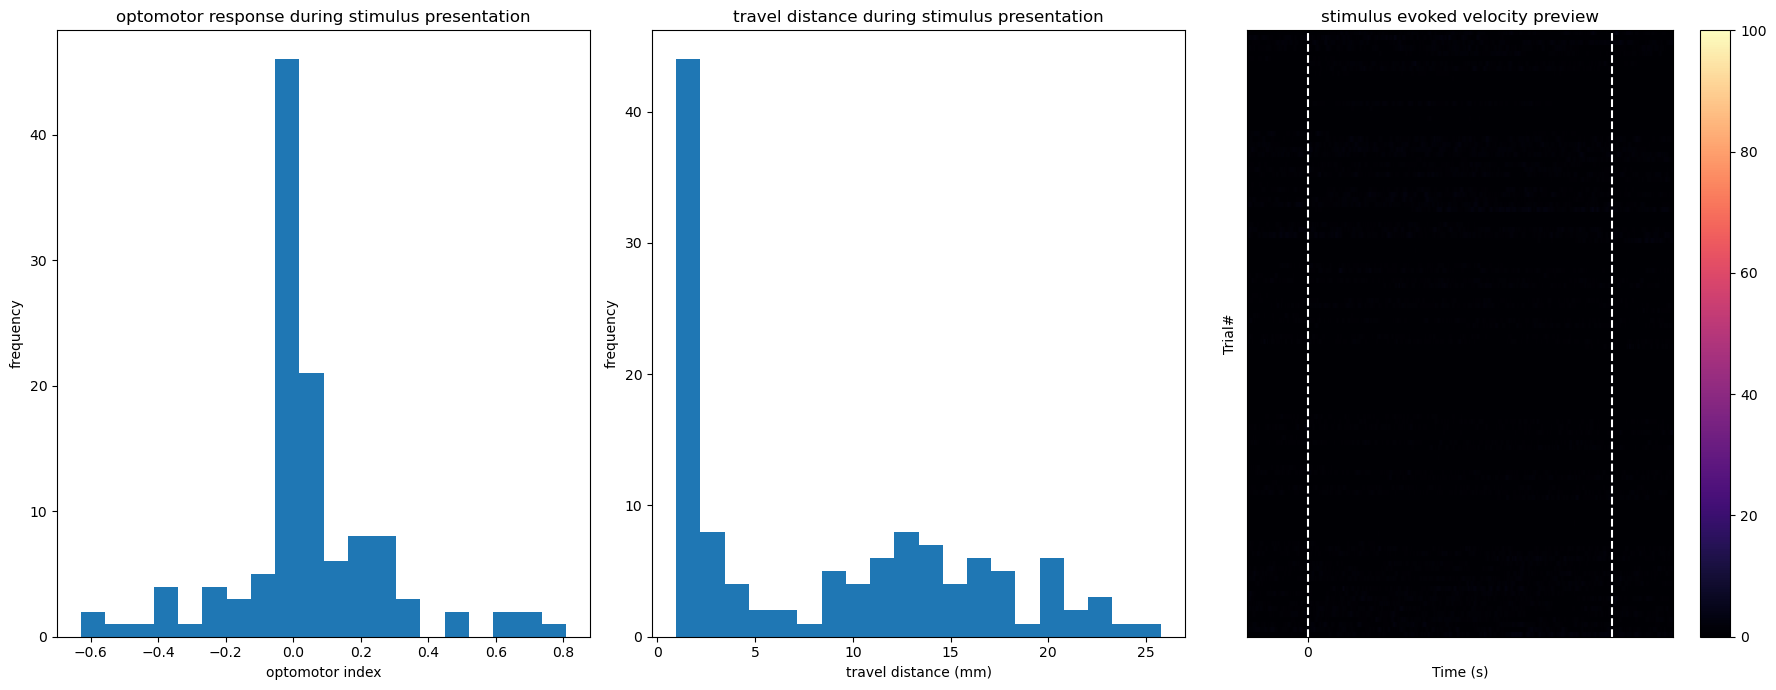

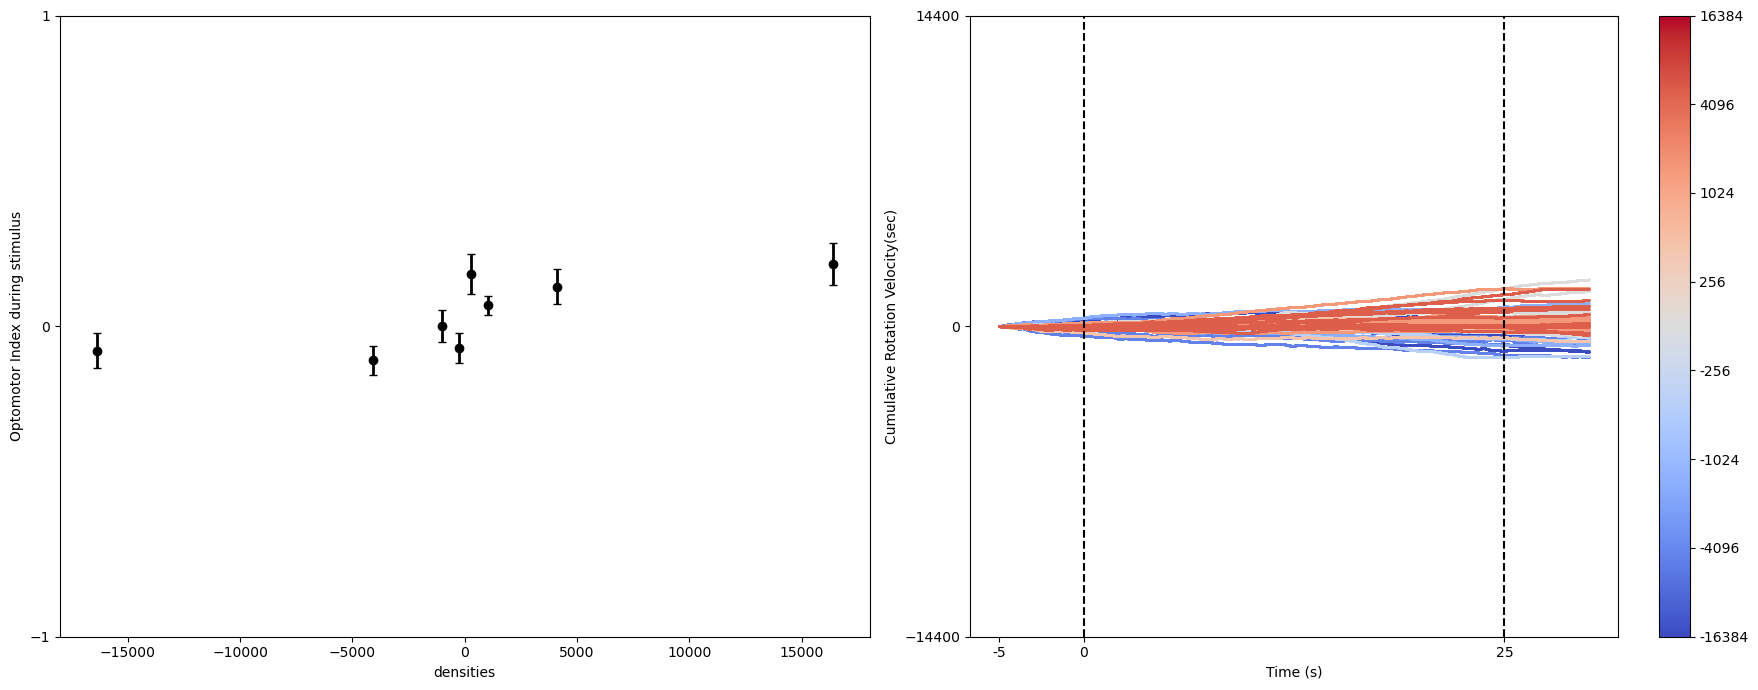

no PD*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22049/220824/densities. Let's leave this programme
no tracking_*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22049/220824/densities. Let's leave this programme
plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


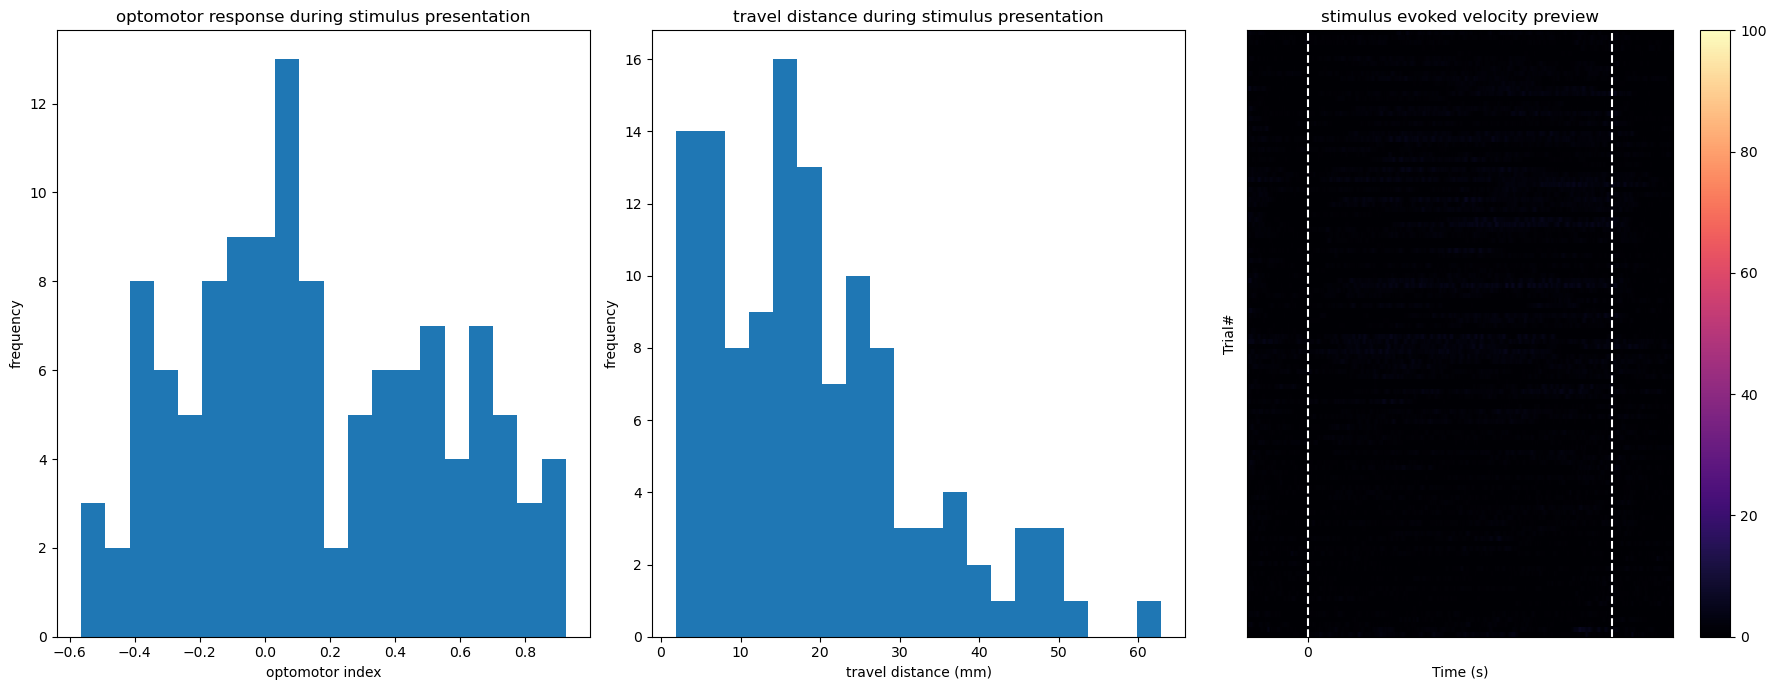

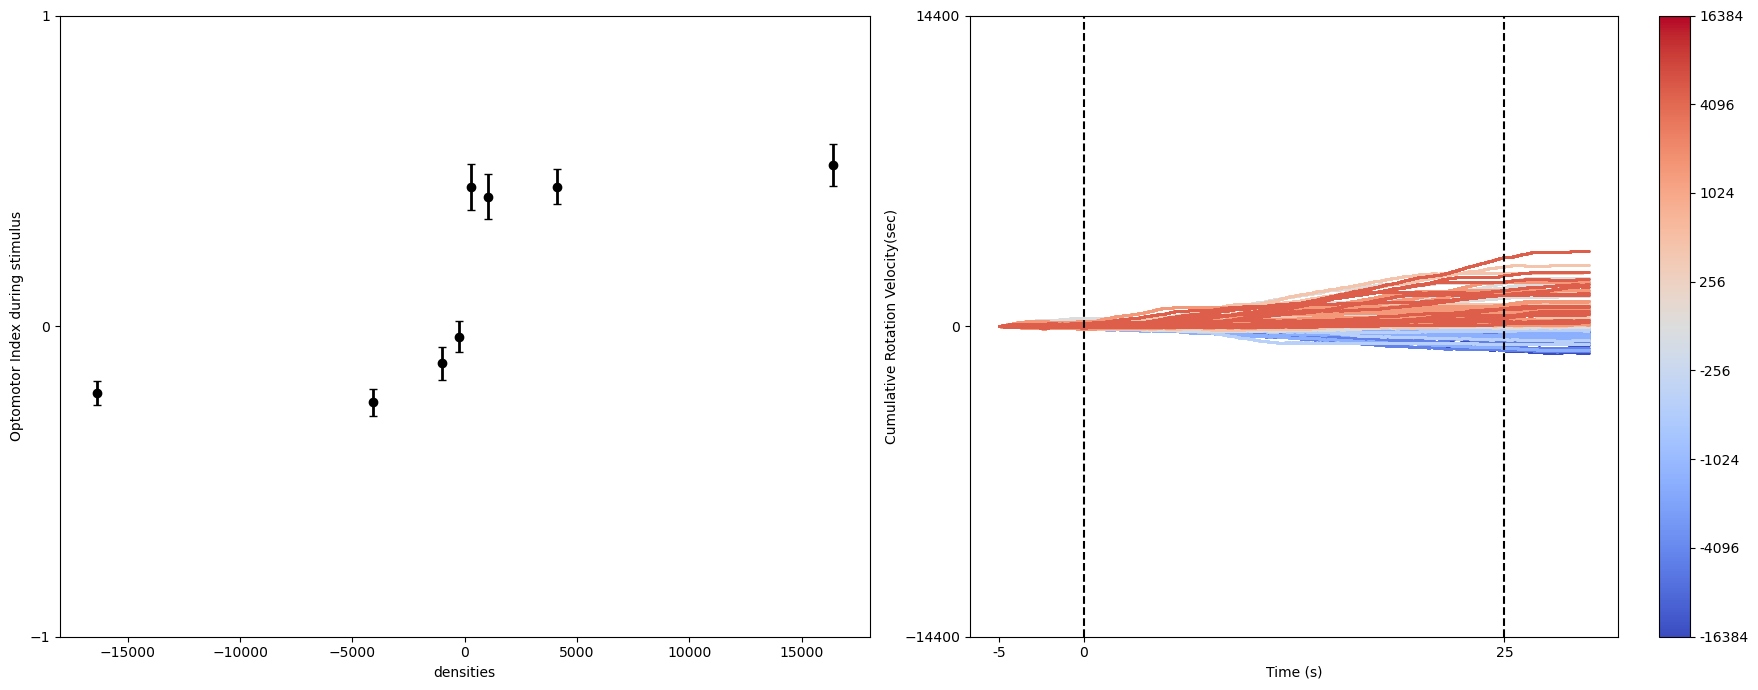

no PD*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22050/220824/densities. Let's leave this programme
no tracking_*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22050/220824/densities. Let's leave this programme
plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


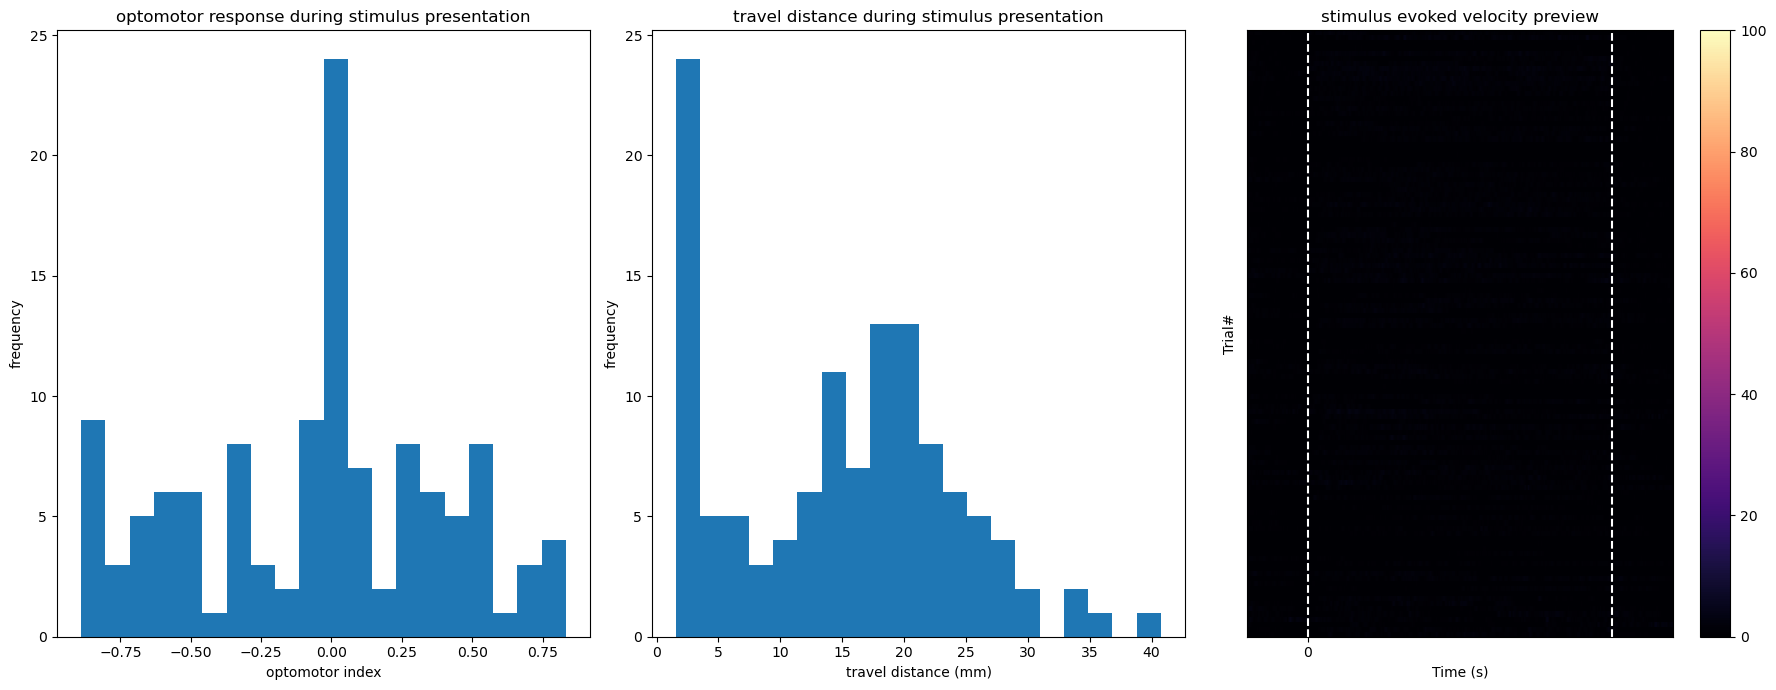

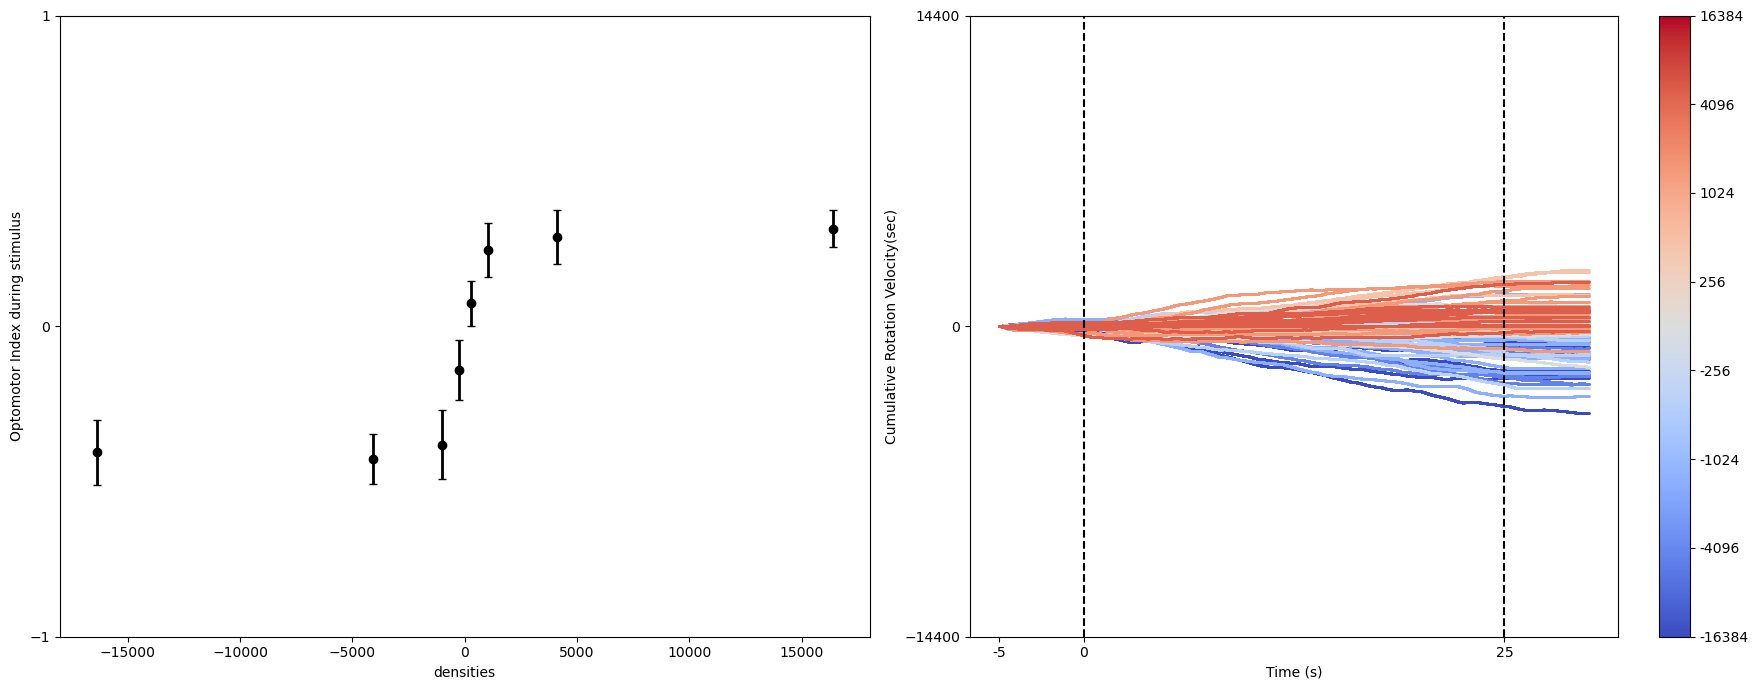

no PD*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22051/220824/densities. Let's leave this programme
no tracking_*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22051/220824/densities. Let's leave this programme
plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


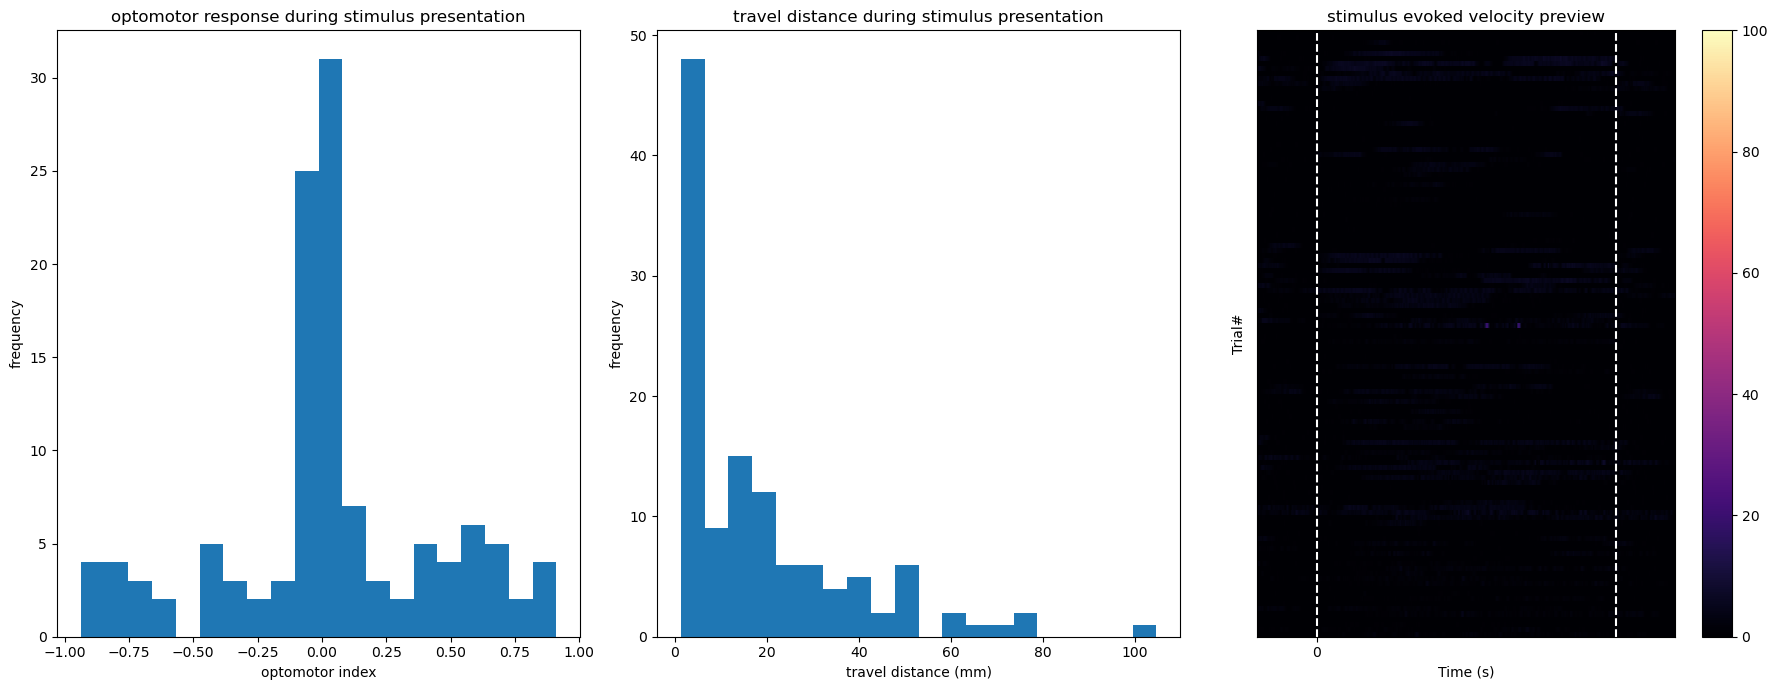

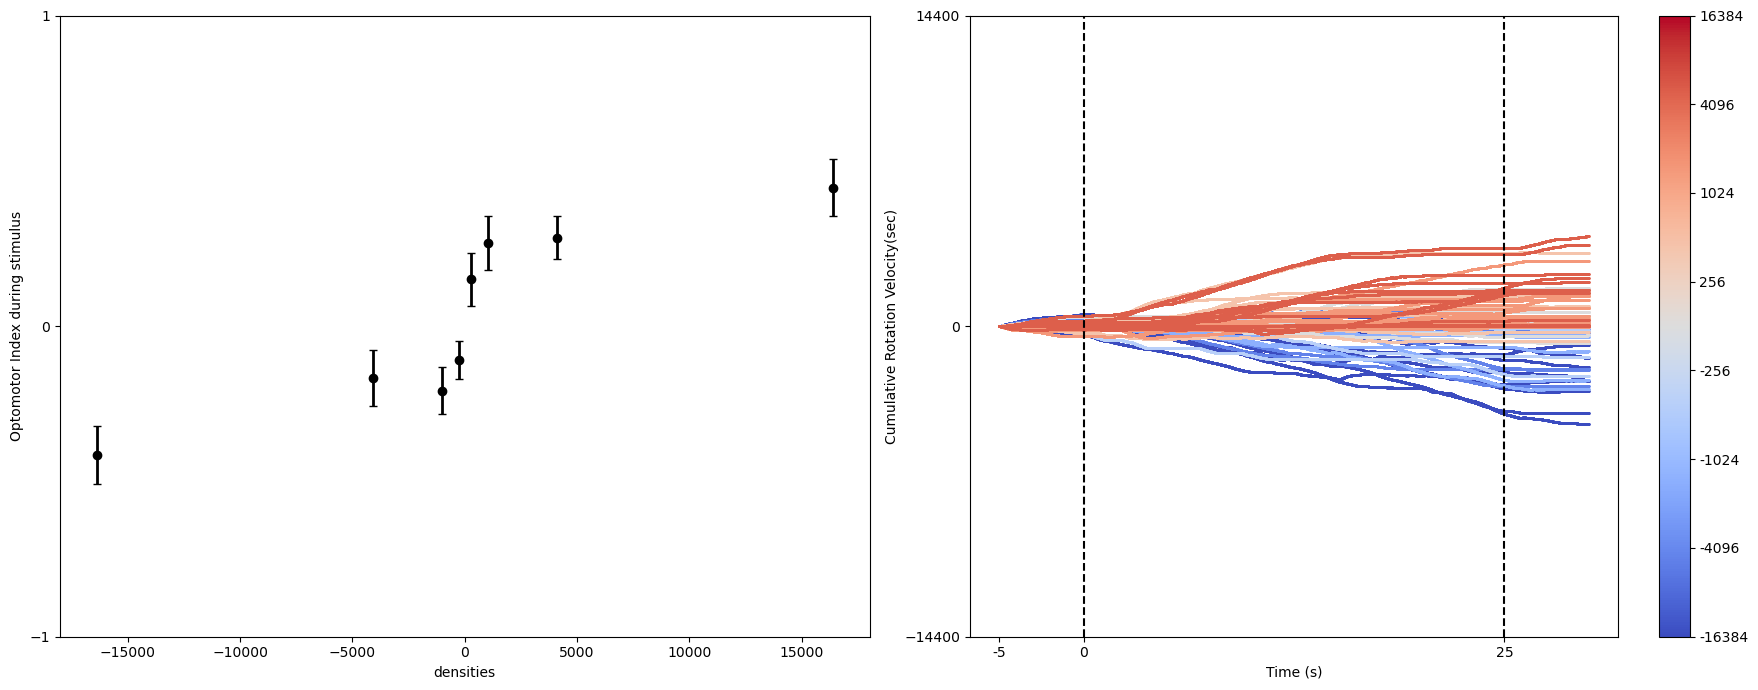

no PD*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22052/220824/densities. Let's leave this programme
no tracking_*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22052/220824/densities. Let's leave this programme
plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


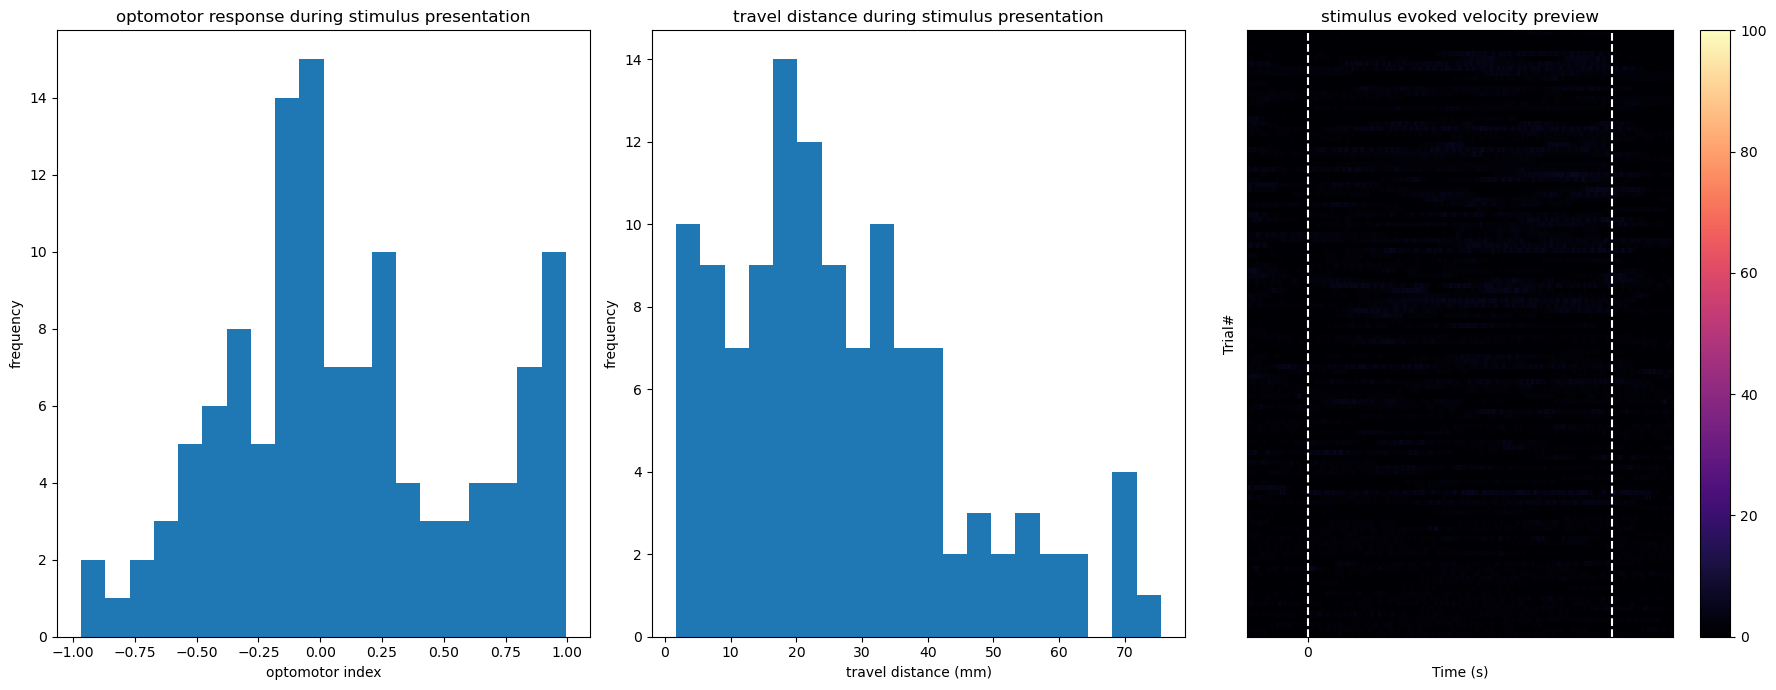

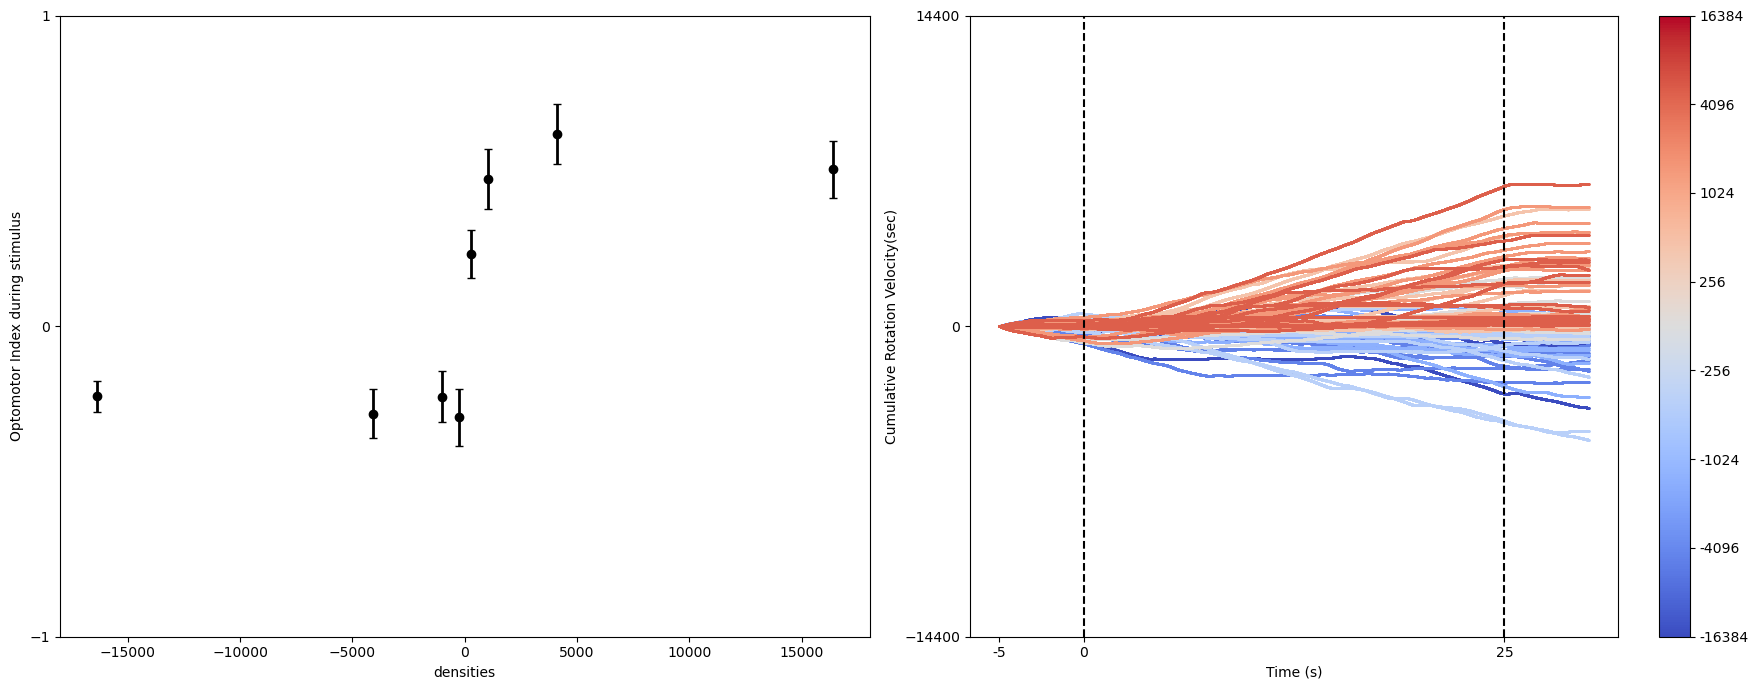

plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


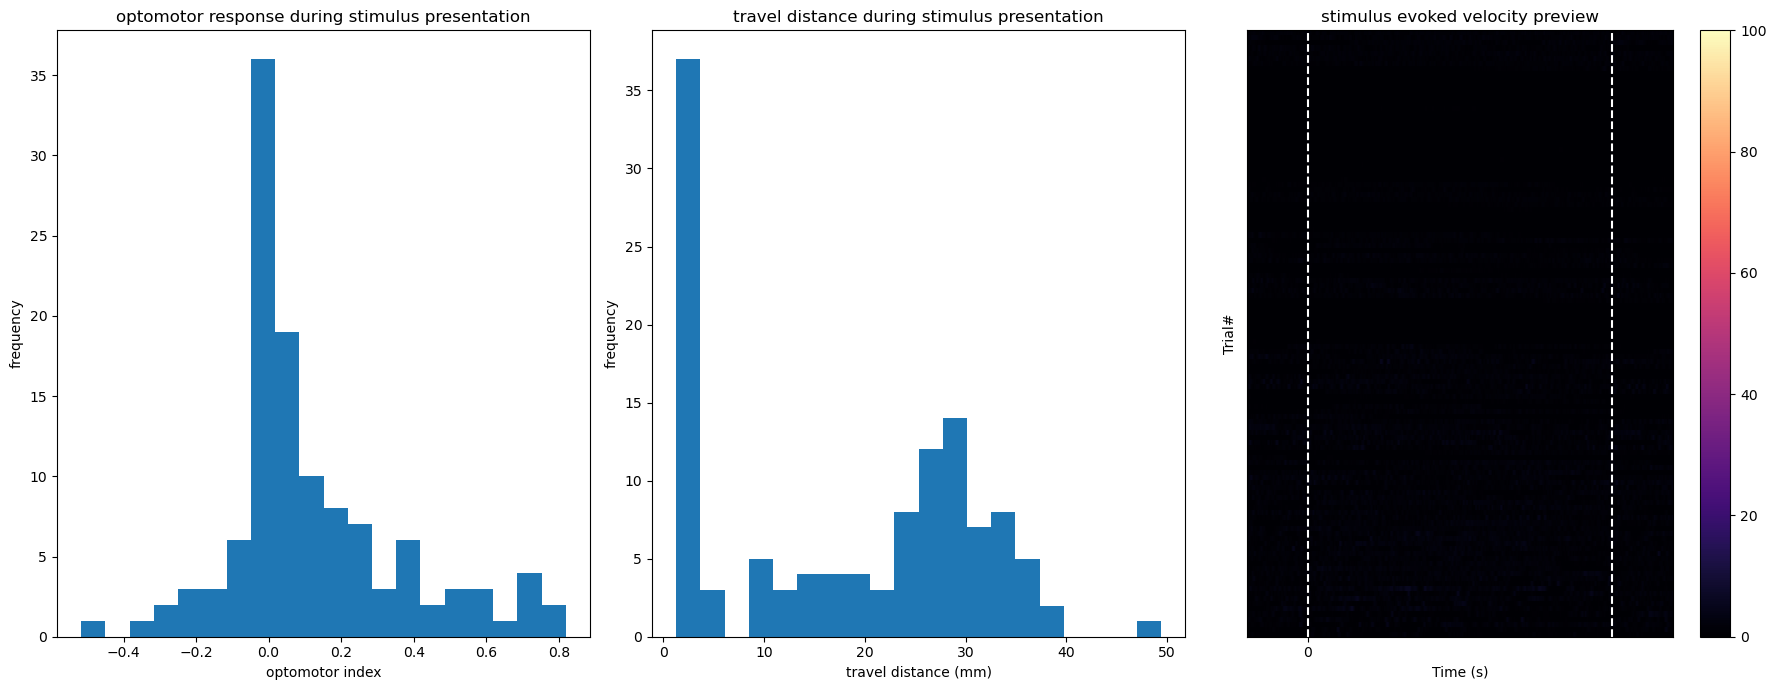

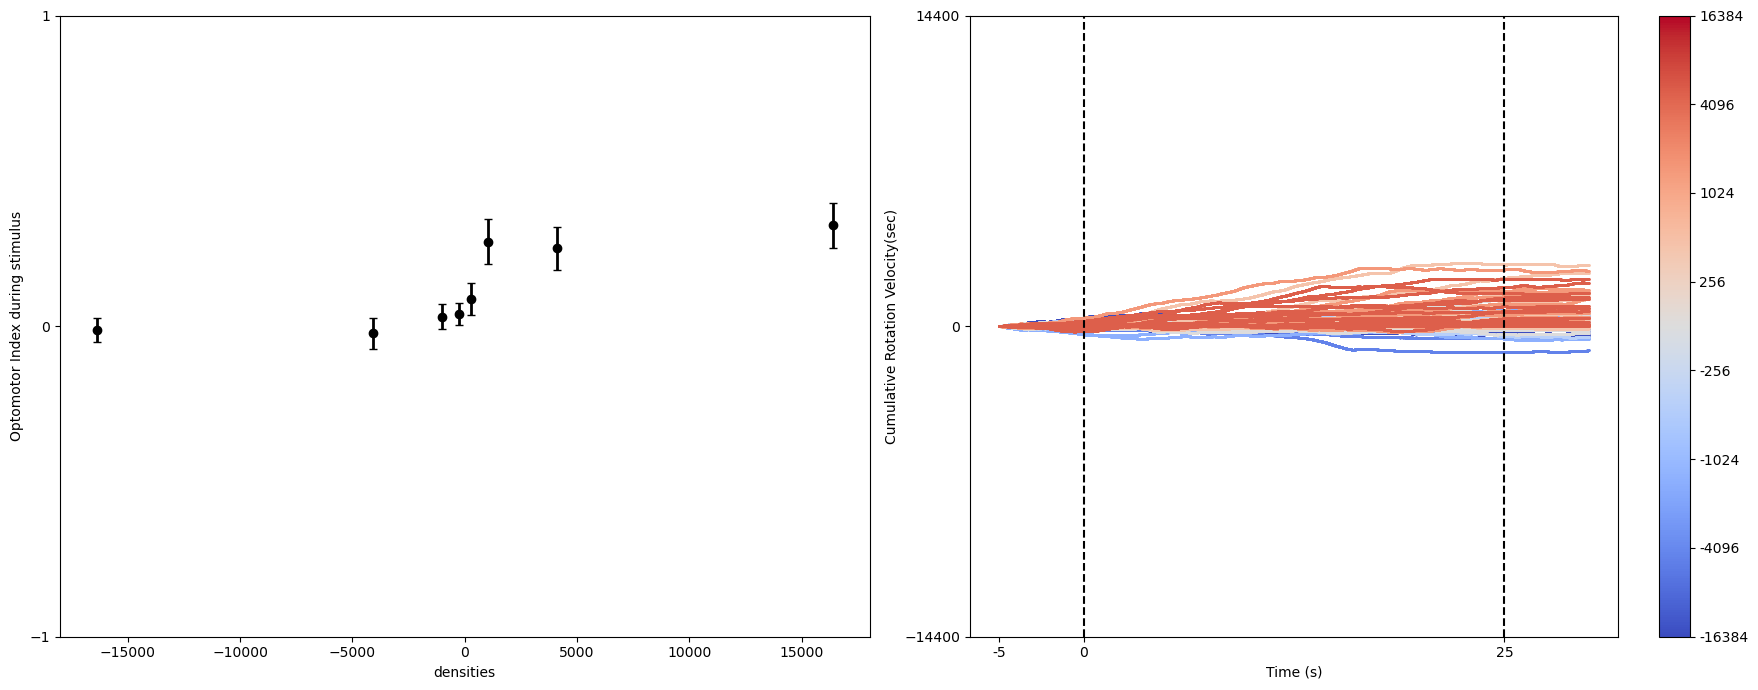

no PD*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22054/220825/densities. Let's leave this programme
no tracking_*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22054/220825/densities. Let's leave this programme
plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


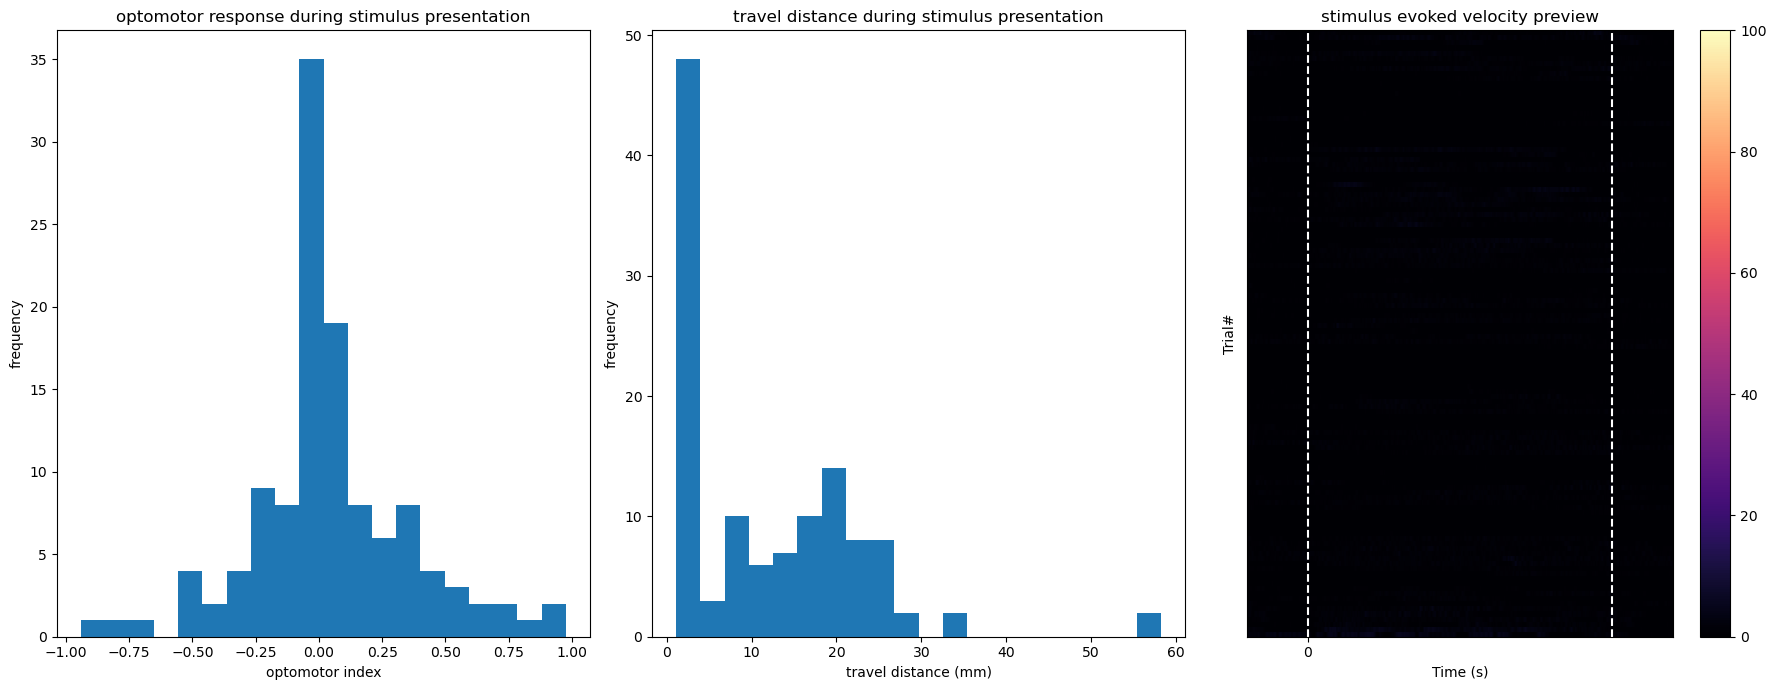

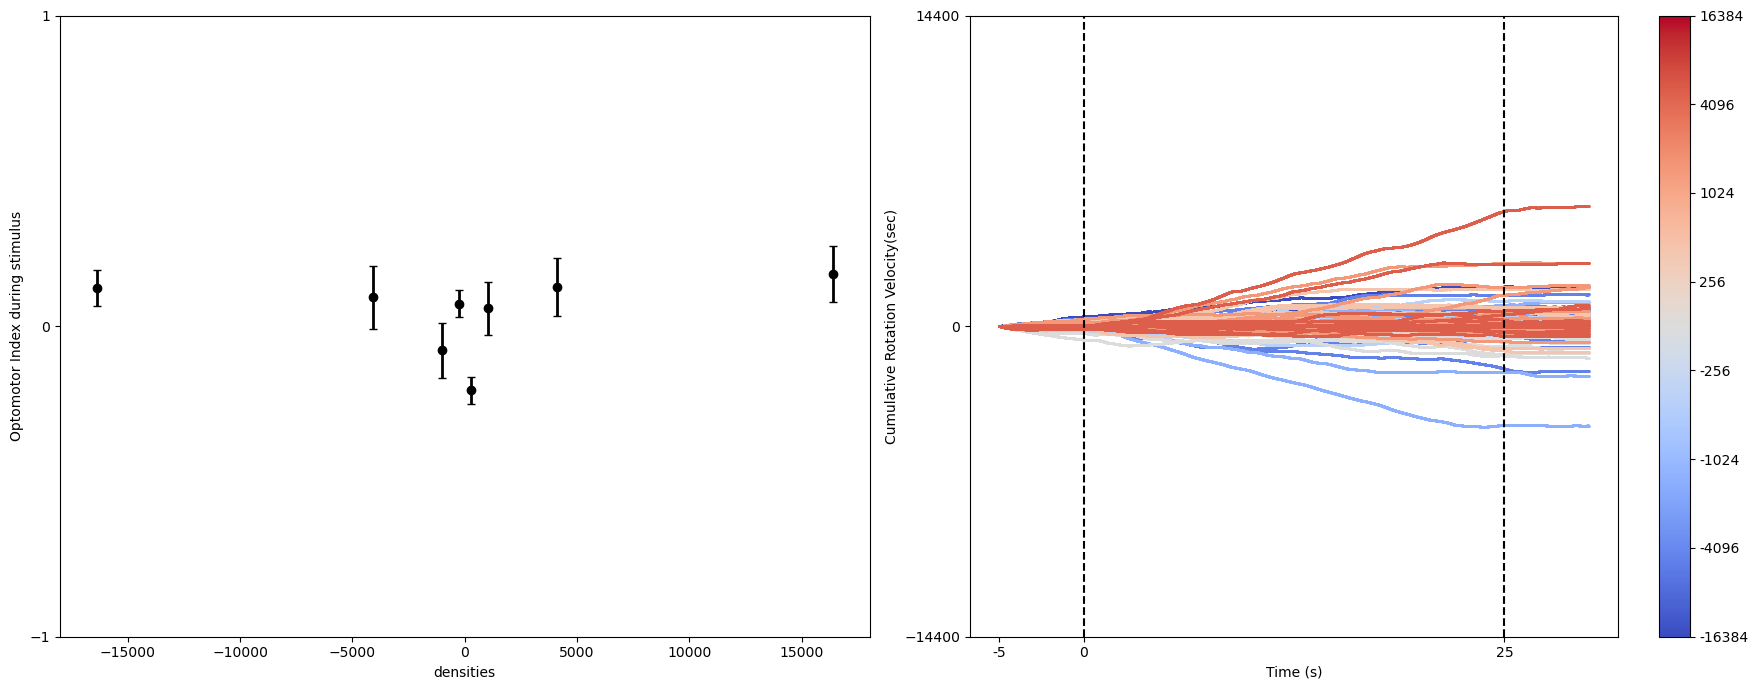

no PD*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22055/220825/densities. Let's leave this programme
no tracking_*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22055/220825/densities. Let's leave this programme
plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


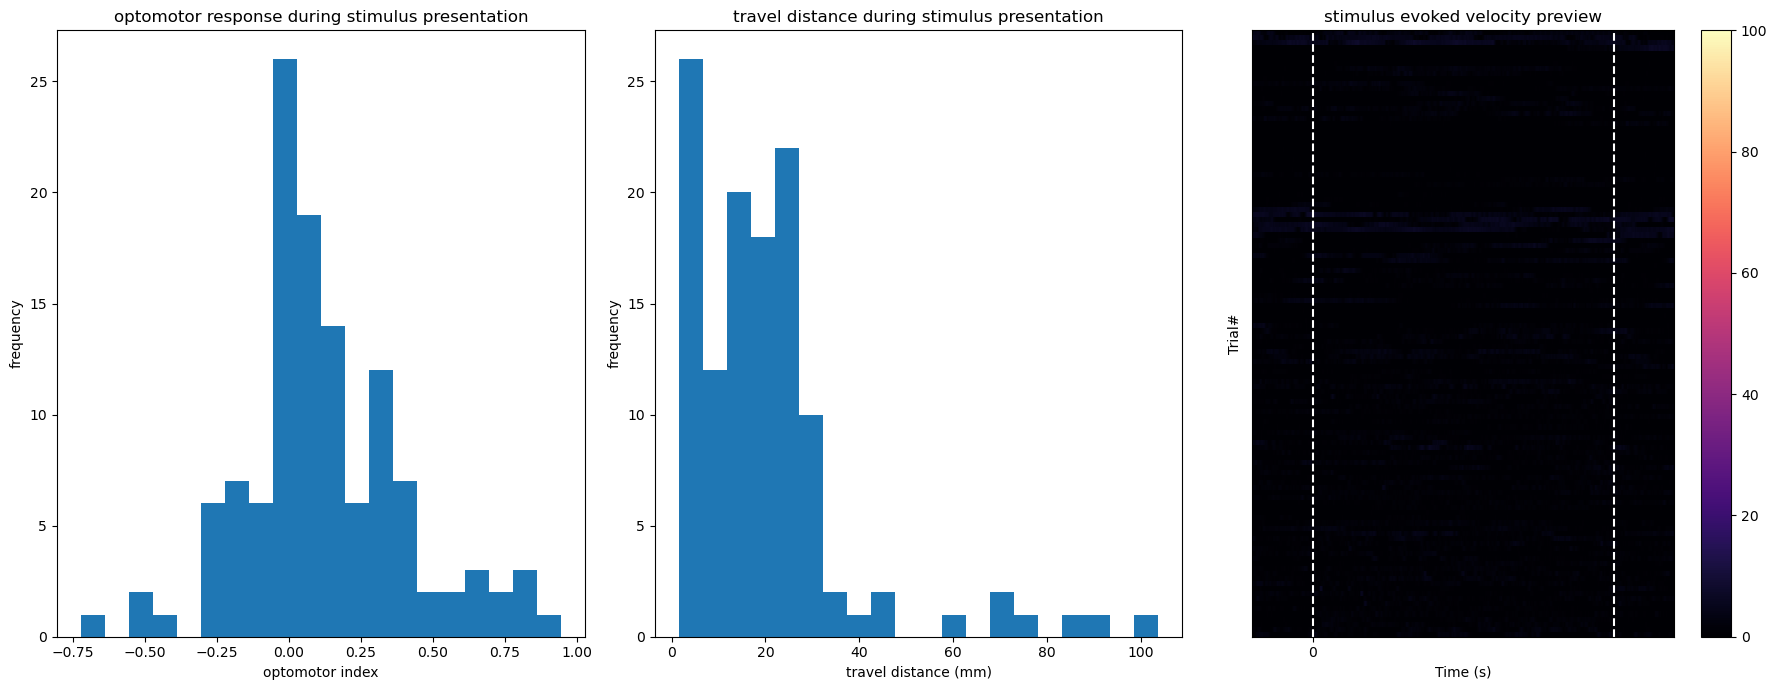

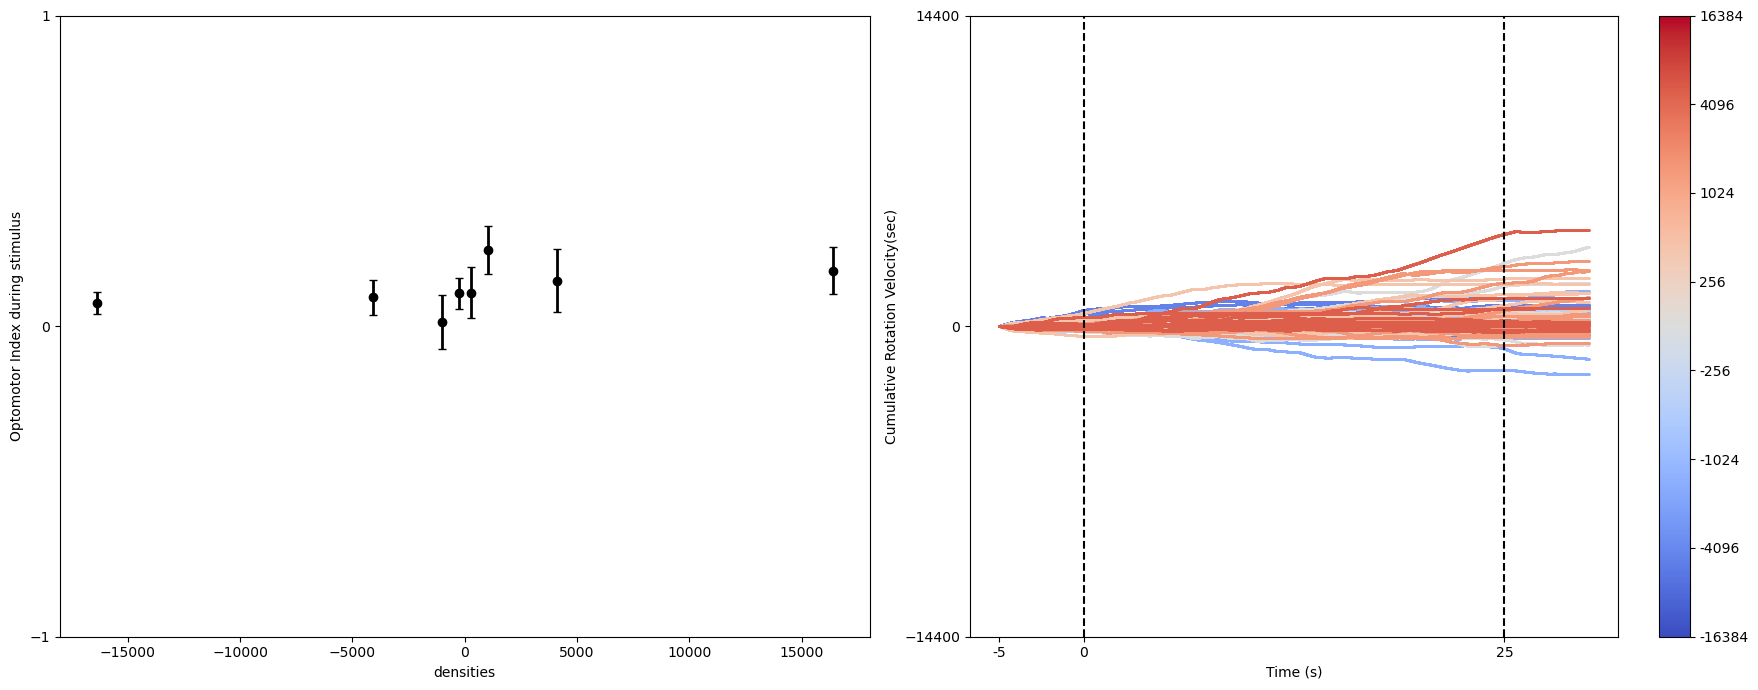

no PD*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22056/220905/densities. Let's leave this programme
no tracking_*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22056/220905/densities. Let's leave this programme
plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


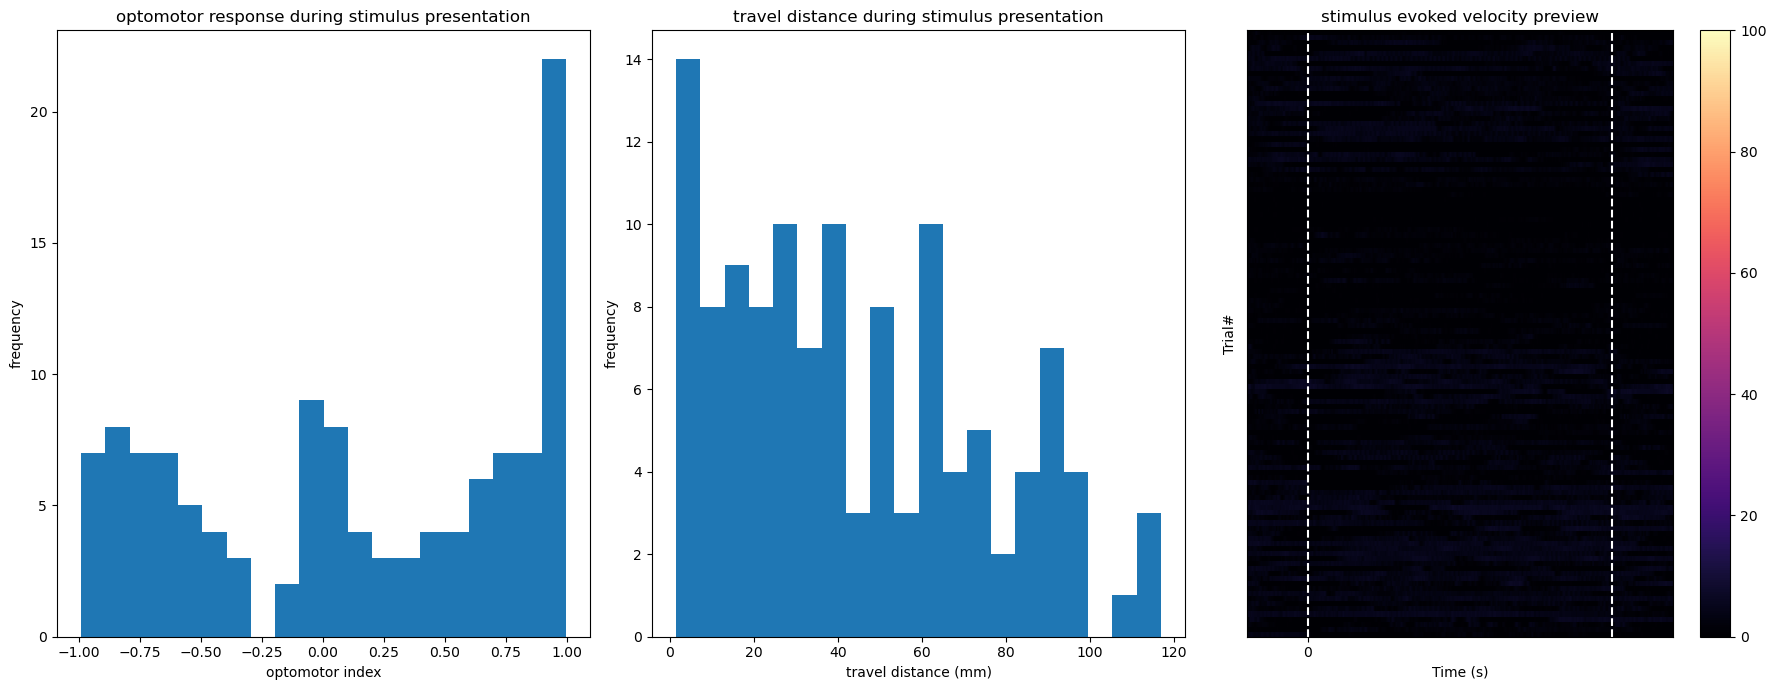

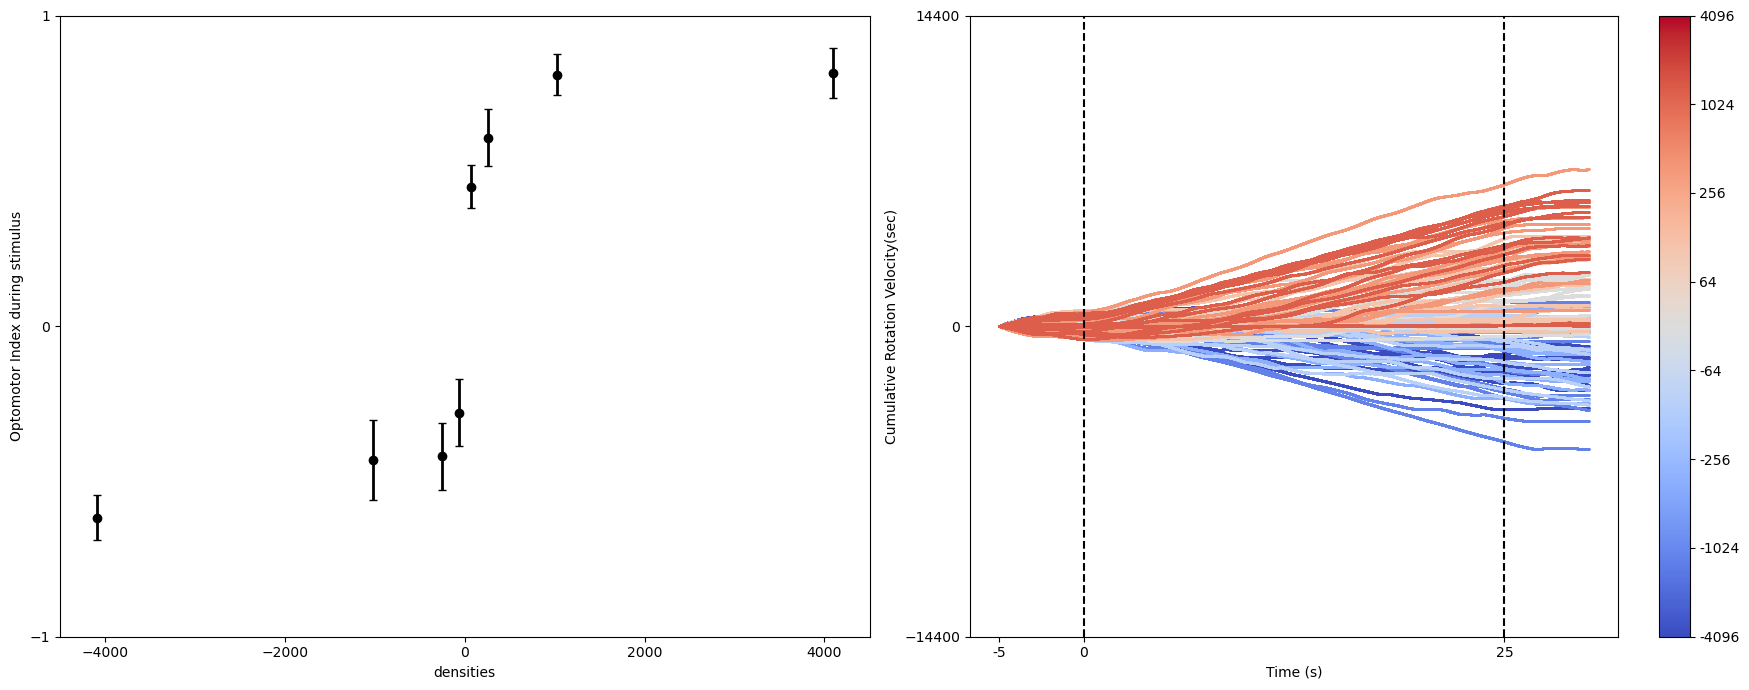

no PD*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22057/220905/densities. Let's leave this programme
no tracking_*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22057/220905/densities. Let's leave this programme
plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


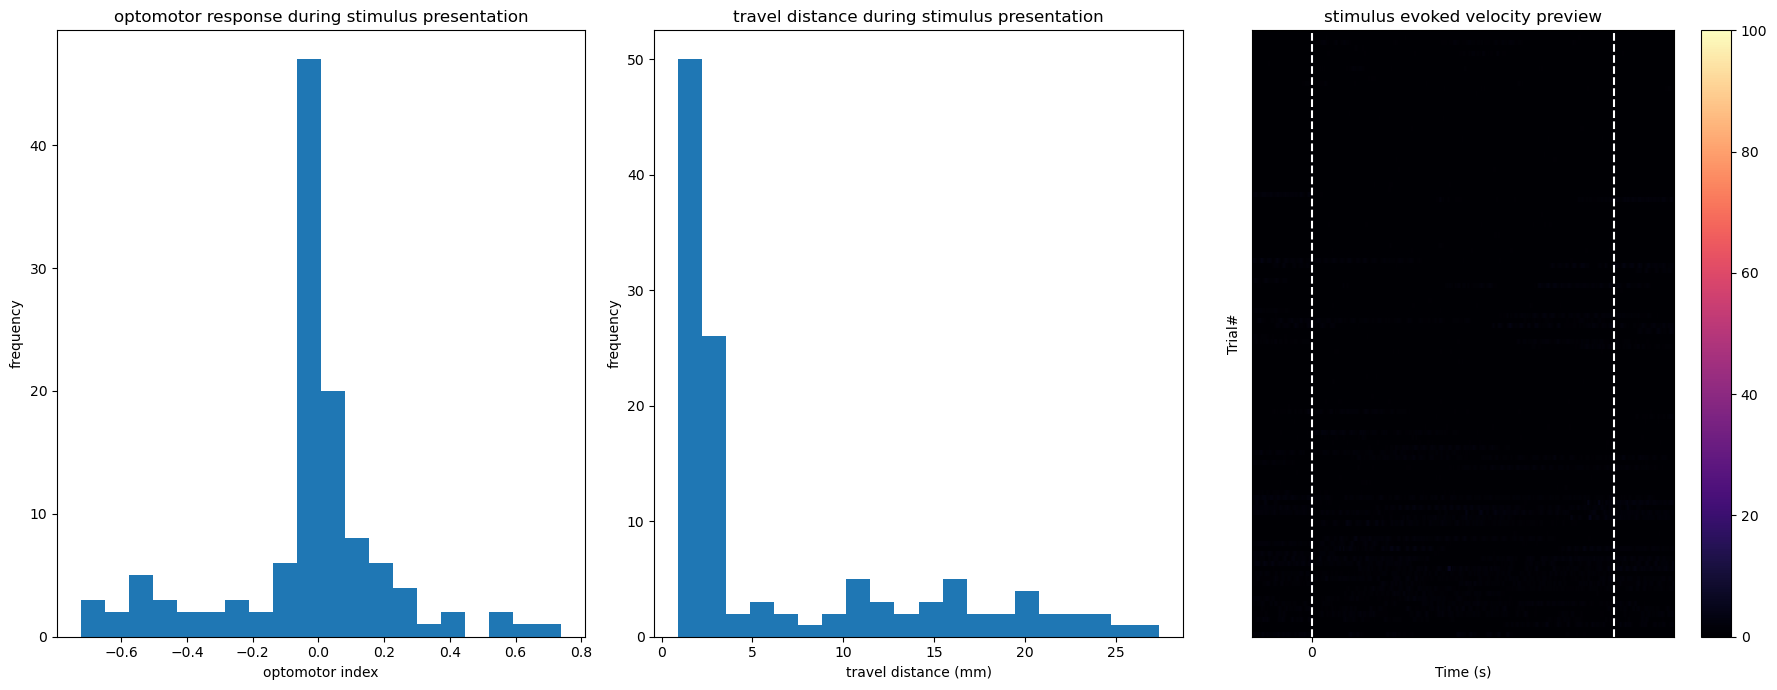

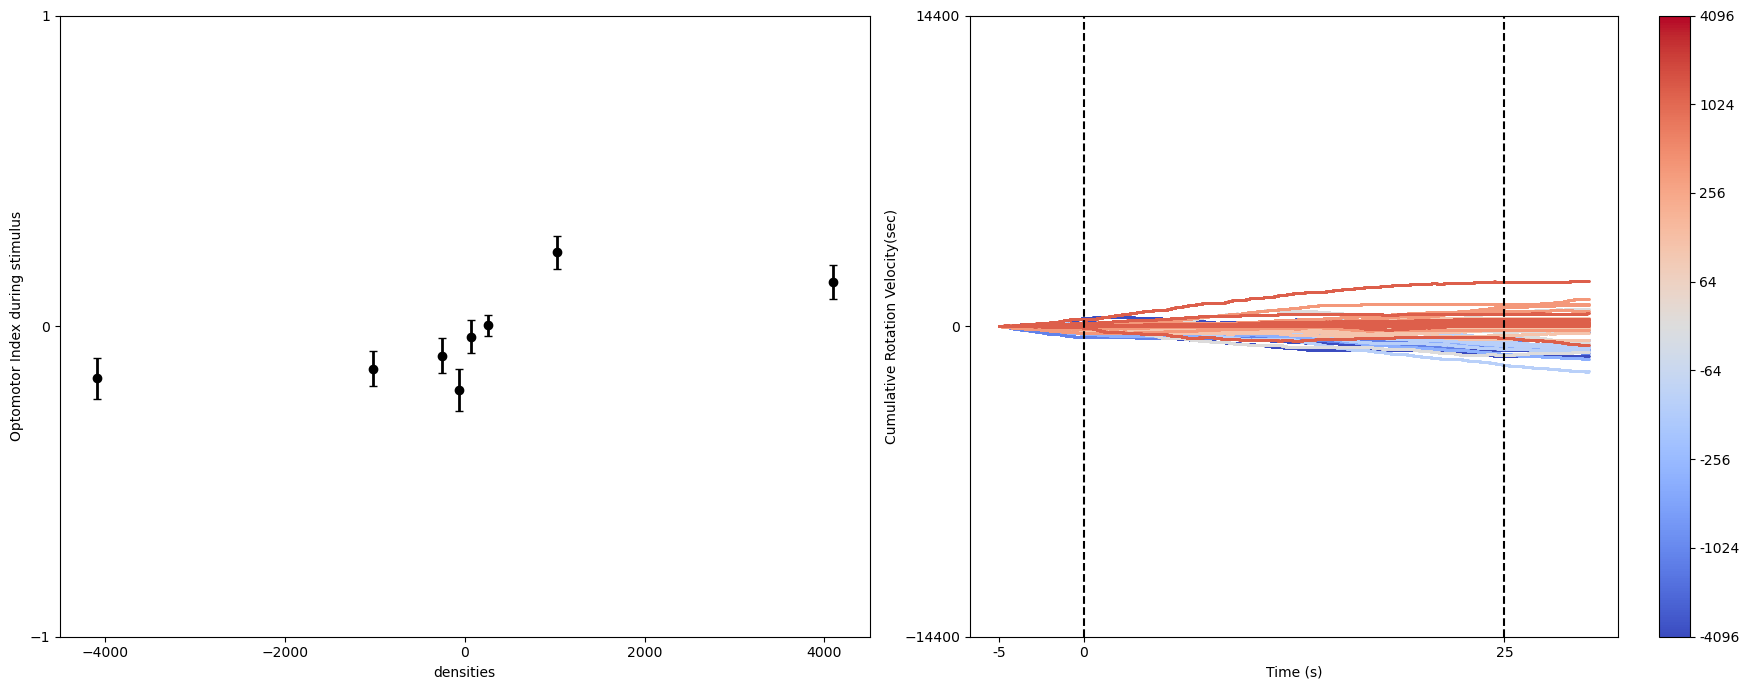

no PD*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22058/220905/densities. Let's leave this programme
no tracking_*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22058/220905/densities. Let's leave this programme
plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


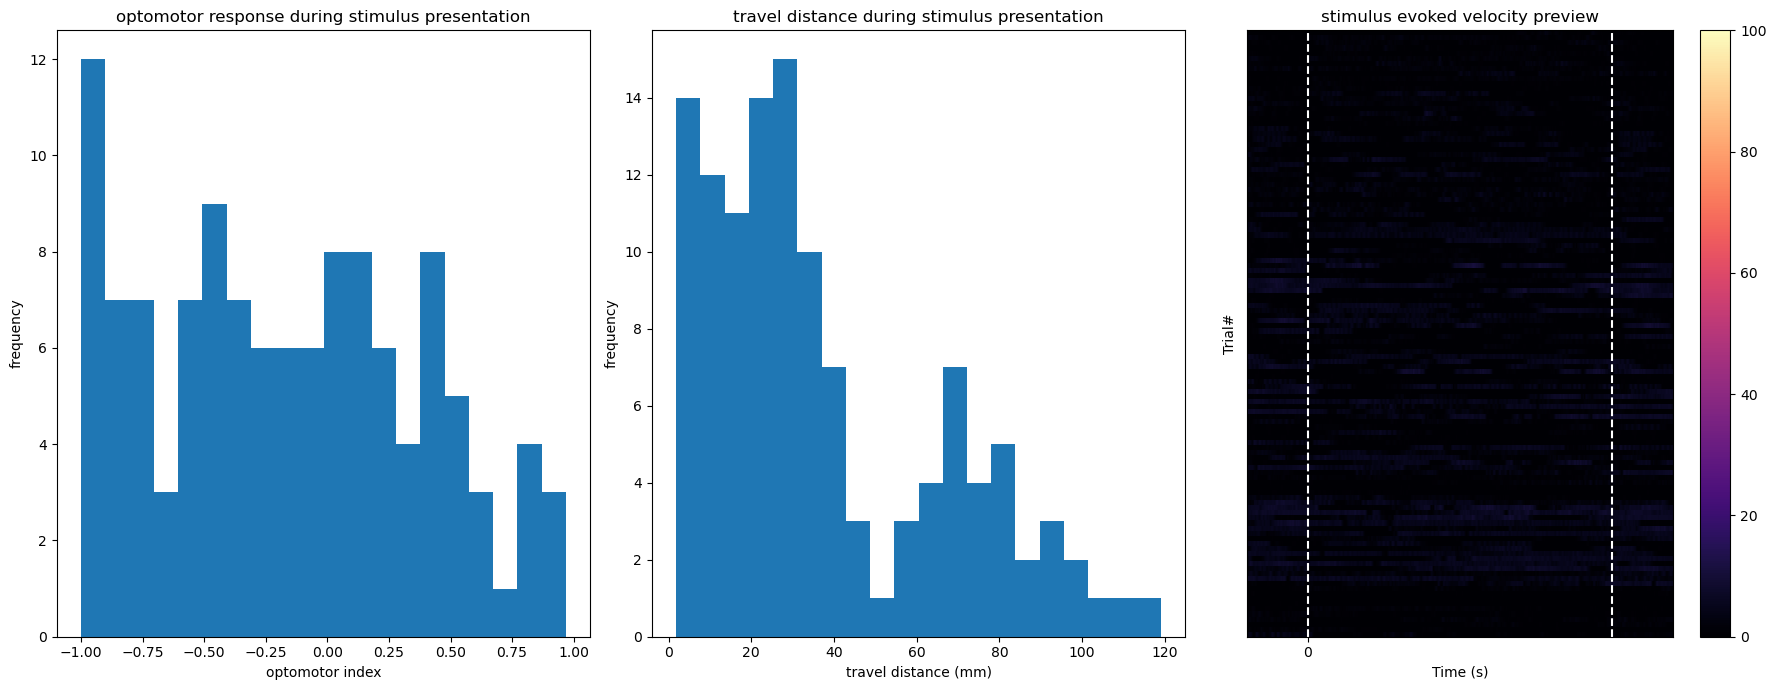

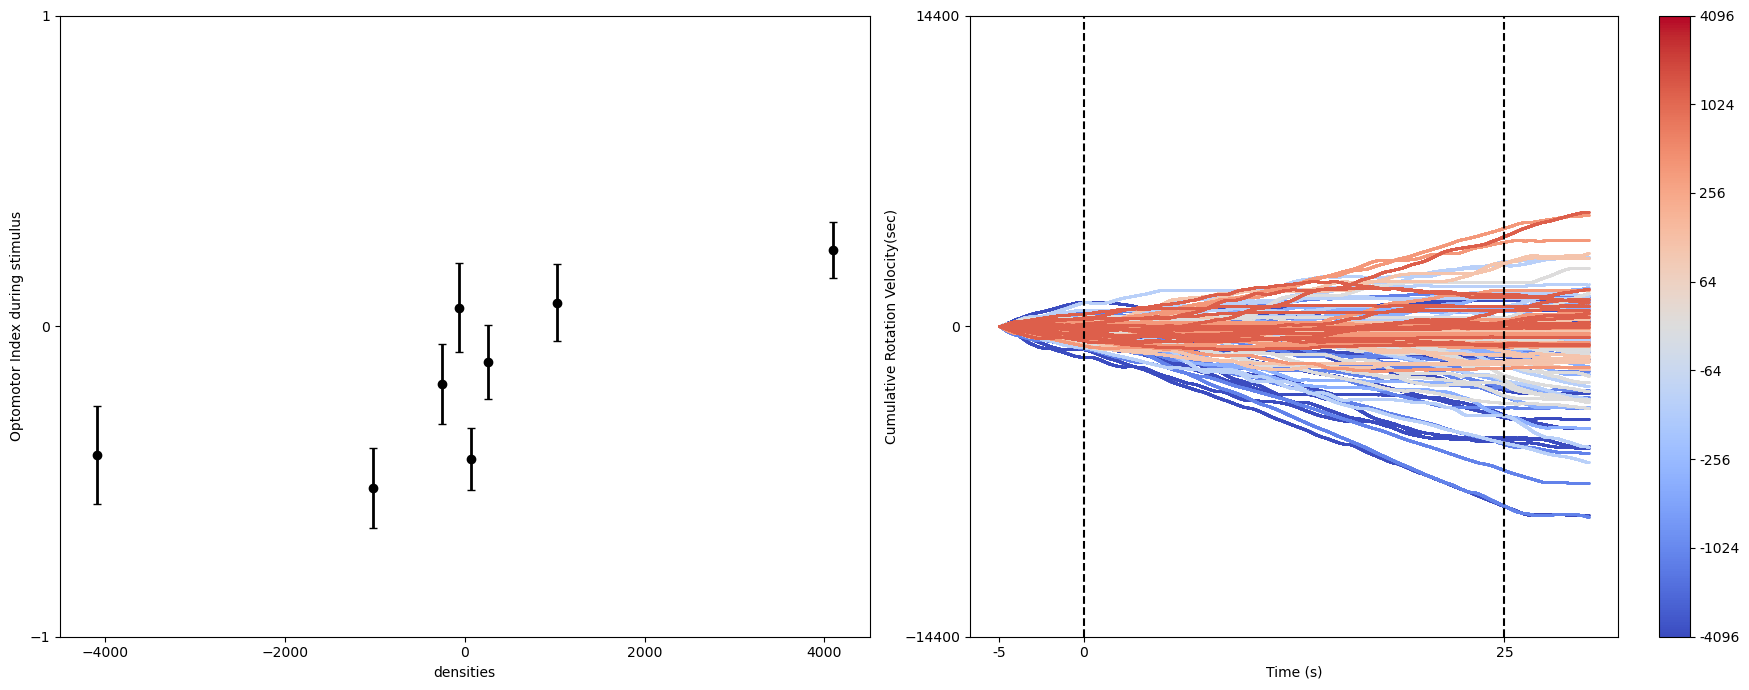

no PD*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22059/220906/densities. Let's leave this programme
no tracking_*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22059/220906/densities. Let's leave this programme
plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


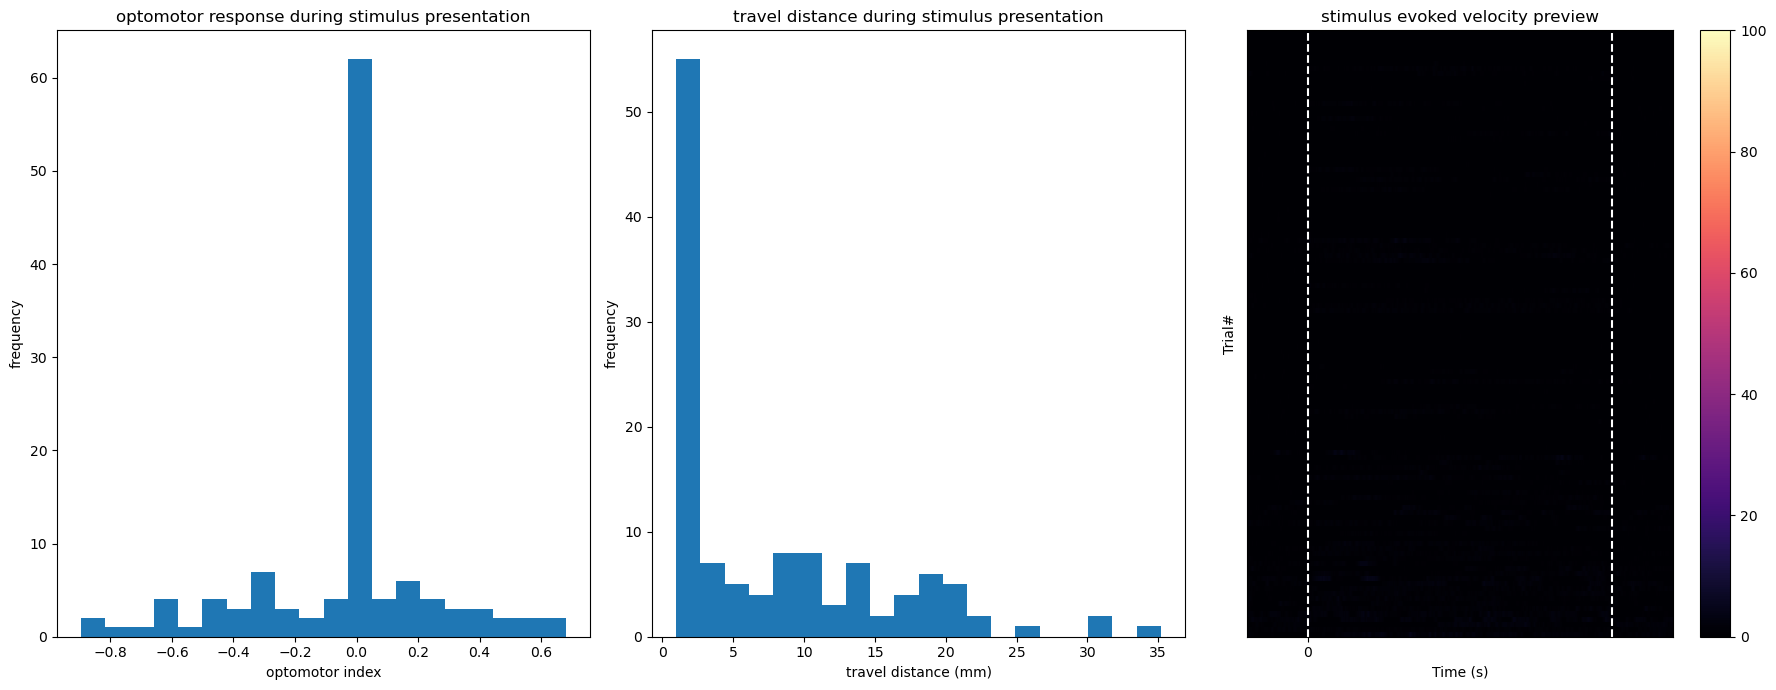

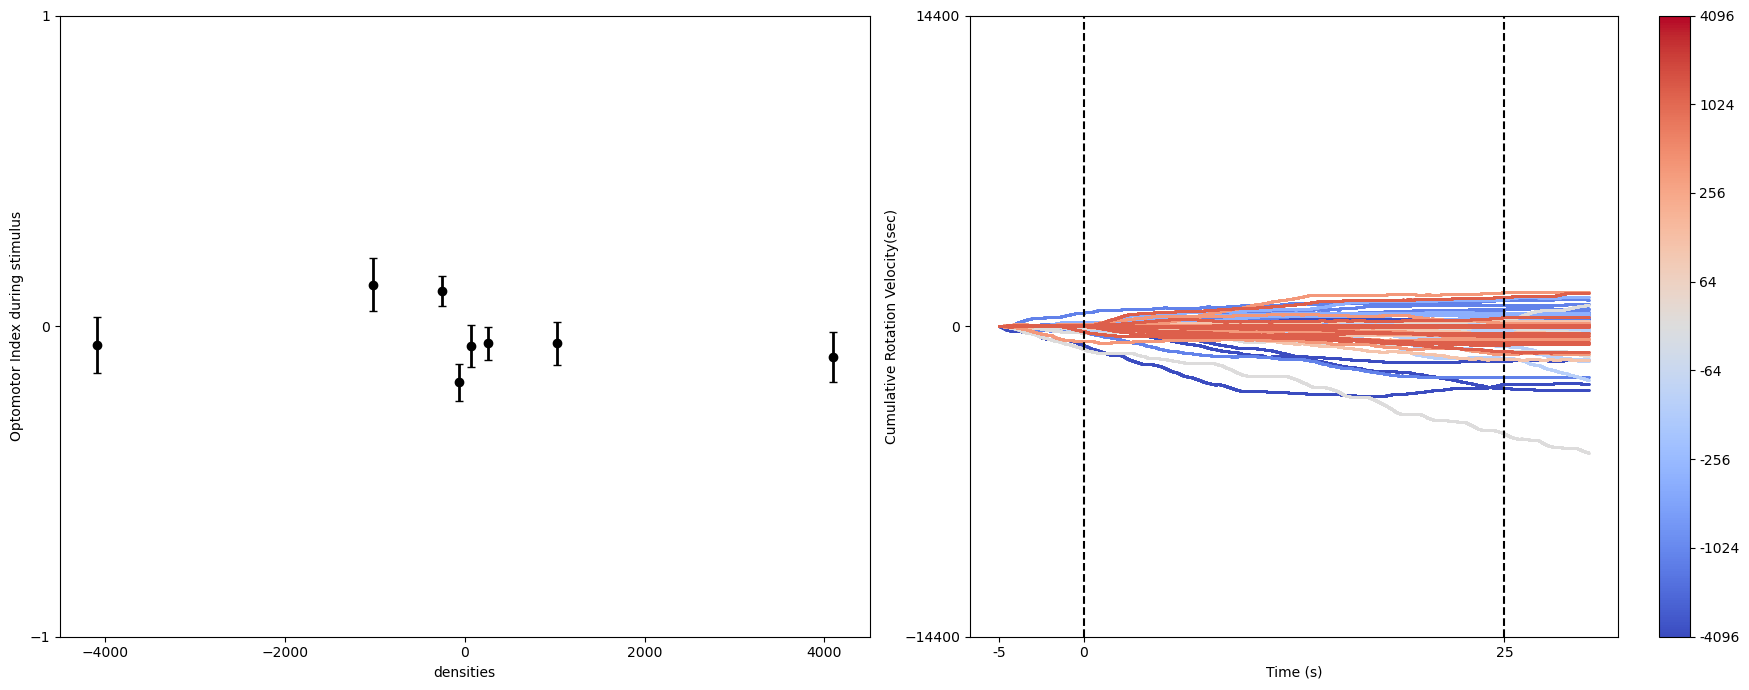

no PD*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22060/220906/densities. Let's leave this programme
no tracking_*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22060/220906/densities. Let's leave this programme
plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


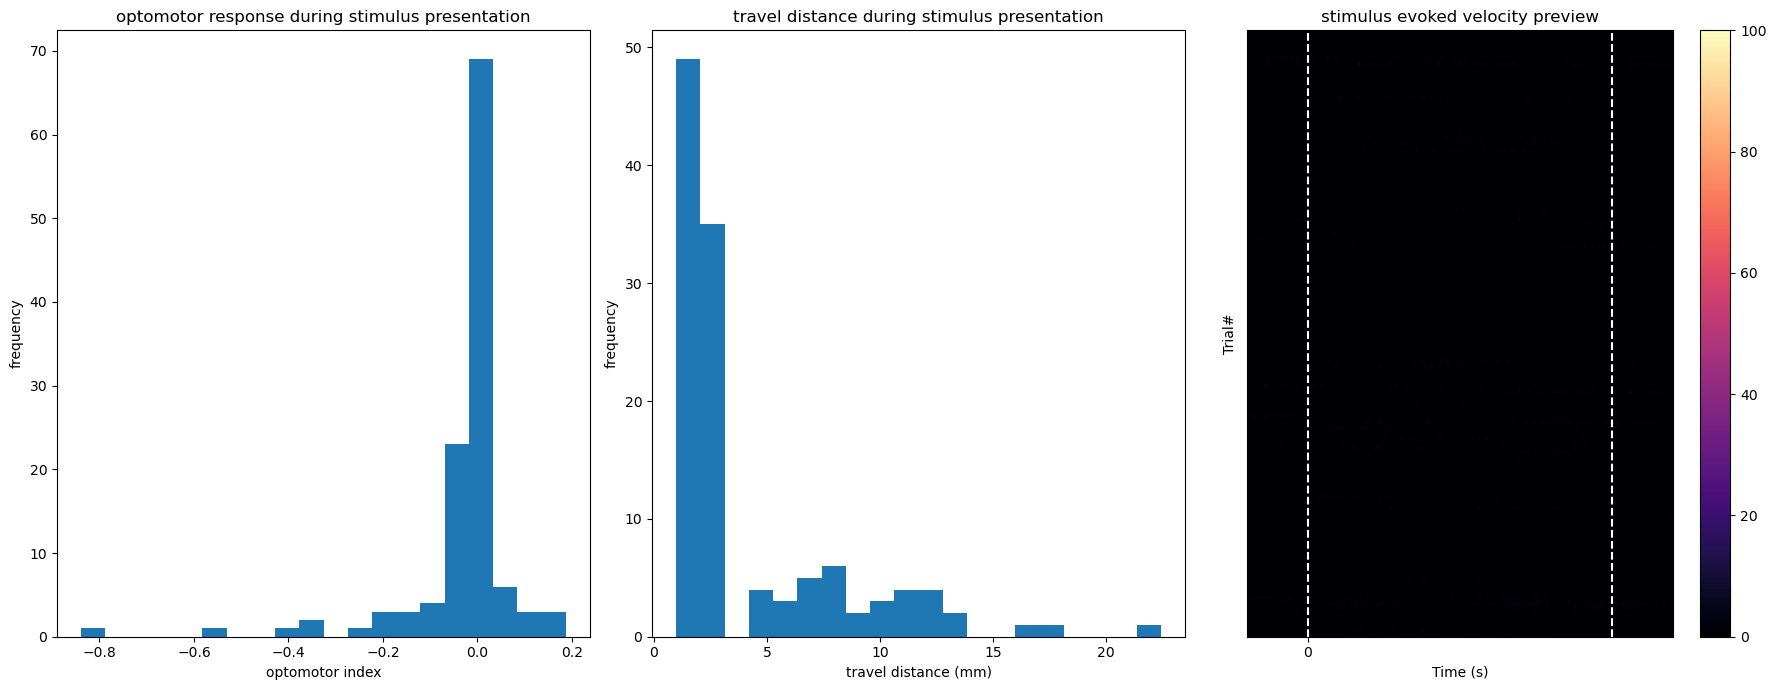

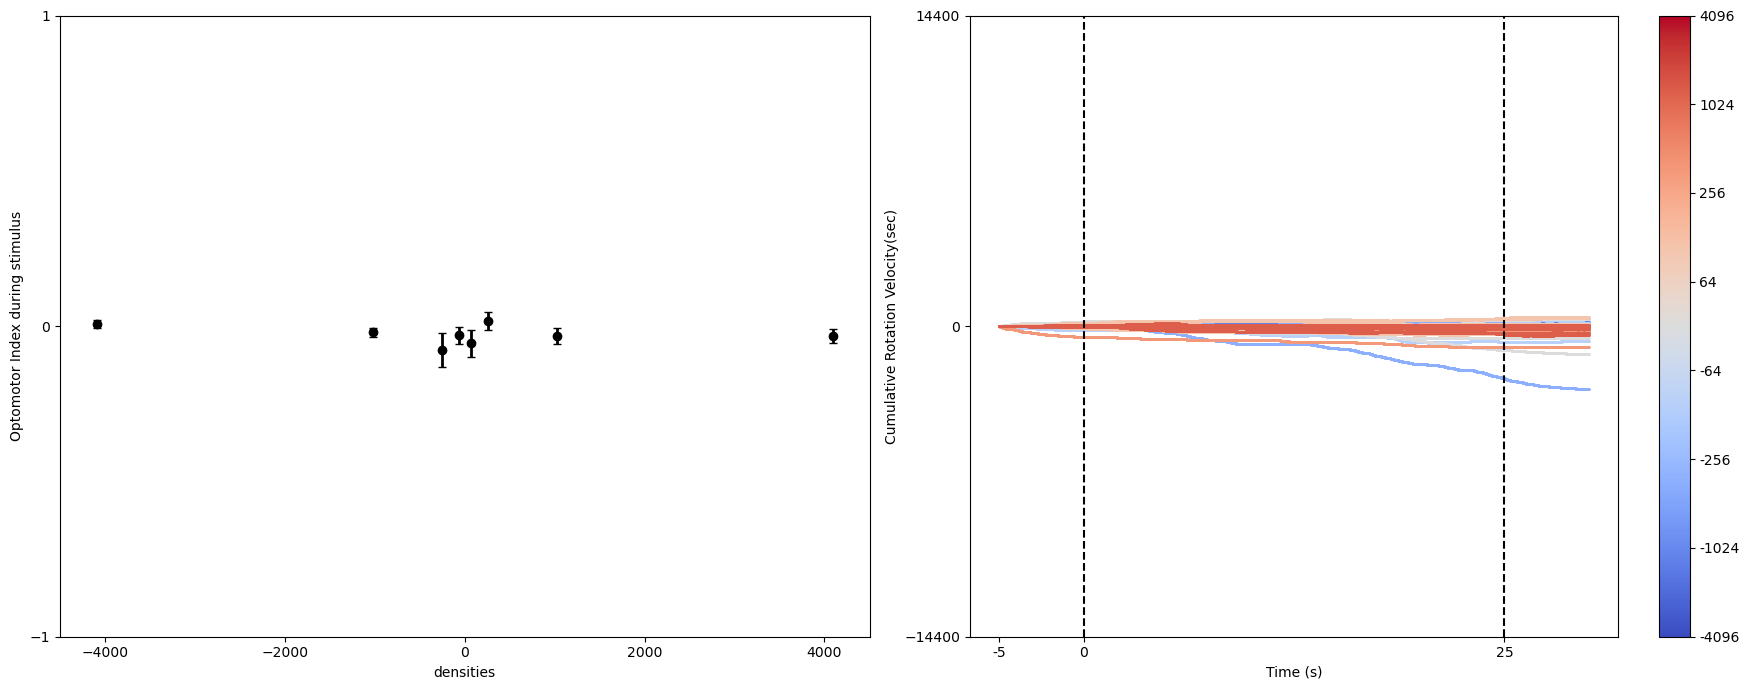

no PD*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22061/220906/densities. Let's leave this programme
no tracking_*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22061/220906/densities. Let's leave this programme
plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


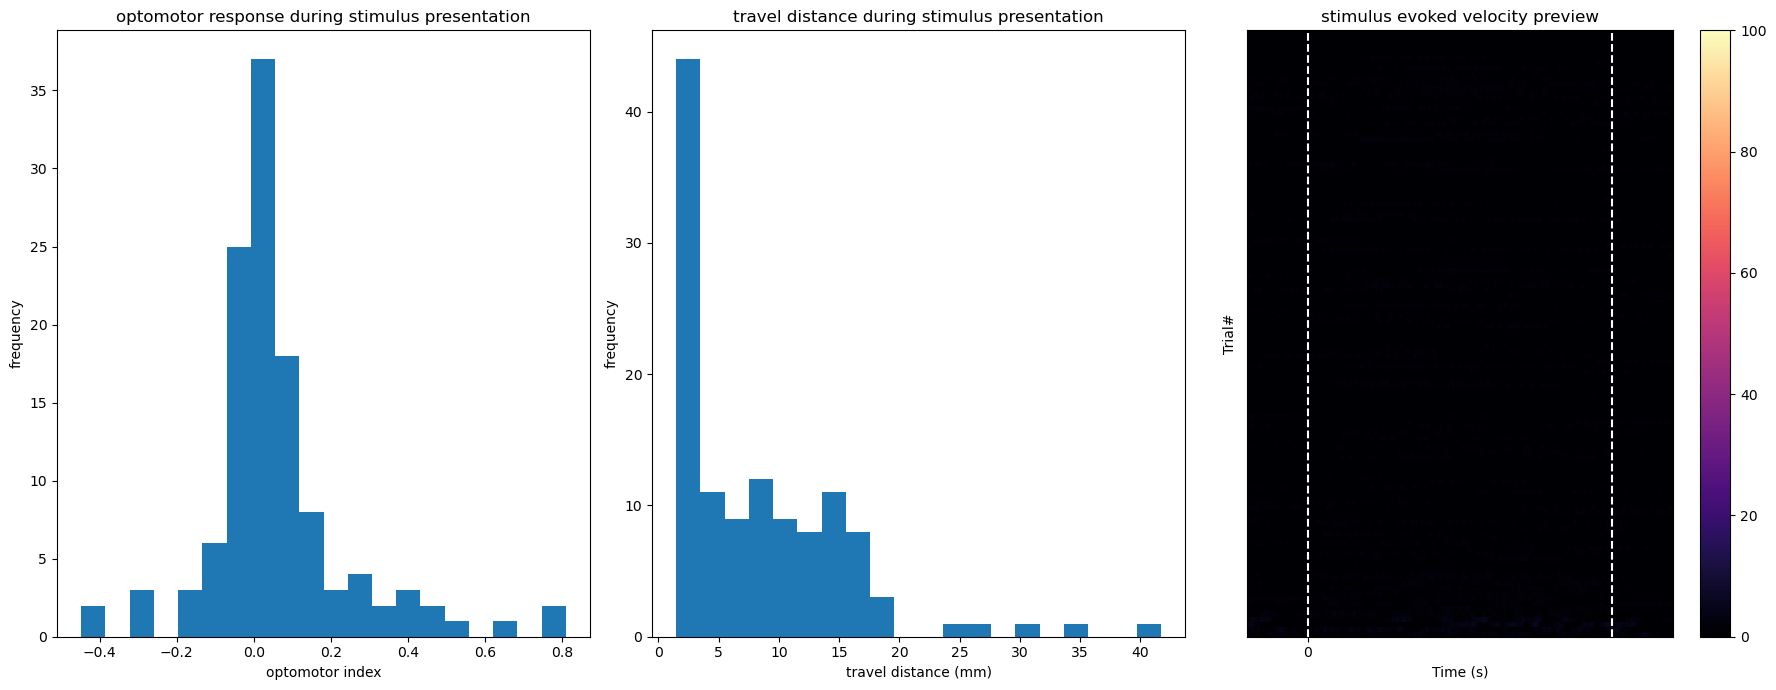

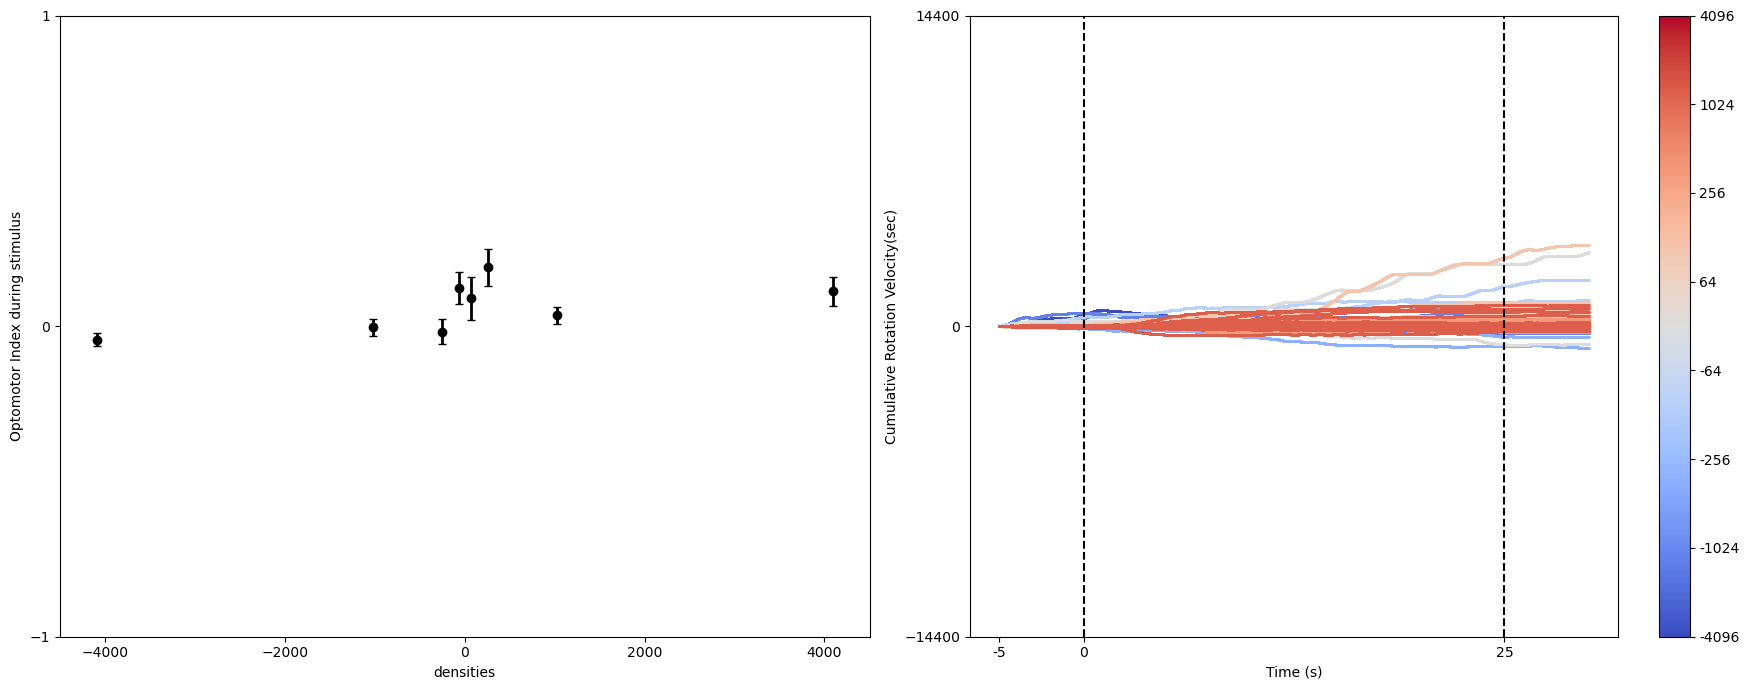

no PD*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22062/220907/densities. Let's leave this programme
no tracking_*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22062/220907/densities. Let's leave this programme
plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


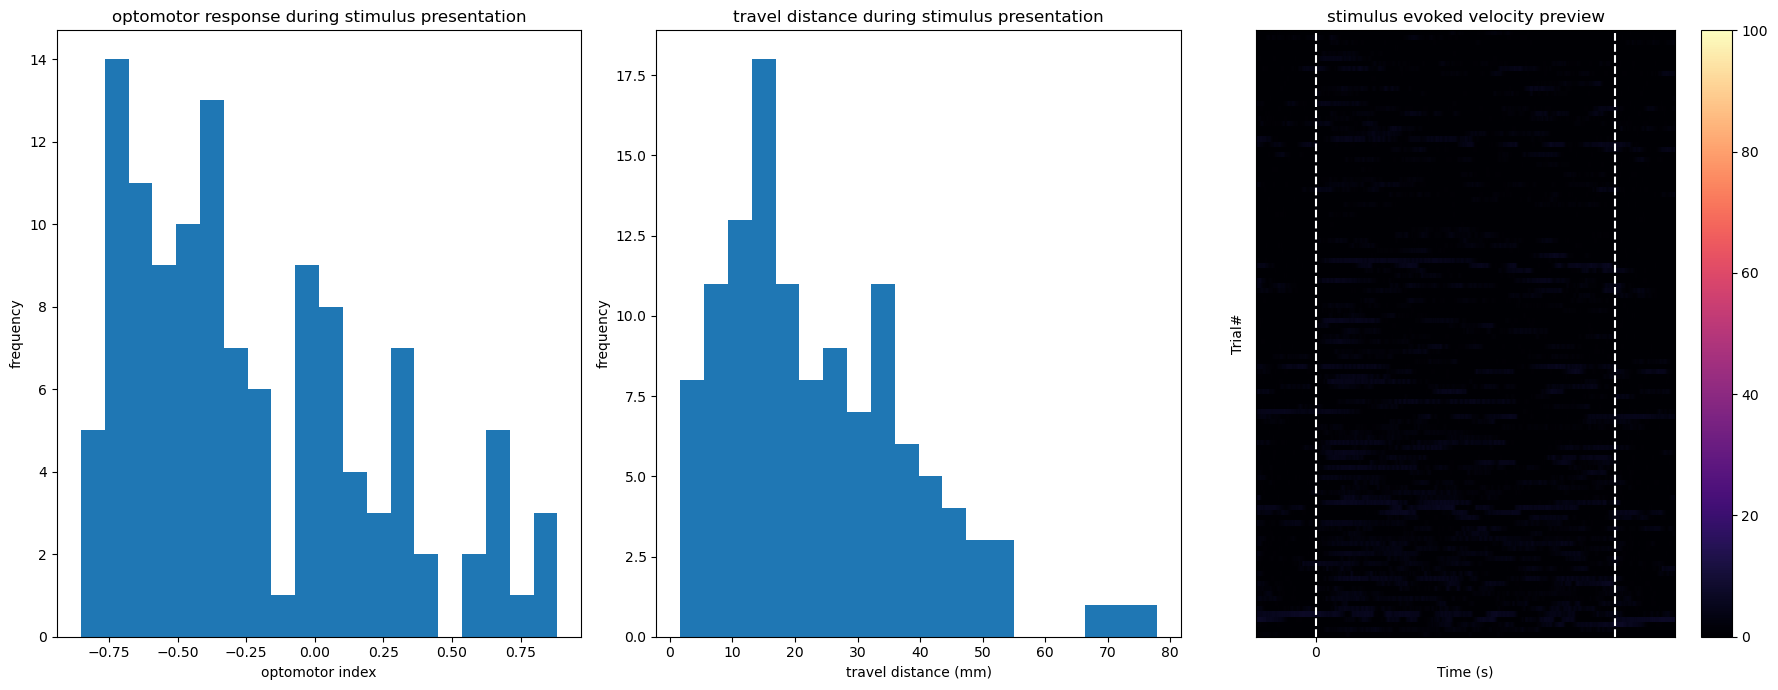

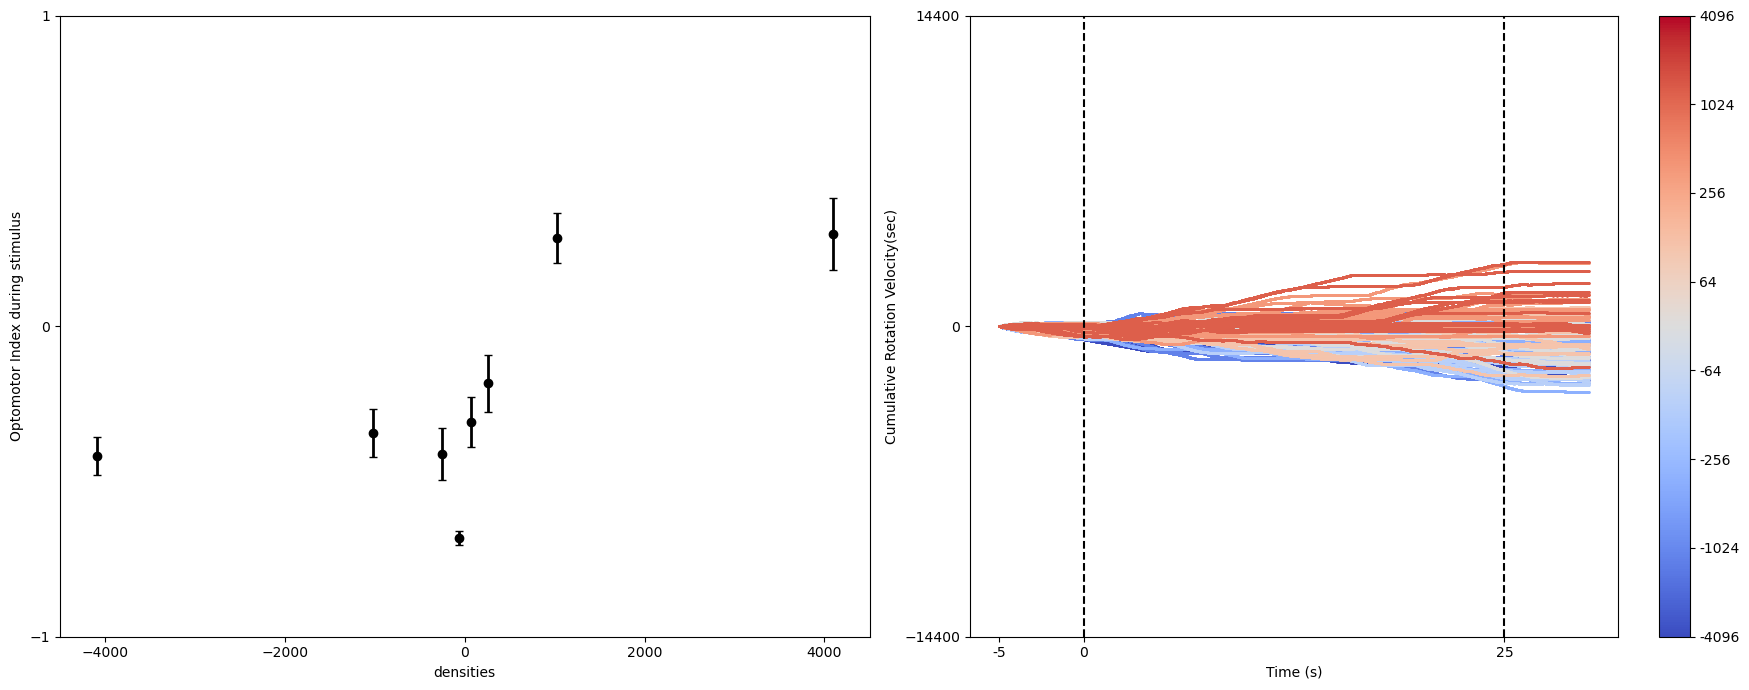

no PD*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22063/220907/densities. Let's leave this programme
no tracking_*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22063/220907/densities. Let's leave this programme
plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


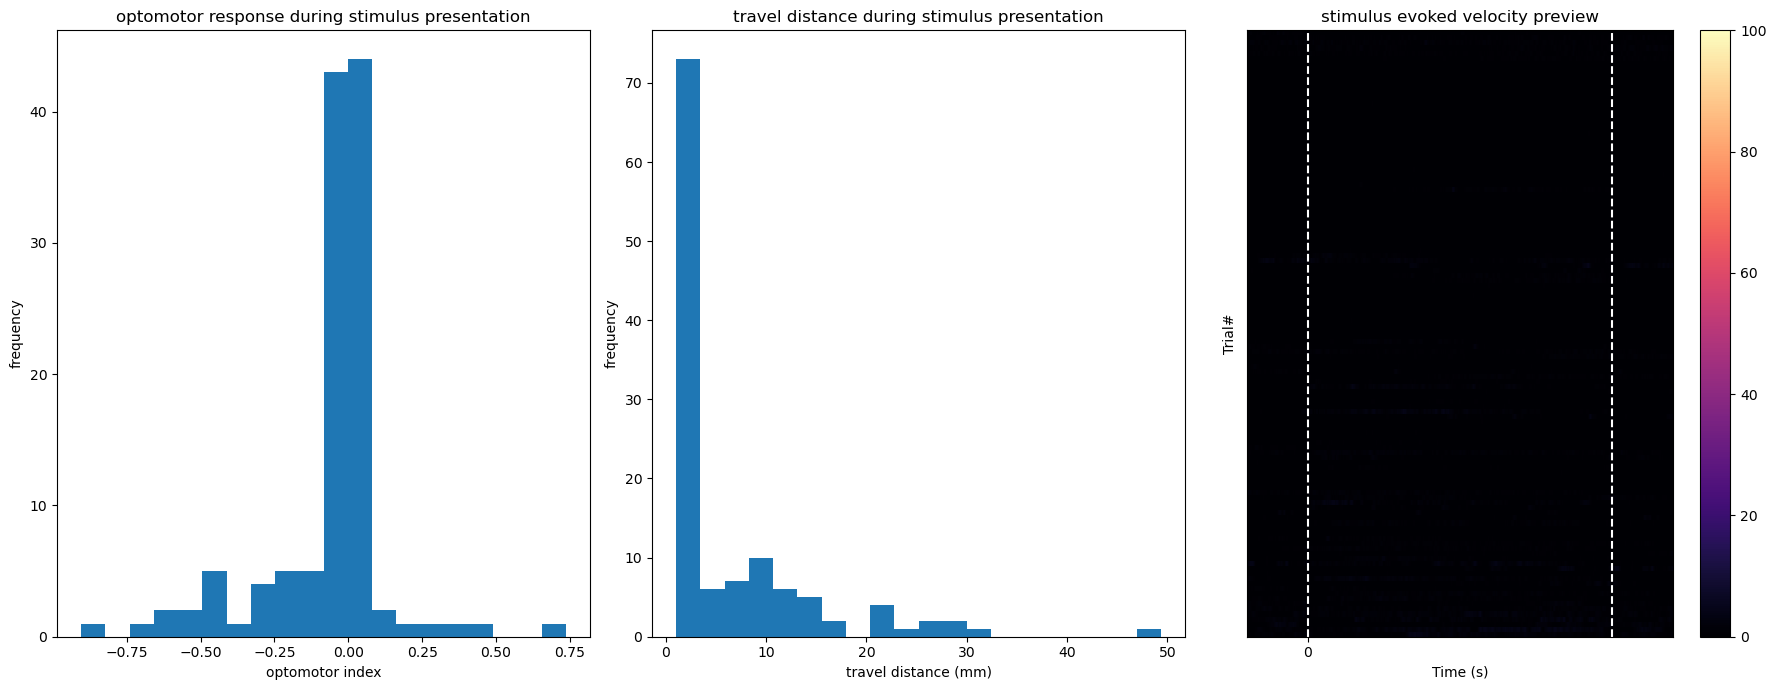

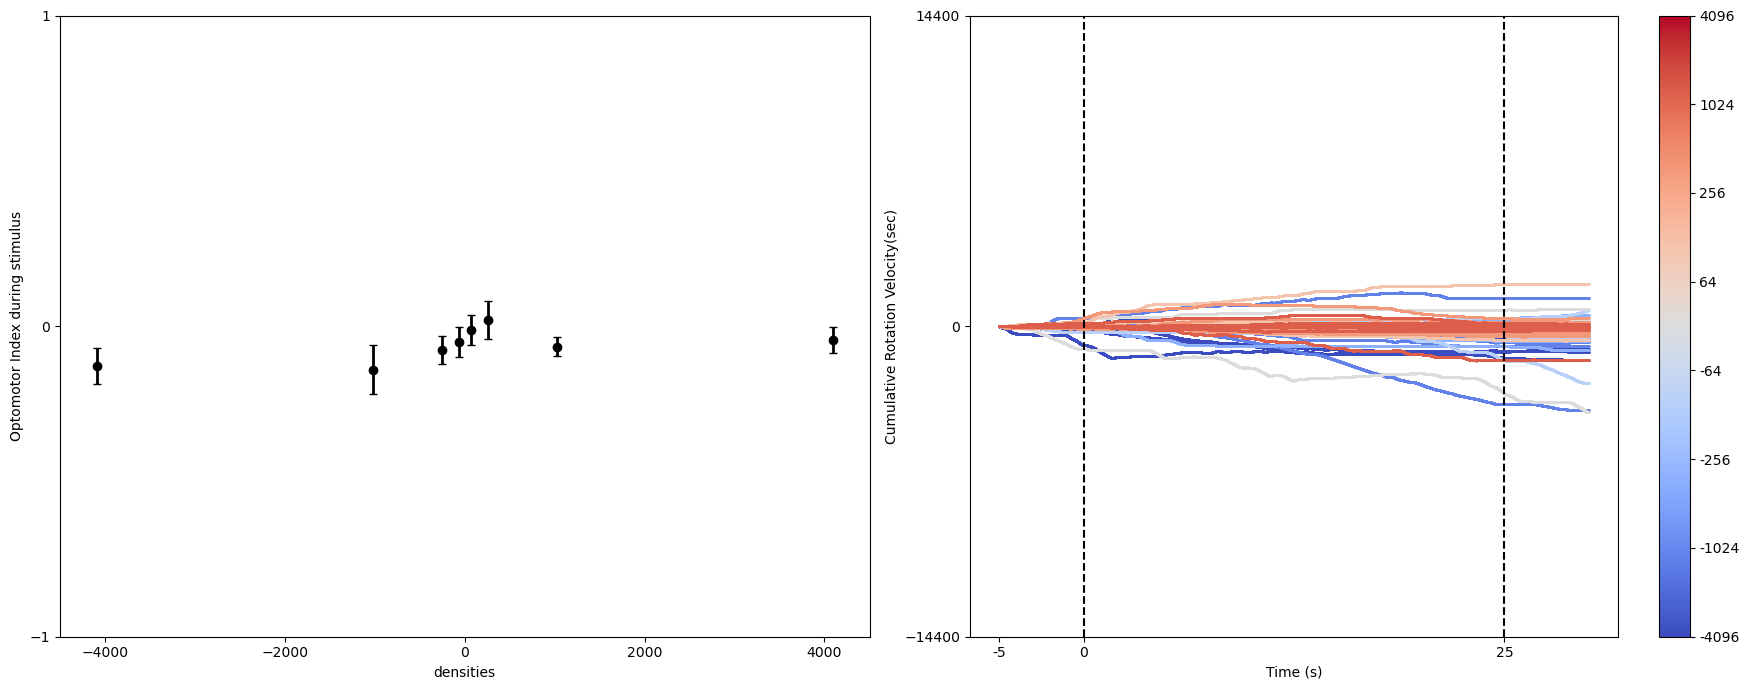

no PD*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22065/220907/densities. Let's leave this programme
no tracking_*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22065/220907/densities. Let's leave this programme
plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


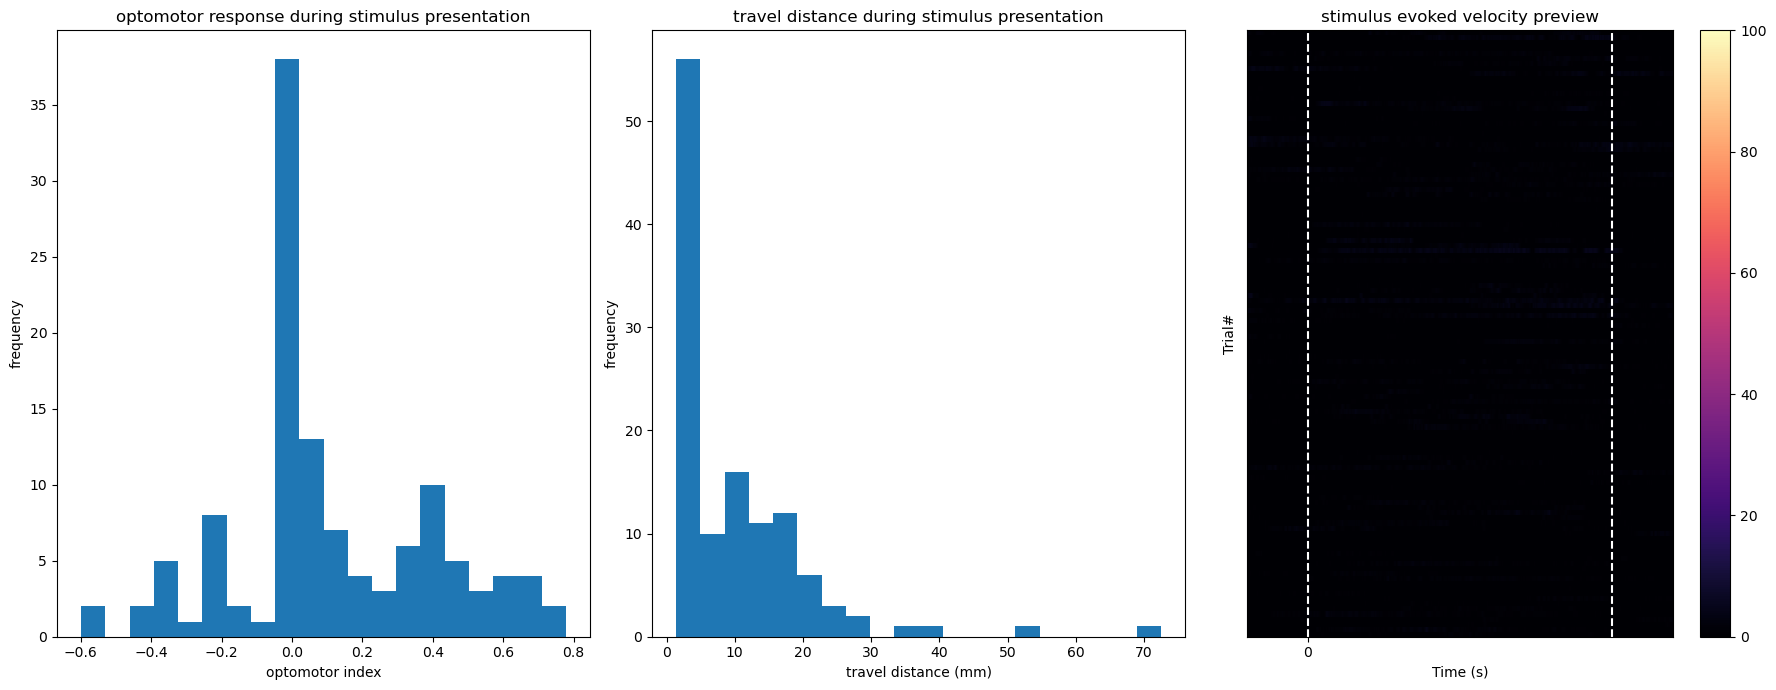

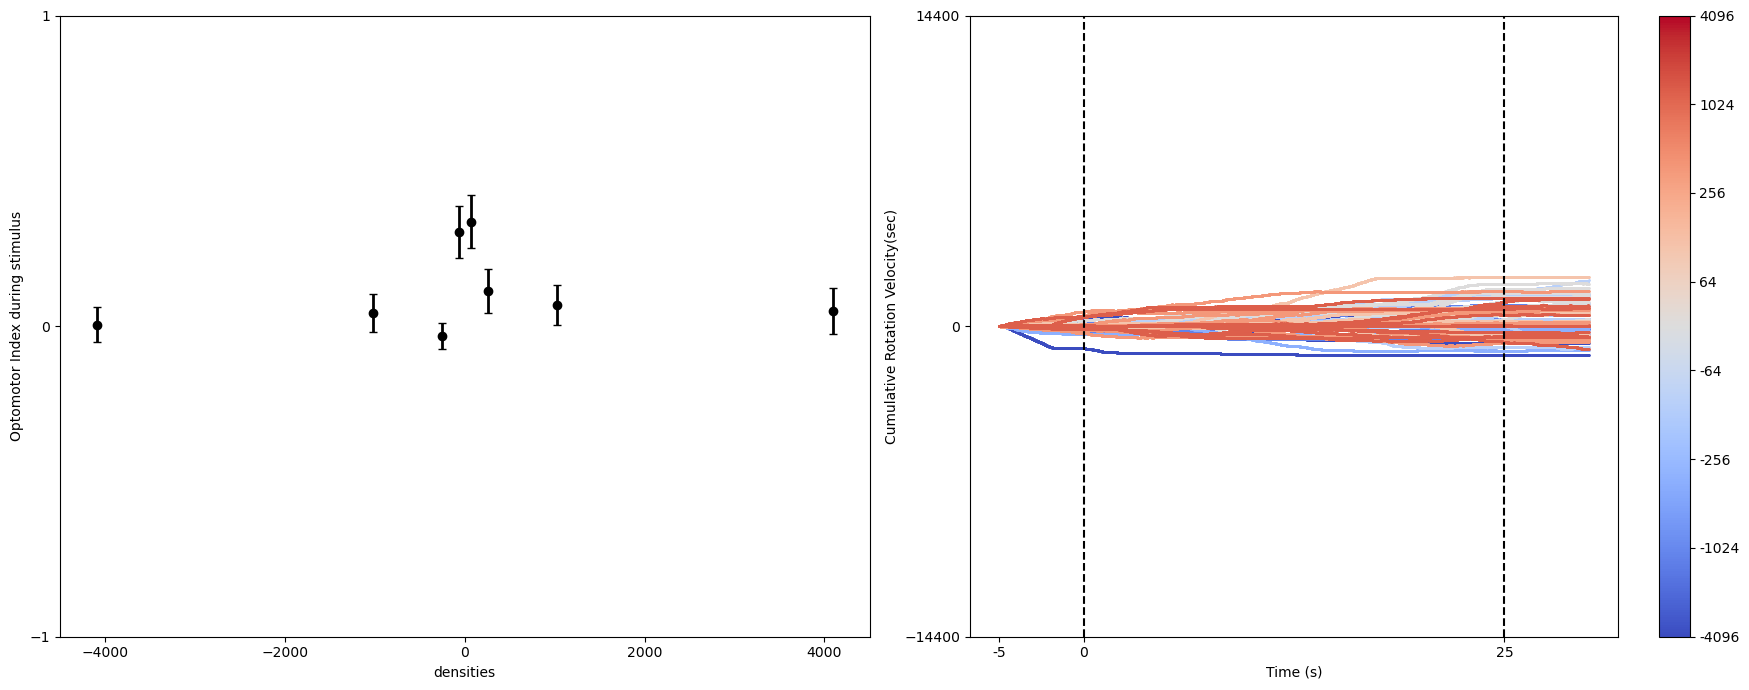

no PD*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22066/220907/densities. Let's leave this programme
no tracking_*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22066/220907/densities. Let's leave this programme
plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


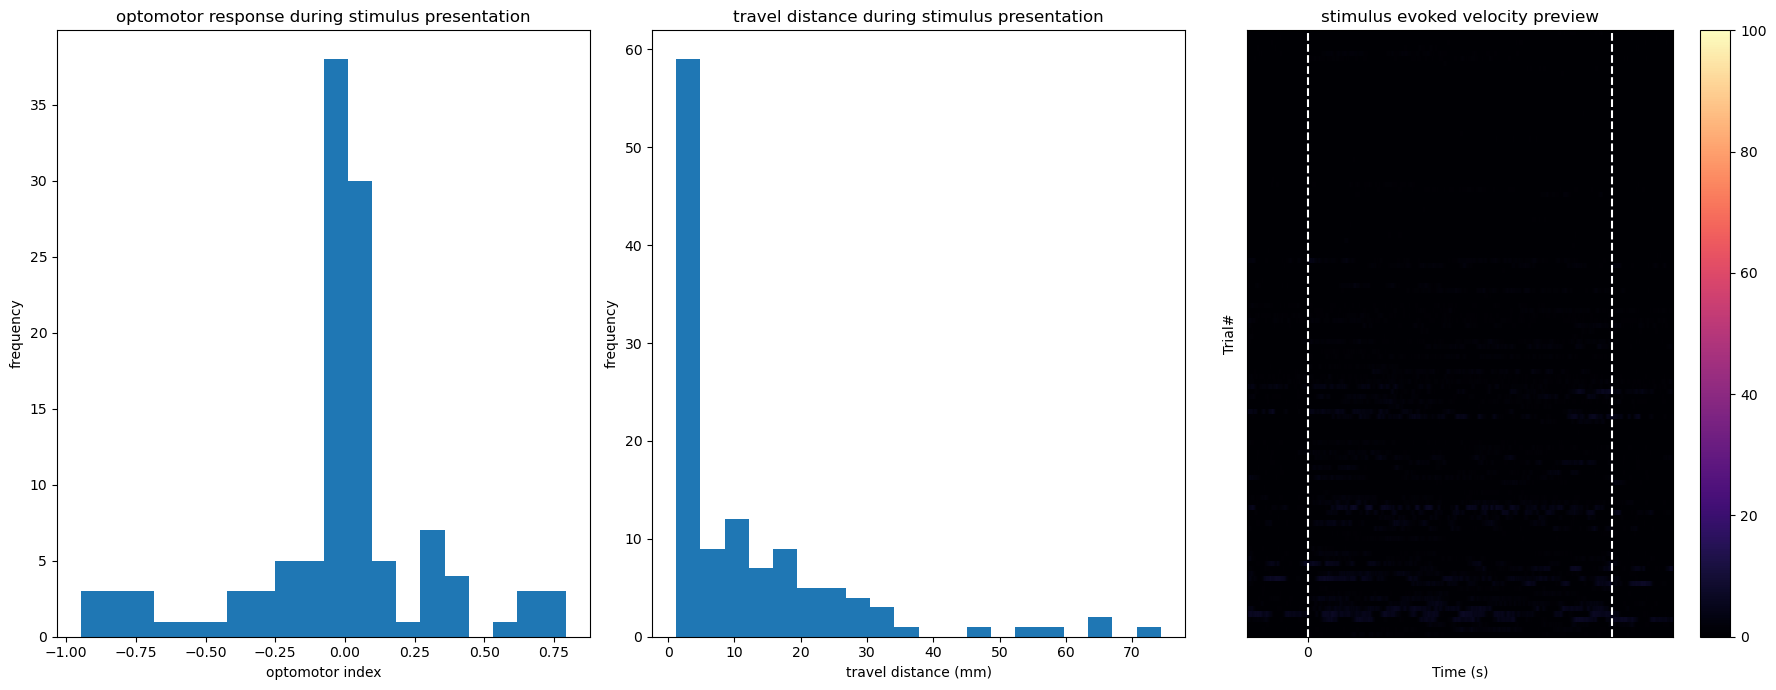

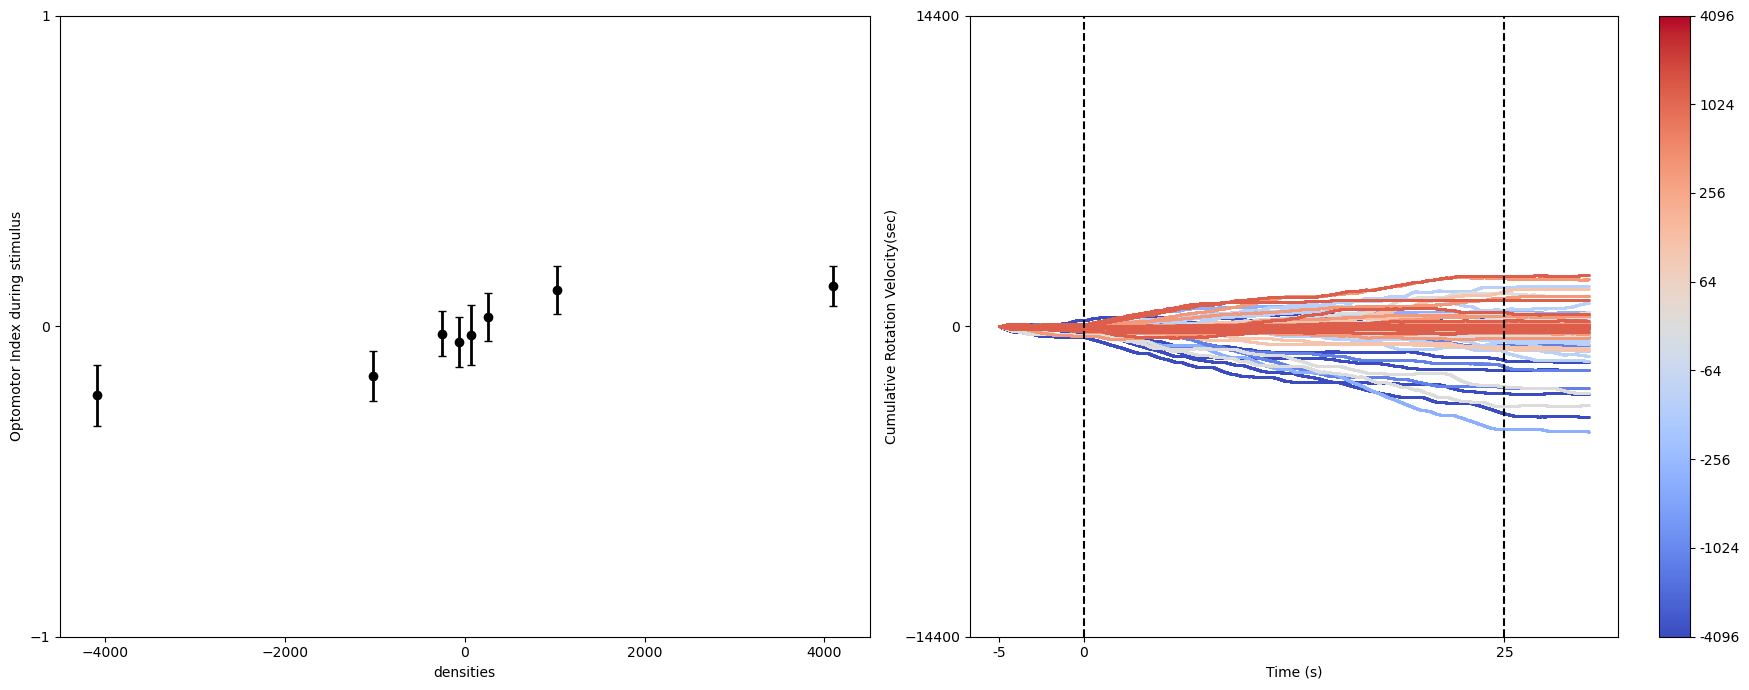

no PD*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22067/220907/densities. Let's leave this programme
no tracking_*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22067/220907/densities. Let's leave this programme
plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


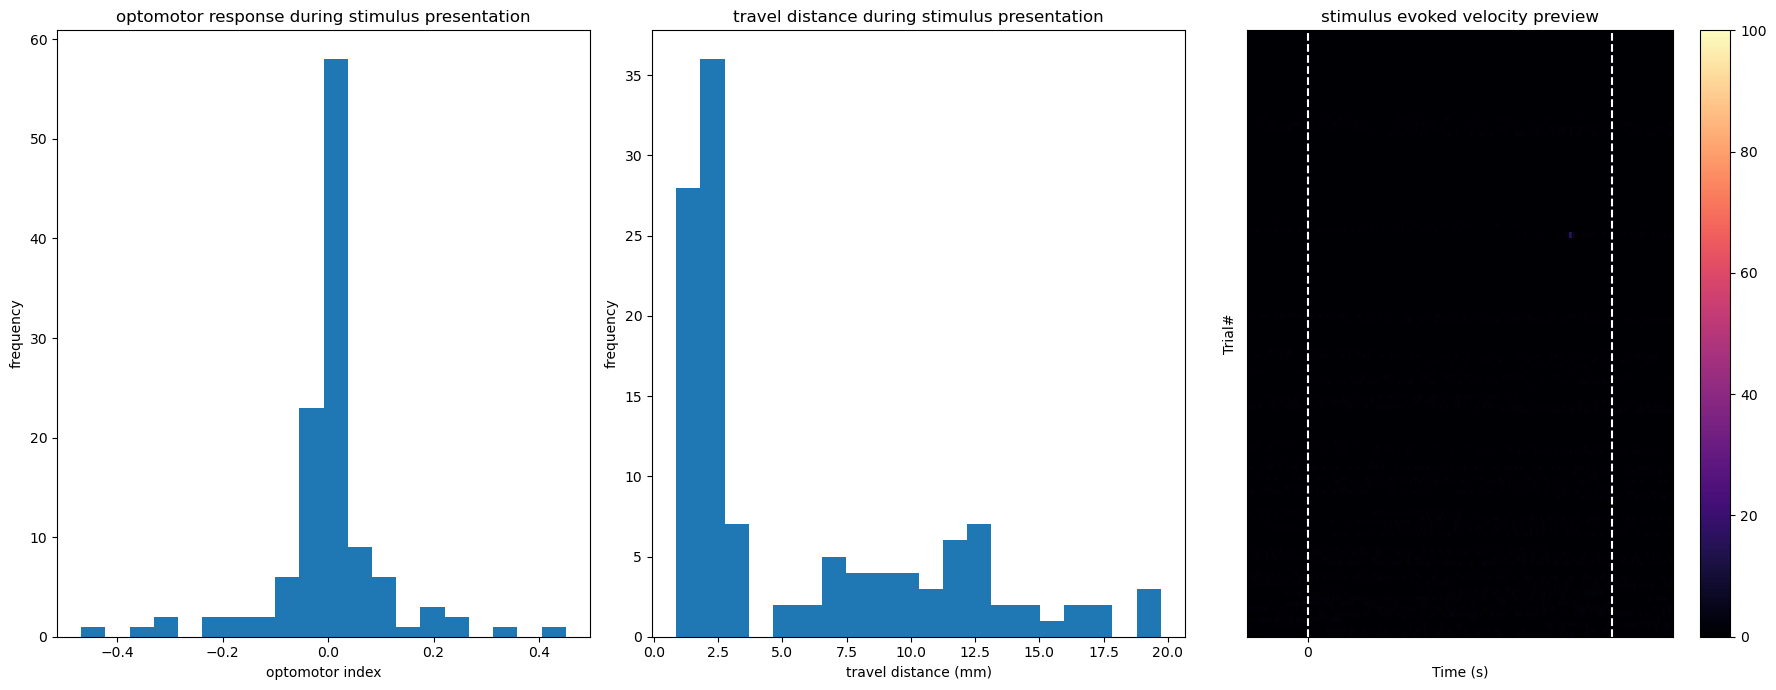

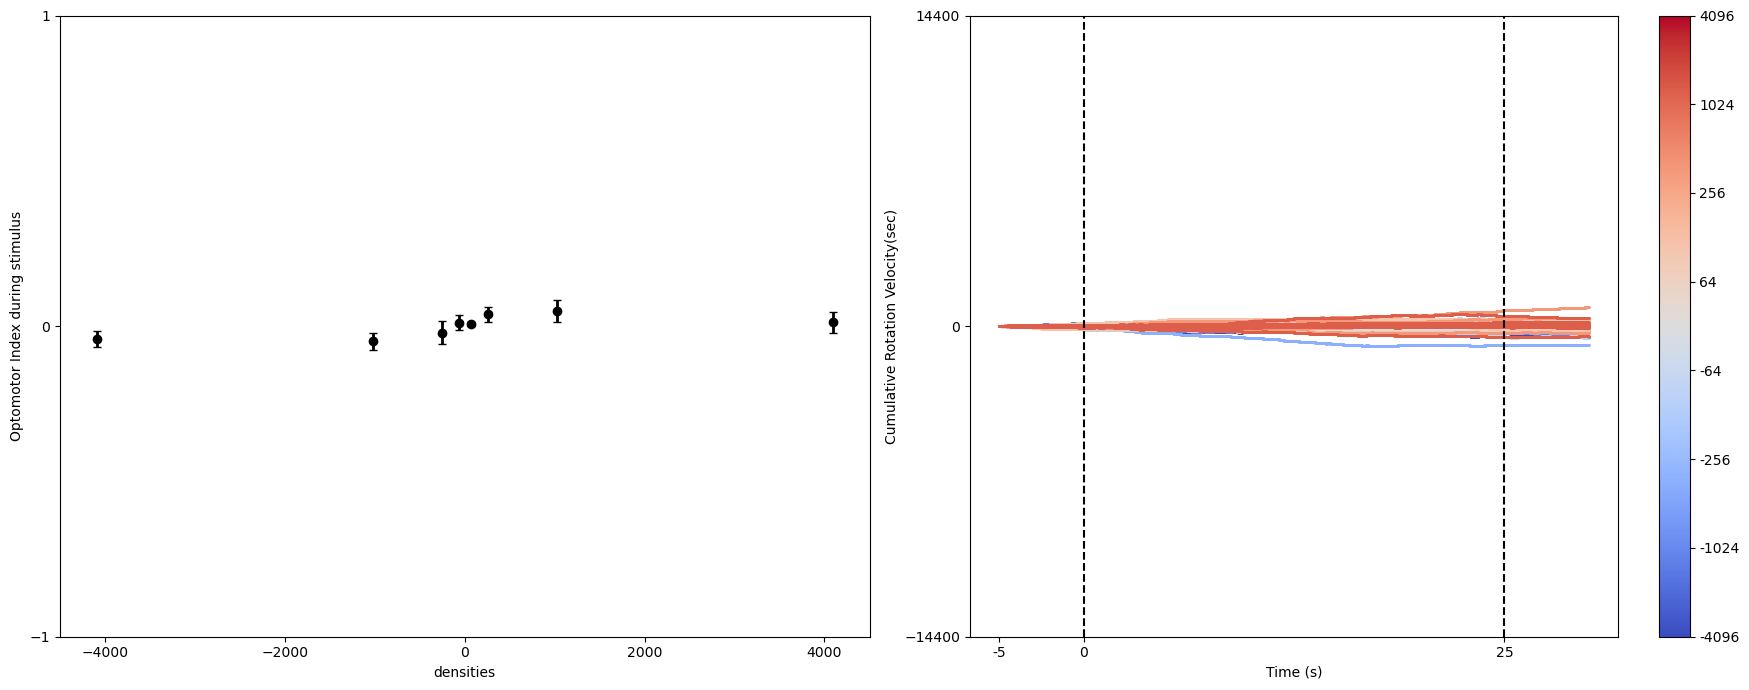

no PD*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22068/220907/densities. Let's leave this programme
no tracking_*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22068/220907/densities. Let's leave this programme
plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


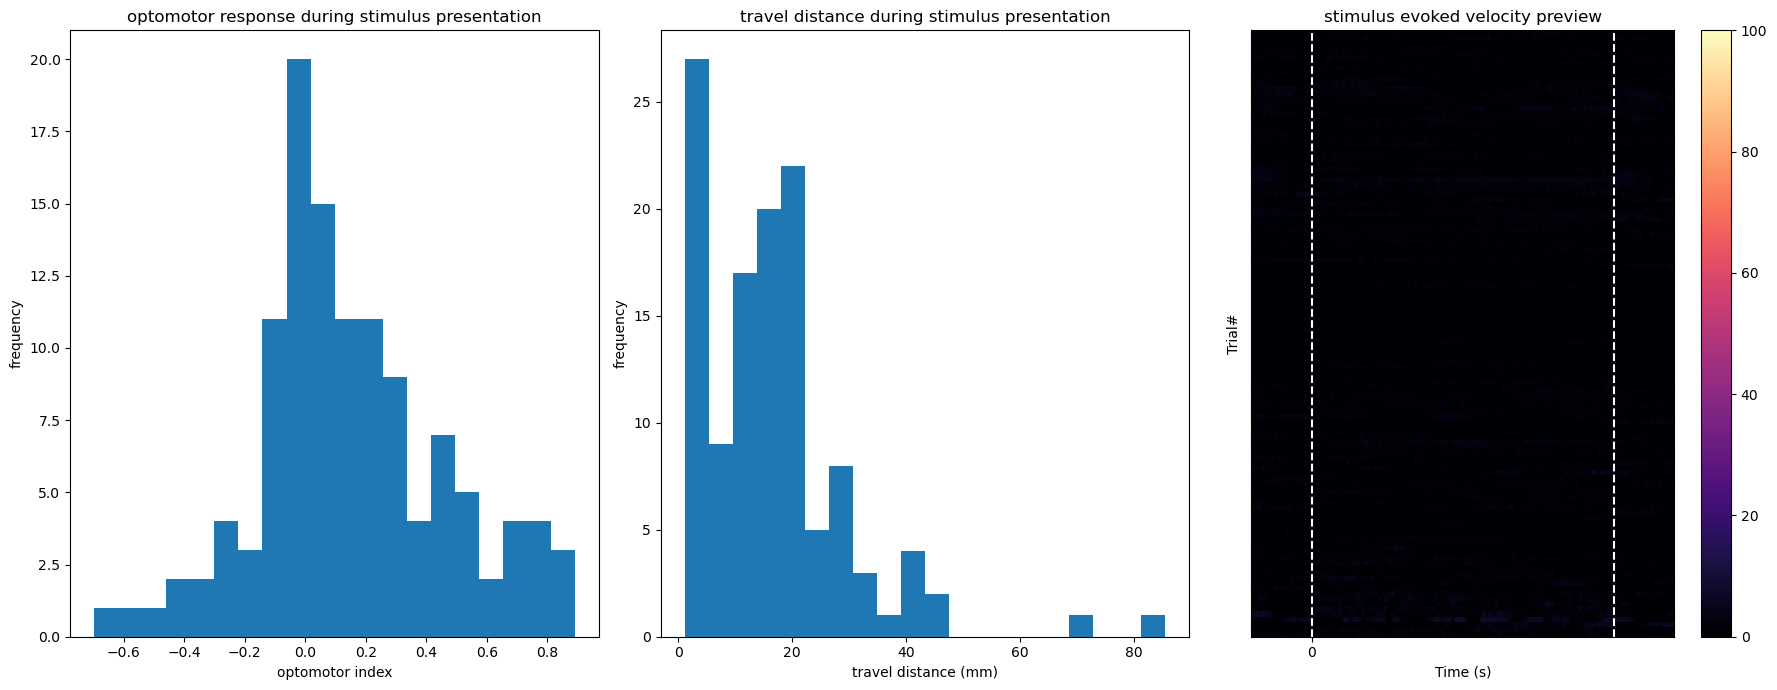

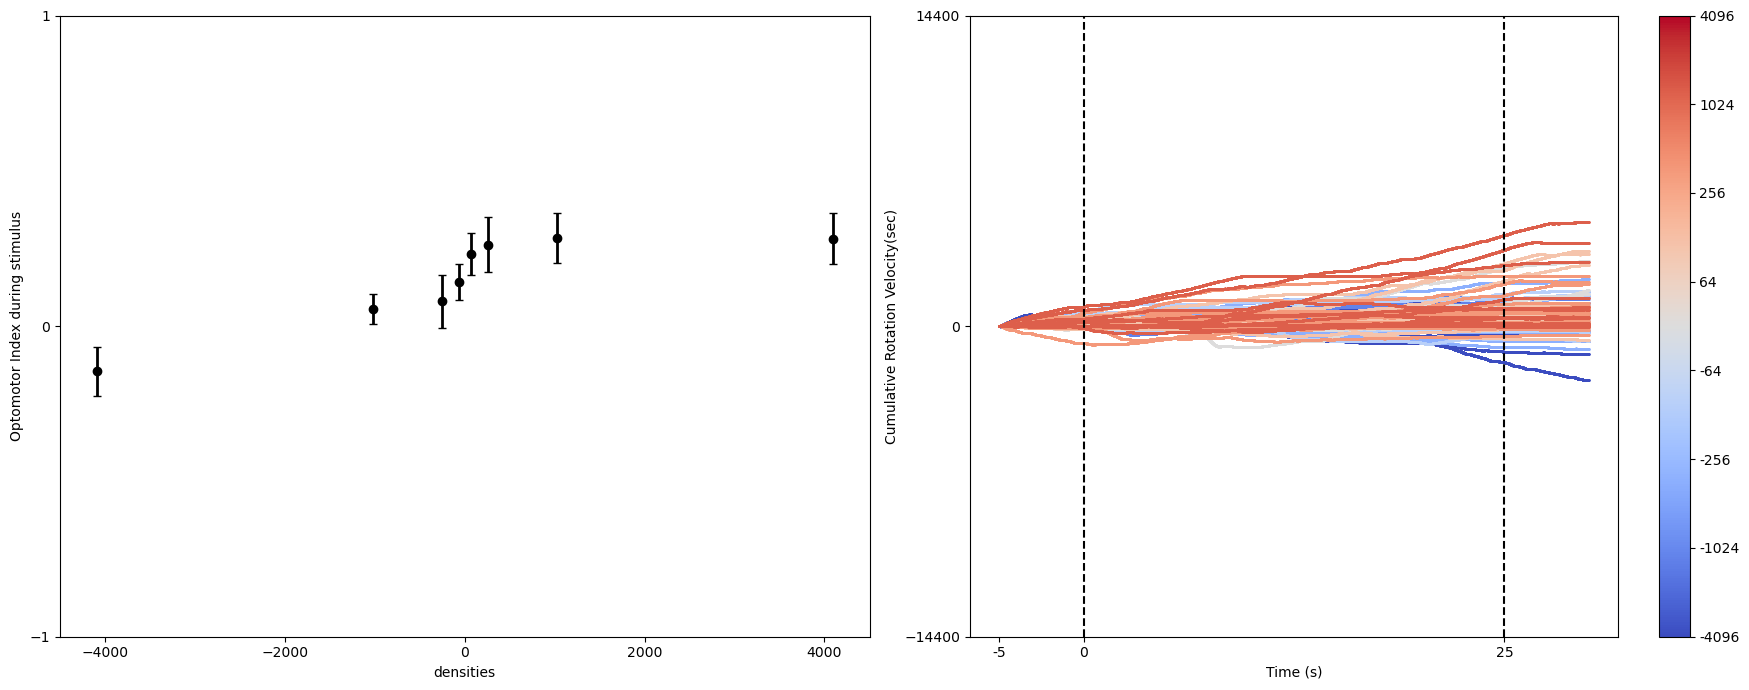

no PD*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22069/220908/densities. Let's leave this programme
no tracking_*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22069/220908/densities. Let's leave this programme
plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


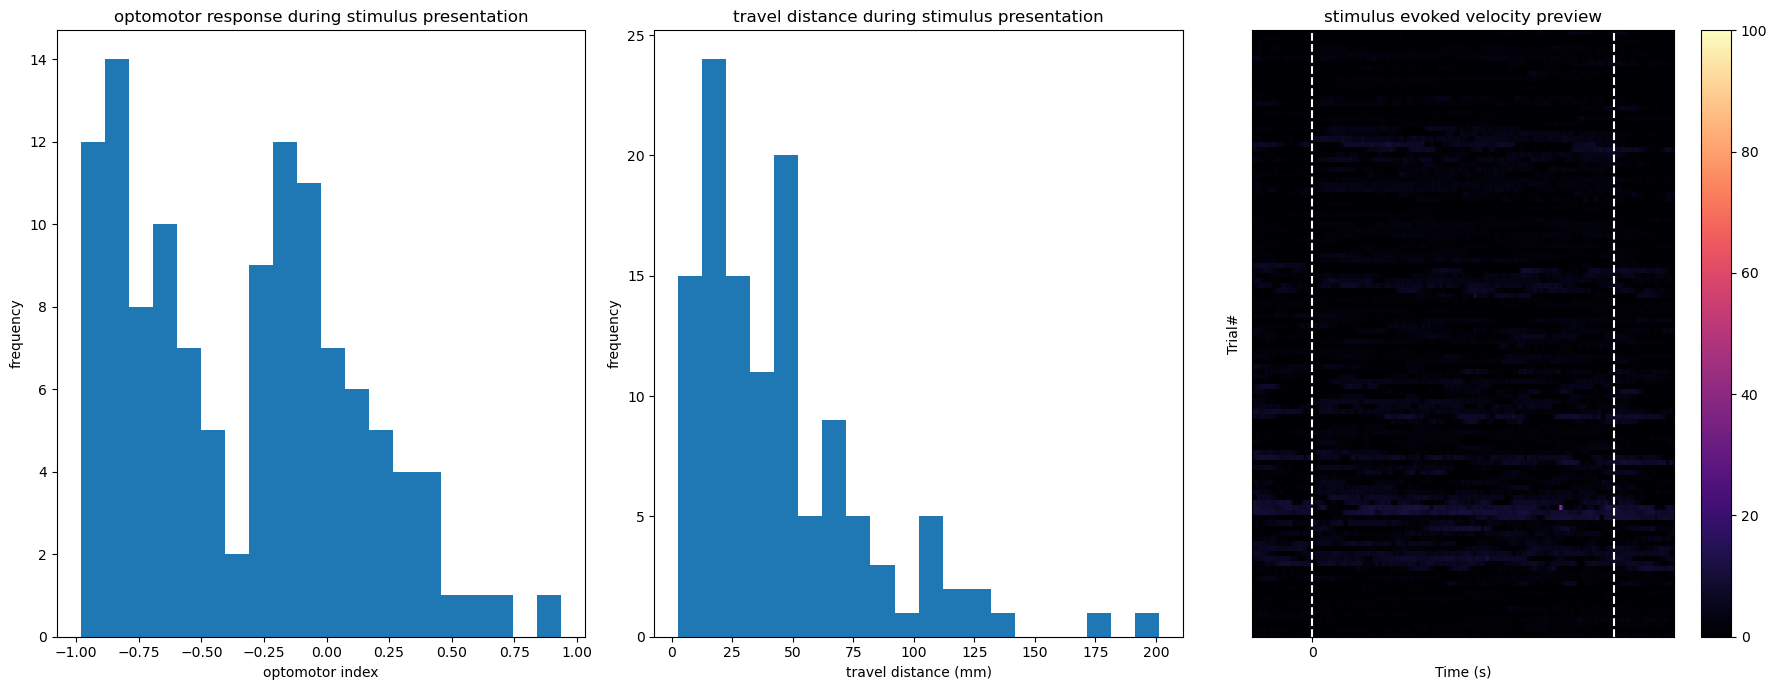

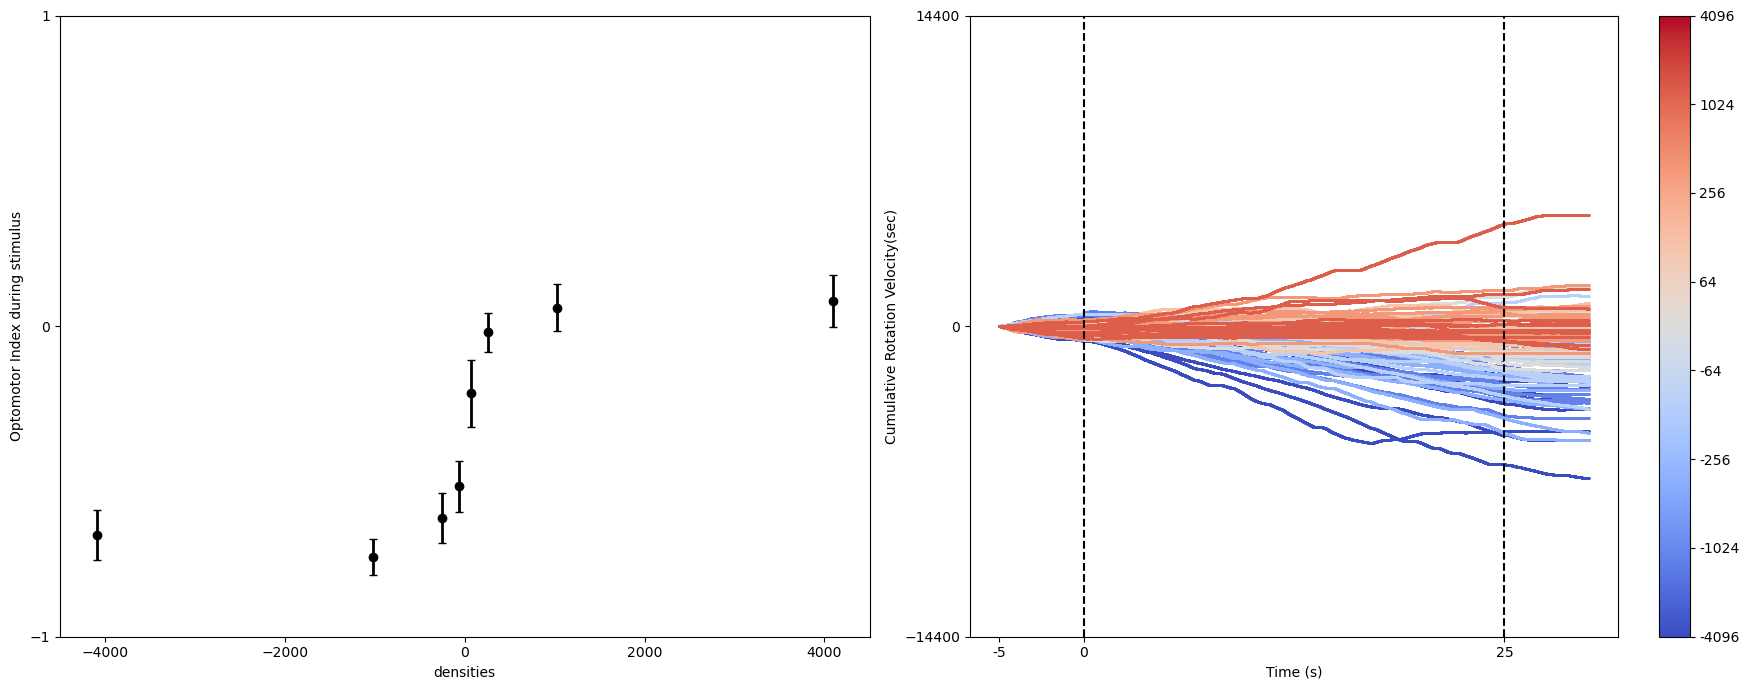

no PD*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22070/220908/densities. Let's leave this programme
no tracking_*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22070/220908/densities. Let's leave this programme
plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


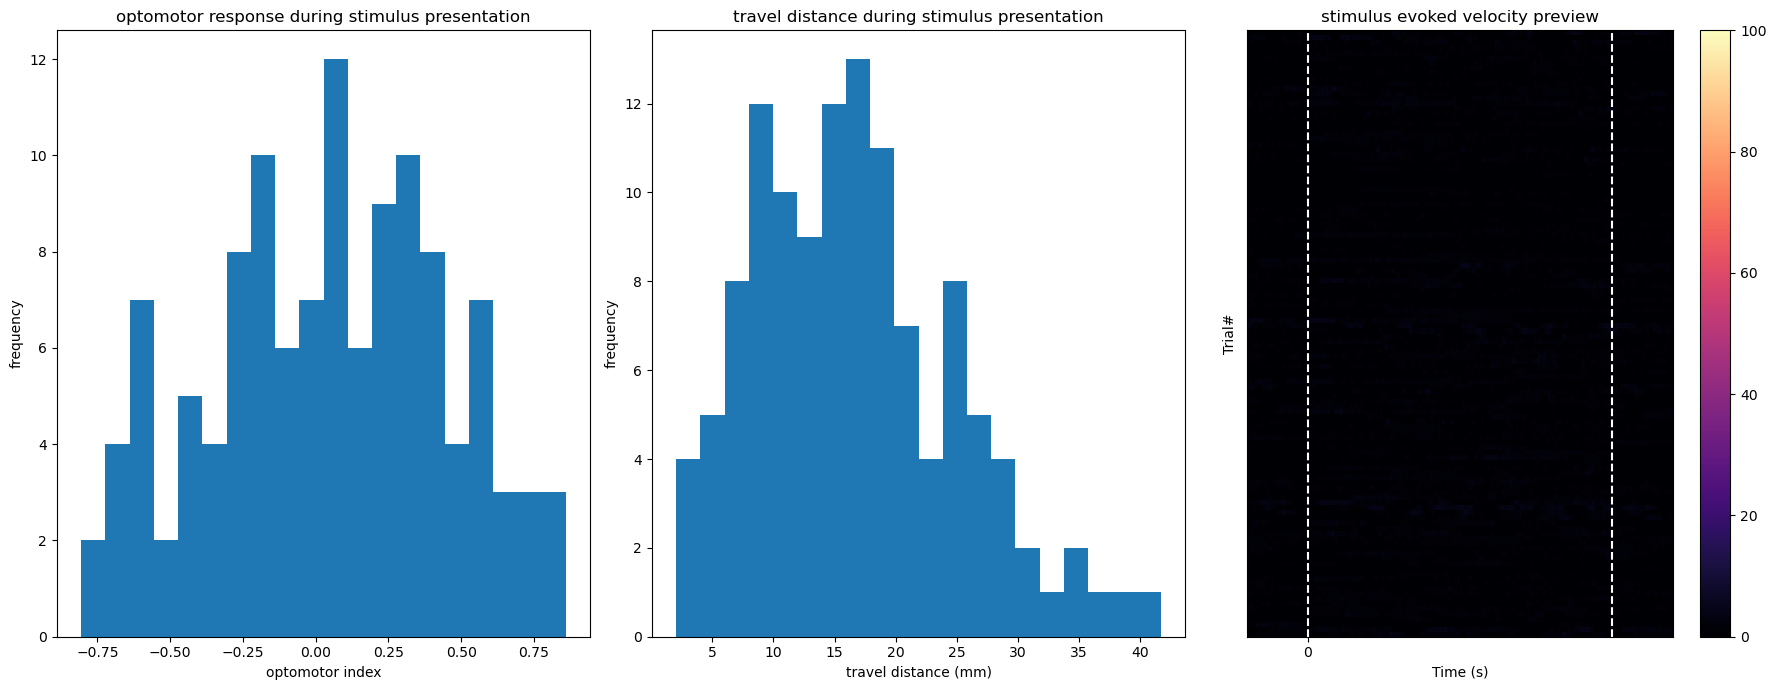

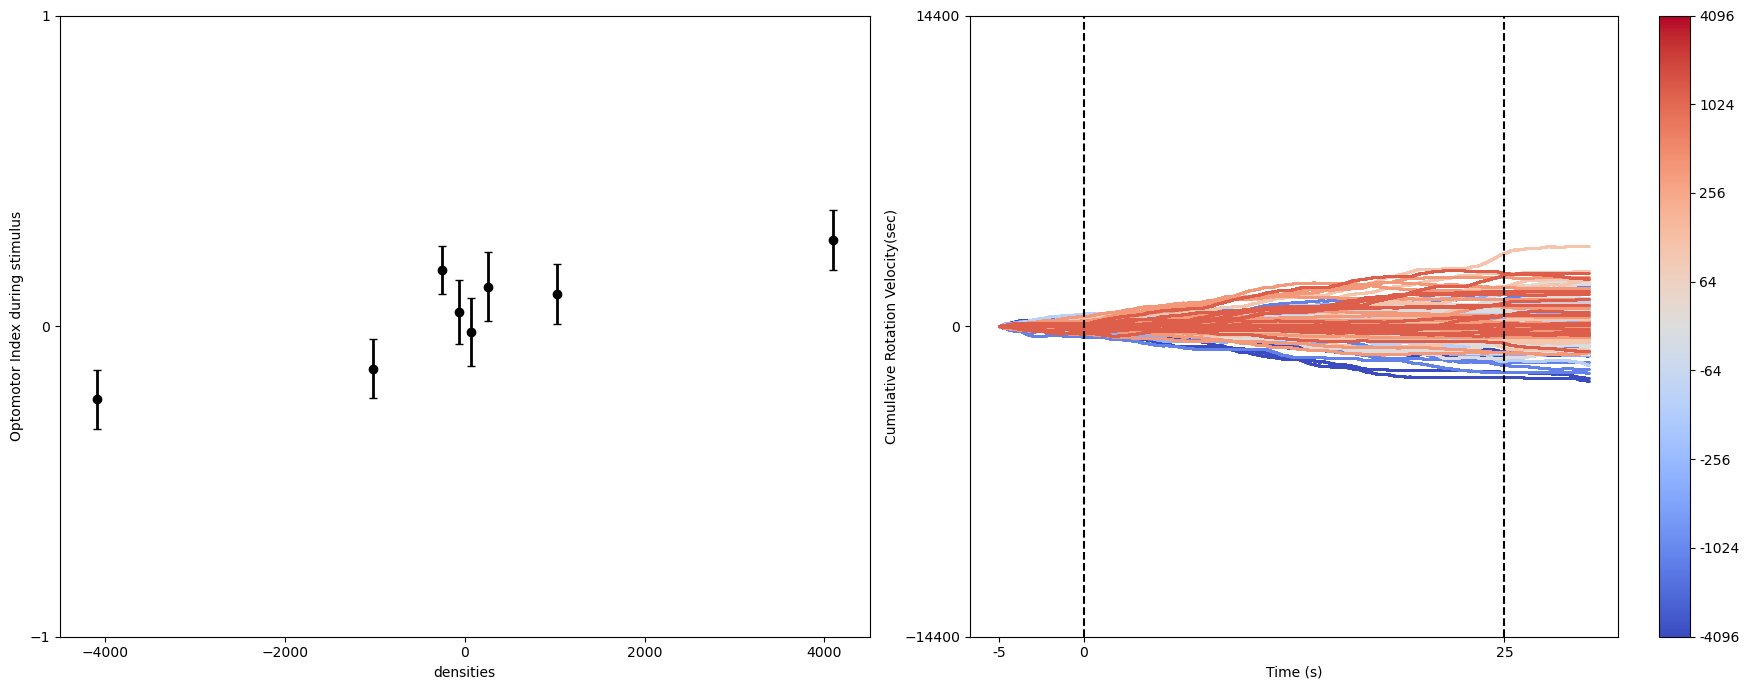

no PD*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22071/220908/densities. Let's leave this programme
no tracking_*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22071/220908/densities. Let's leave this programme
plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


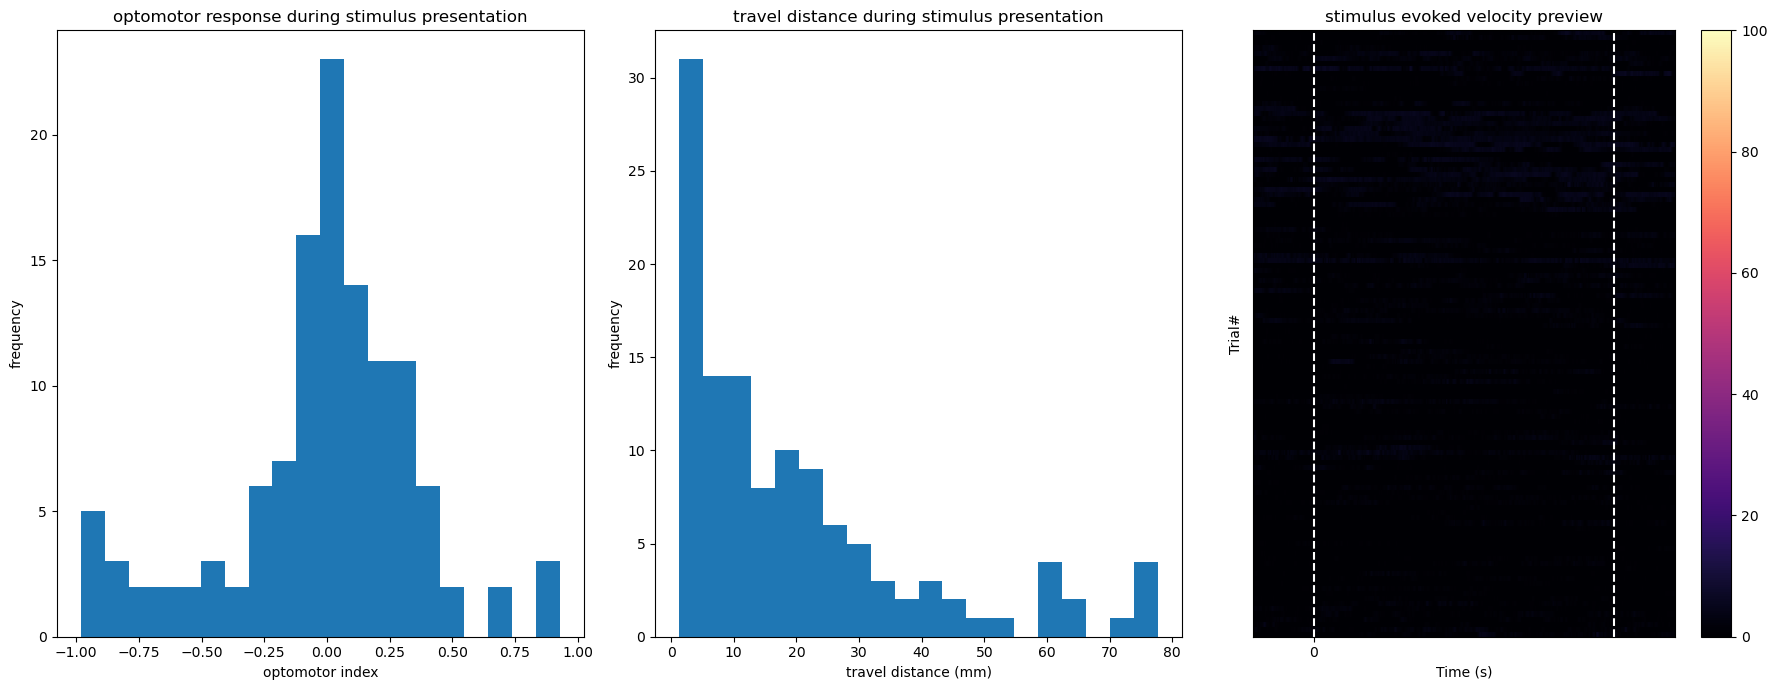

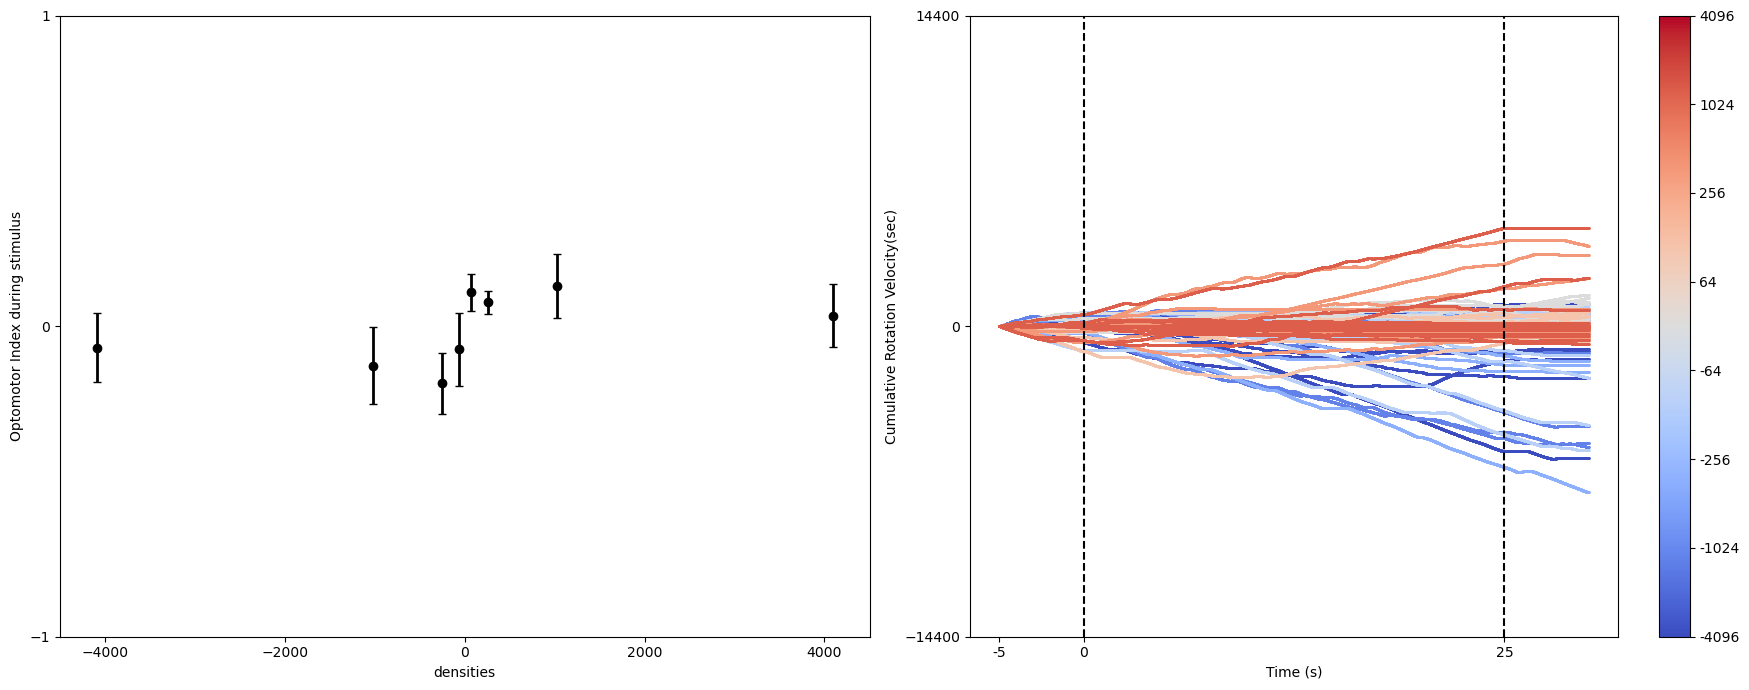

no PD*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22072/220908/densities. Let's leave this programme
no tracking_*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22072/220908/densities. Let's leave this programme
plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


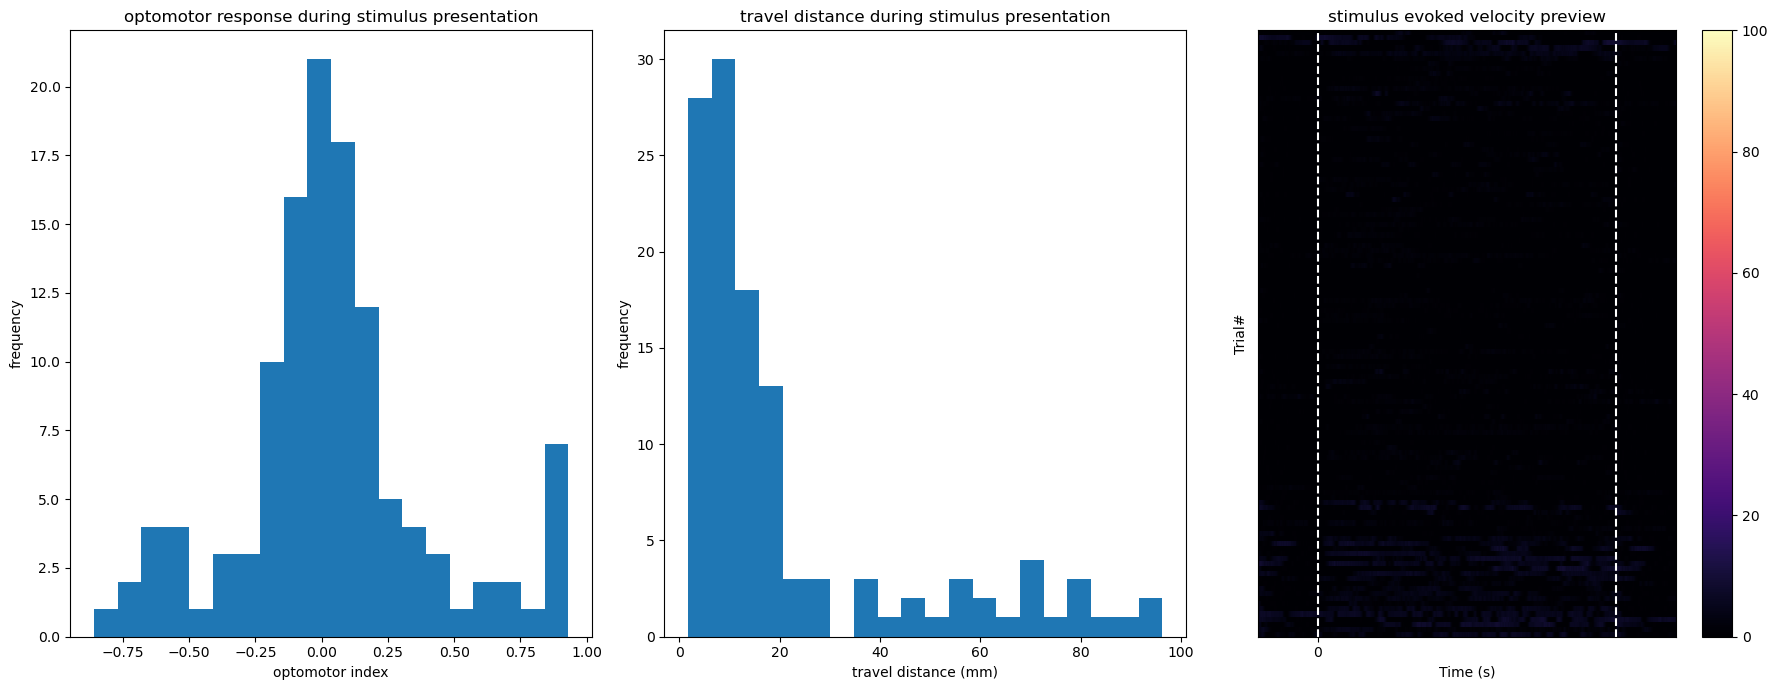

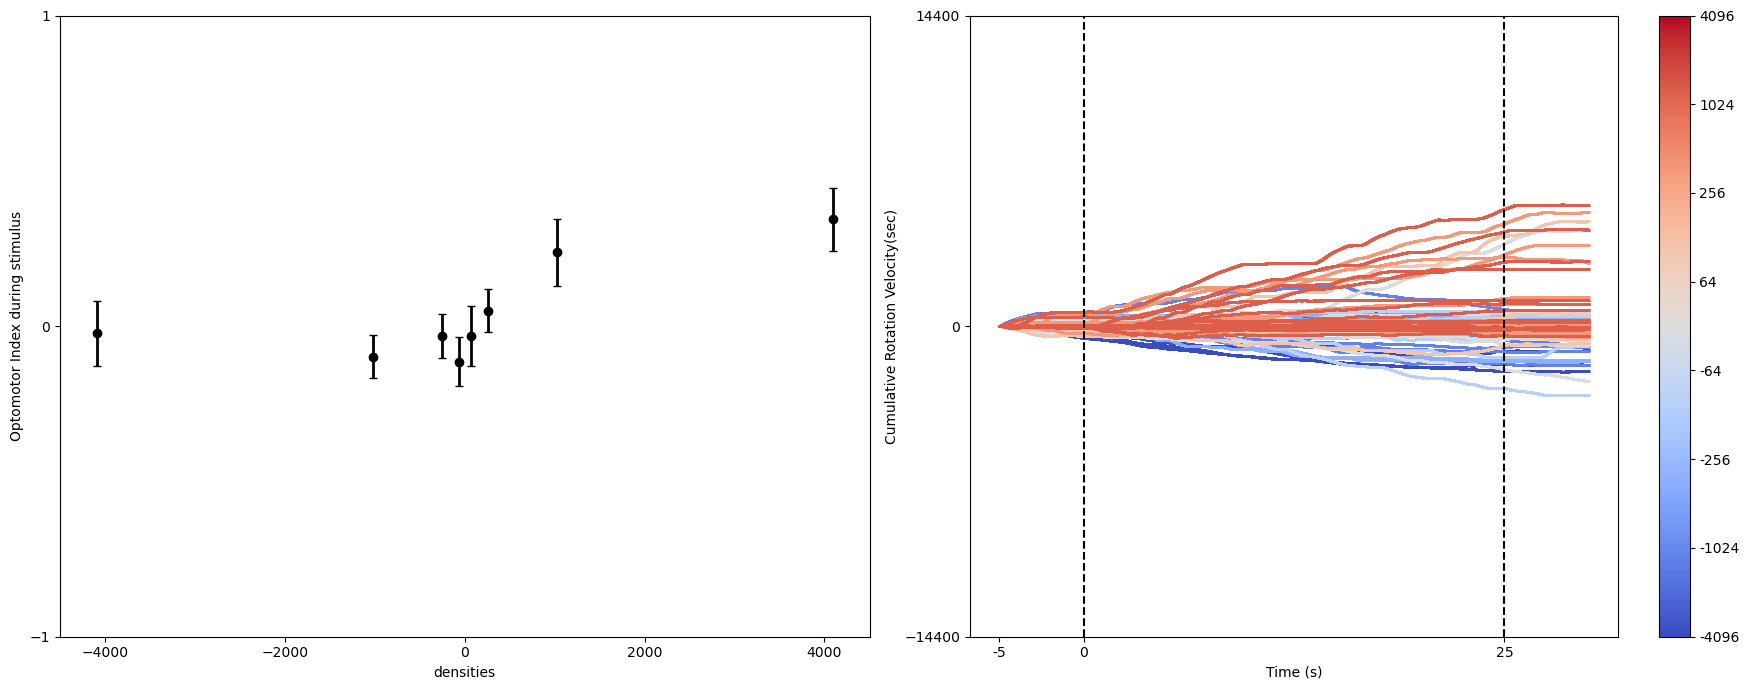

no PD*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22073/220908/densities. Let's leave this programme
no tracking_*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22073/220908/densities. Let's leave this programme
plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


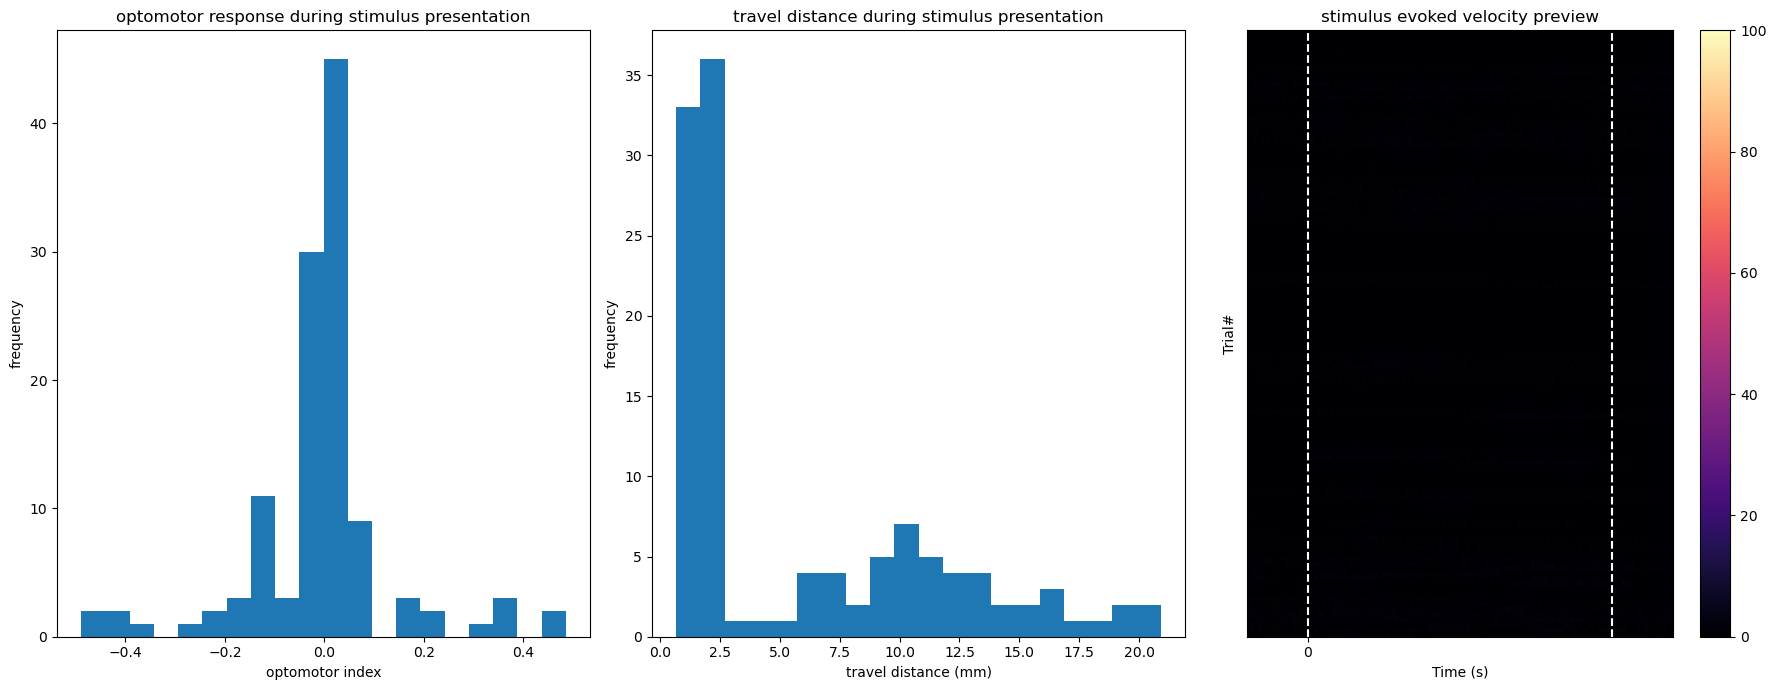

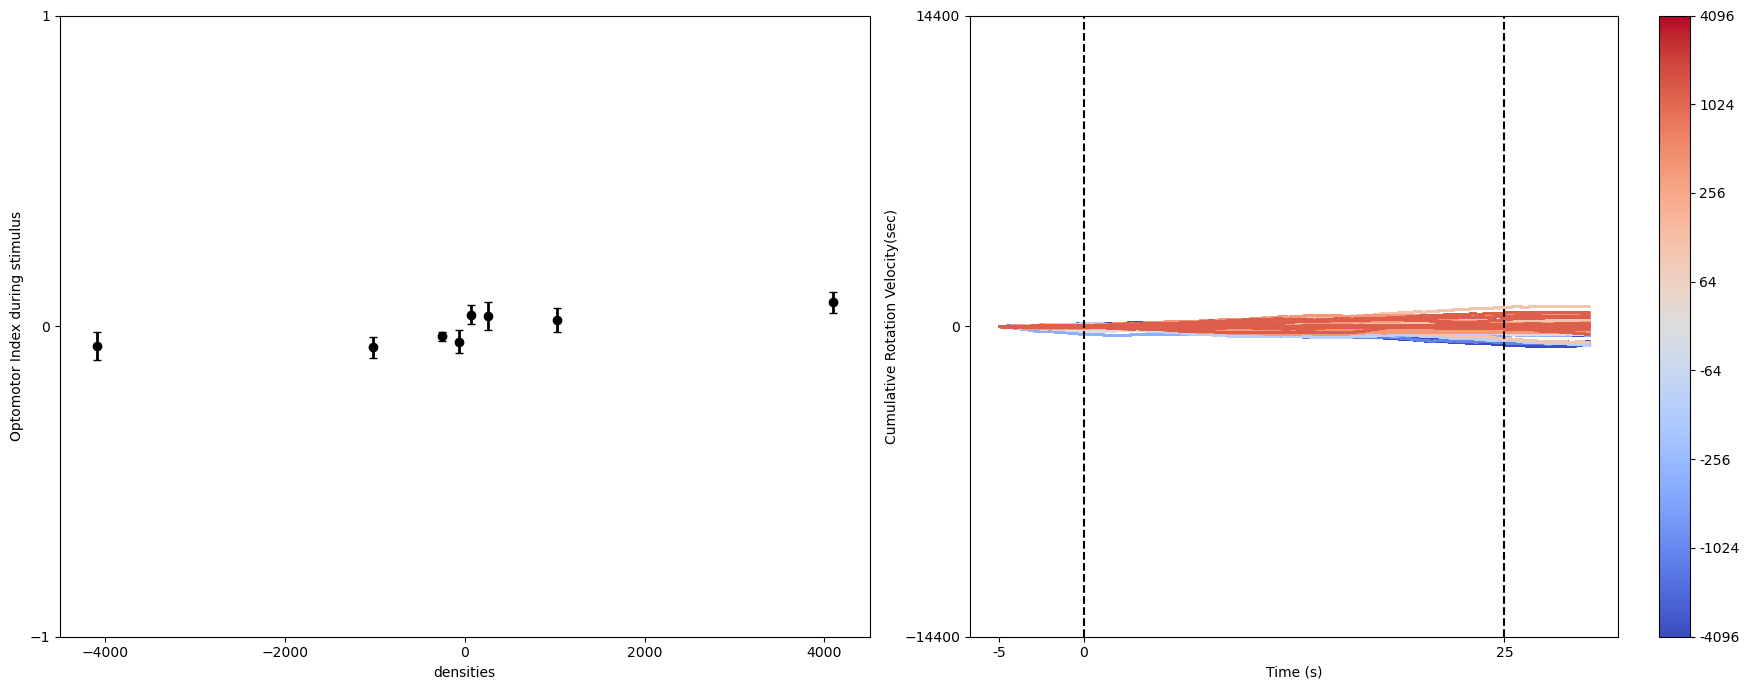

no PD*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22074/220908/densities. Let's leave this programme
no tracking_*.csv found in Z:/DATA/experiment_trackball_Optomotor/VCCball/L22074/220908/densities. Let's leave this programme
plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


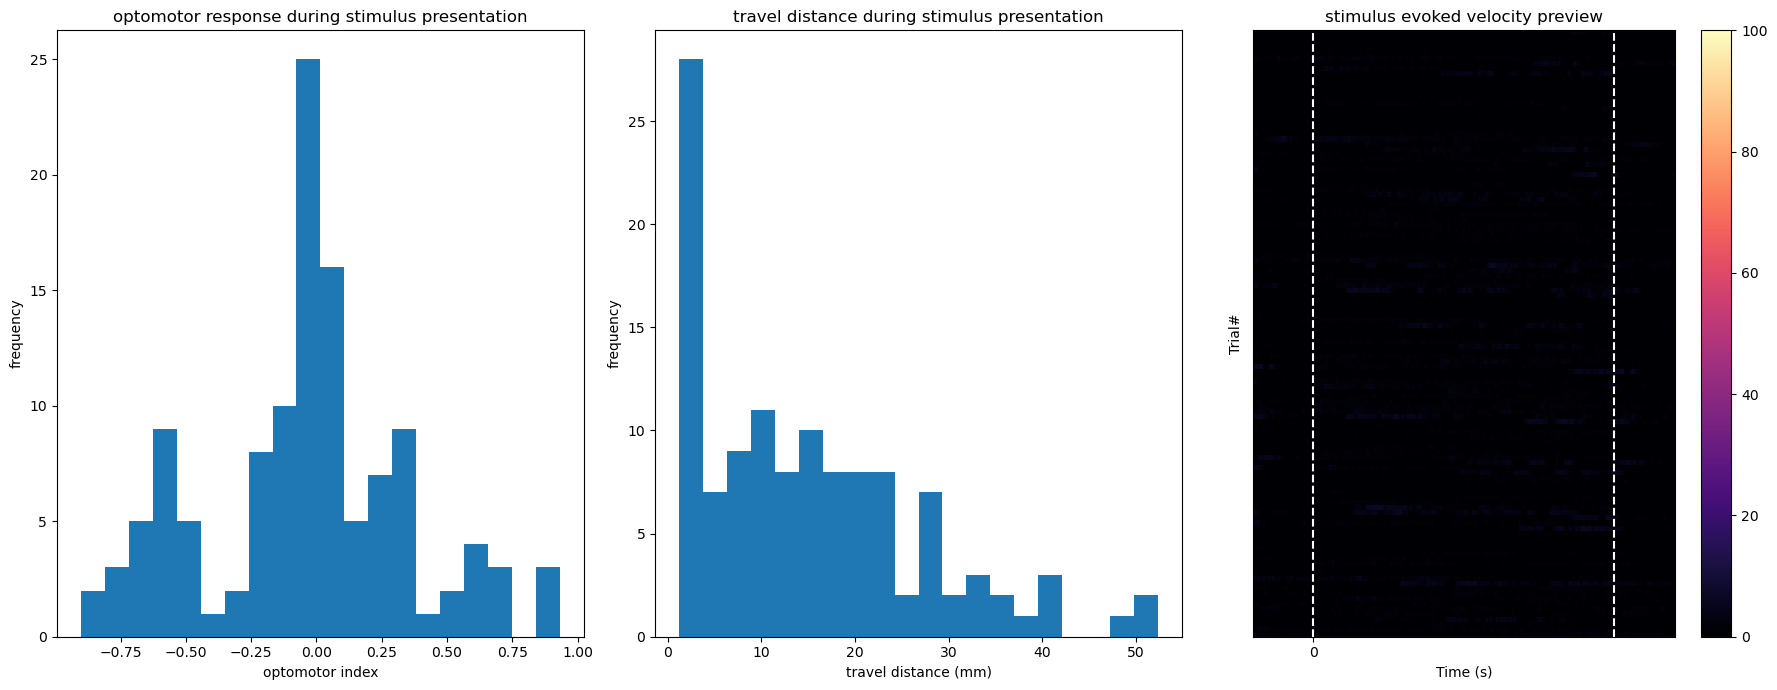

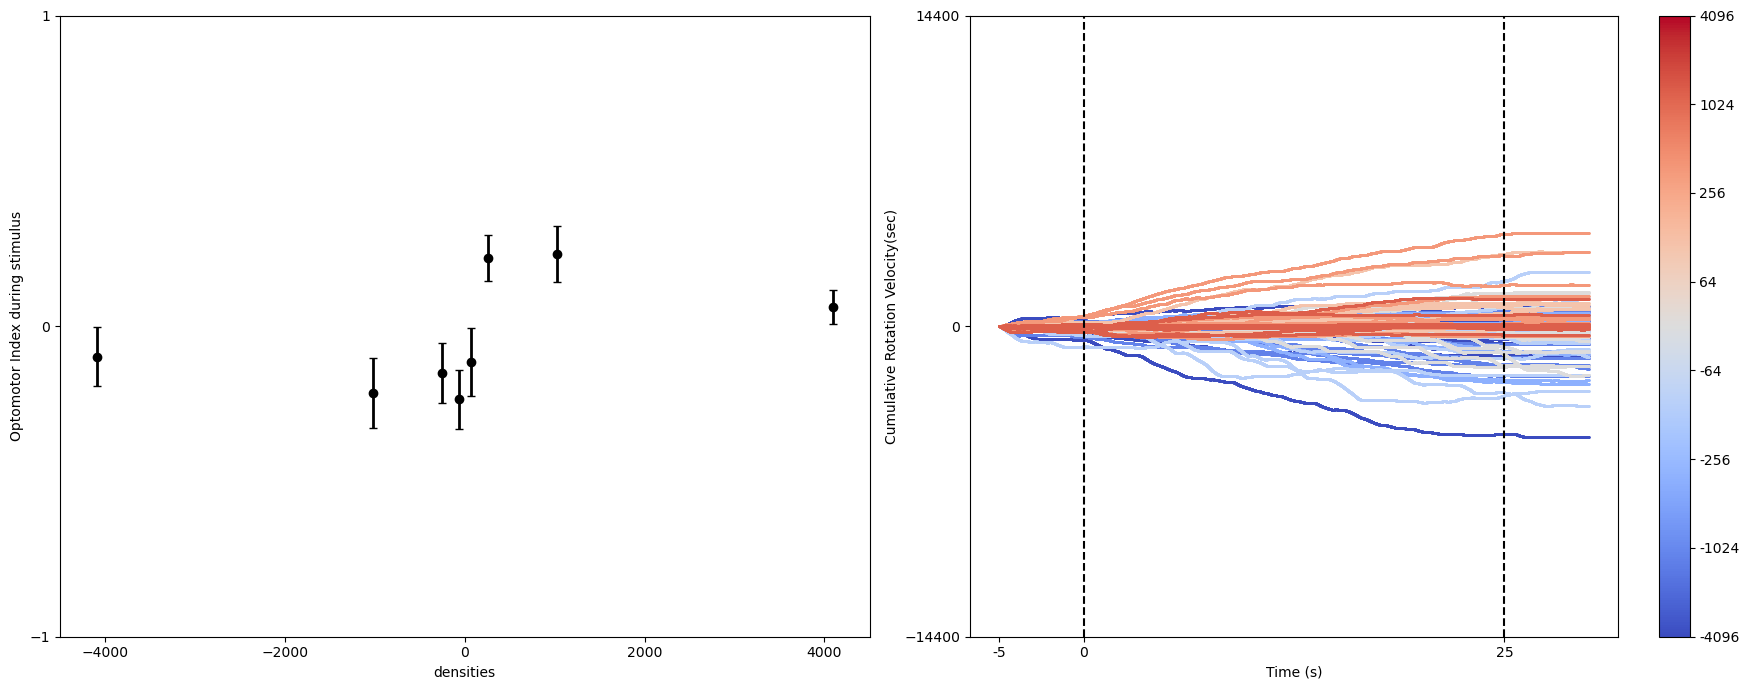

In [33]:
# because the import does not update the new version of python.
# Need to restart kernel 
output0_across_exp=[]
output1_across_exp=[]
output2_across_exp=[]
output3_across_exp=[]
for this_dir in new_list:
    summary,speed,rotation,travel_distance_whole_session=main(this_dir,analysis_methods)
    output0_across_exp.append(summary)
    output1_across_exp.append(speed)
    output2_across_exp.append(rotation)
    output3_across_exp.append(travel_distance_whole_session)


In [41]:
df=pd.DataFrame(pd.concat(output0_across_exp[18:]))

In [42]:
df

,opto_index_isi,opto_index,travel_distance_isi,travel_distance,stim_index,stim_type,optoxstim
0,-0.149330,0.516317,17.378906,17.806015,0,256,132.177063
1,0.085175,-0.084262,0.978413,42.544403,1,-1024,86.284569
2,-0.173750,0.394912,3.923198,36.456039,2,-64,-25.274395
3,0.261237,0.628823,5.479281,44.682137,3,64,40.244686
4,0.817667,-0.455472,23.159533,111.468964,4,-4096,1865.615234
...,...,...,...,...,...,...,...
115,0.015683,-0.010437,0.498725,2.596280,115,1024,-10.687788
116,-0.044636,-0.048711,0.465886,1.554721,116,-256,12.470126
117,0.042084,0.031367,0.354536,1.650798,117,256,8.030070
118,0.049625,-0.020522,0.244913,1.825979,118,-4096,84.058449


In [43]:
file_name=f"gregarious_database.csv"
df.to_csv(file_name)

In [ ]:
##this cell start the multi-engines. Make sure to run only once
import time
import ipyparallel as ipp
def show_clusters():
    clusters = ipp.ClusterManager().load_clusters() 
    print("{:15} {:^10} {}".format("cluster_id", "state", "cluster_file")) 
    for c in clusters:
        cd = clusters[c].to_dict()
        cluster_id = cd['cluster']['cluster_id']
        controller_state = cd['controller']['state']['state']
        cluster_file = getattr(clusters[c], '_trait_values')['cluster_file']
        print("{:15} {:^10} {}".format(cluster_id, controller_state, cluster_file))
    return cluster_id

cluster = ipp.Cluster(n=6)
await cluster.start_cluster()
cluster_neuropc=show_clusters()

In [ ]:
##input cluster_id from previous cell
rc = ipp.Client(cluster_id=cluster_neuropc)

# Create a DirectView for parallel execution
dview = rc.direct_view()

# Define a function for parallel processing
def process_directory(thisDir, analysis_methods):
    from analyse_stimulus_evoked_response import main
    # Check if the H5 file (curated dataset) exists
    summary,speed,rotation = main(thisDir, analysis_methods)
    return (summary,speed,rotation)

# Define analysis_methods

# Use parallel execution to process directories
results = dview.map_sync(process_directory, dir_list, [analysis_methods] * len(dir_list))

# Initialize result lists
output0_across_exp=[]
output1_across_exp=[]
output2_across_exp=[]

# Collect and organize results
for result in results:
    if result is not None:
        summary,speed,rotation = result
        output0_across_exp.append(summary)
        output1_across_exp.append(speed)
        output2_across_exp.append(rotation)

# Now, you have the results collected in the respective lists

In [ ]:
rc.shutdown()

In [44]:
path = '../../optomotor_density_new.csv'
df = pd.read_csv(path,index_col=0)
df

,opto_index_isi,opto_index,travel_distance_isi,travel_distance,stim_index,stim_type,optoxstim,I
A,,,,,,,,
1,-0.149330,0.516317,17.378906,17.806015,0,256,132.177063,g
1,0.085175,-0.084262,0.978413,42.544403,1,-1024,86.284569,g
1,-0.173750,0.394912,3.923198,36.456040,2,-64,-25.274395,g
1,0.261237,0.628823,5.479281,44.682137,3,64,40.244686,g
1,0.817667,-0.455472,23.159533,111.468960,4,-4096,1865.615234,g
...,...,...,...,...,...,...,...,...
32,-0.000072,0.006331,0.294817,1.227799,115,1024,6.483387,s
32,-0.001250,-0.003141,0.221402,1.132018,116,-256,0.804096,s
32,0.000003,0.003021,0.234763,1.146000,117,256,0.773252,s


In [45]:
dfsel = df[df['travel_distance']>5]
#df.hist('Median speed')

In [46]:
dfsel

,opto_index_isi,opto_index,travel_distance_isi,travel_distance,stim_index,stim_type,optoxstim,I
A,,,,,,,,
1,-0.149330,0.516317,17.378906,17.806015,0,256,132.177063,g
1,0.085175,-0.084262,0.978413,42.544403,1,-1024,86.284569,g
1,-0.173750,0.394912,3.923198,36.456040,2,-64,-25.274395,g
1,0.261237,0.628823,5.479281,44.682137,3,64,40.244686,g
1,0.817667,-0.455472,23.159533,111.468960,4,-4096,1865.615234,g
...,...,...,...,...,...,...,...,...
32,-0.028708,0.076745,6.293695,10.269834,28,1024,78.586876,s
32,0.020128,-0.188606,0.386273,6.037591,38,4096,-772.529053,s
32,-0.197882,-0.698149,1.061345,20.906029,39,-1024,714.904480,s


In [47]:
file_name=f"density_database_no_stationary.csv"
dfsel.to_csv(file_name)

In [ ]:
plt.hist(output3_across_exp,bins=range(0,10000,1000))

In [ ]:
init_frame=analysis_methods.get("interval_duration")*analysis_methods.get("frame_rate")
culz_stim_onset=test4[:,init_frame]
DF=pd.DataFrame(culz_stim_onset)
file_name=f"culz_onset4.csv"
DF.to_csv(file_name)

In [ ]:
init_frame=analysis_methods.get("interval_duration")*analysis_methods.get("frame_rate")
prestim_analyse=5
prestim_5_sec=init_frame-prestim_analyse*analysis_methods.get("frame_rate")

In [ ]:
culz_stim_onset=output2_arr[:,init_frame]
culz_stim_onset_5sec_before=output2_arr[:,init_frame-prestim_5_sec]
this_response=culz_stim_onset-culz_stim_onset_5sec_before
DF=pd.DataFrame(this_response)
file_name=f"culz_onset.csv"
DF.to_csv(file_name)

In [ ]:
visual_paradigm_name= analysis_methods.get("experiment_name")
colormap = np.array(analysis_methods.get("graph_colour_code"))
fig2, (ax3, ax4) = plt.subplots(
    nrows=1, ncols=2, figsize=(18, 7), tight_layout=True
)
for i in range(len(output0_across_exp)):
    this_animal = output0_across_exp[i]
    tmp=this_animal.groupby("stim_type").count()
    follow_count_coherence = tmp.index.values
    for j in range(len(this_animal.groupby("stim_type"))):
        this_coherence=follow_count_coherence[j]
        this_response = this_animal.loc[
            this_animal["stim_type"] == this_coherence, "opto_index"
        ].values
        # this_coherence = x_axis_value_running_trials[i]
        mean_response = np.mean(this_response, axis=0)
        sem_response = np.std(this_response, axis=0, ddof=1) / np.sqrt(
            this_response.shape[0]
        )
        ax3.errorbar(
            this_coherence,
            mean_response,
            yerr=sem_response,
            c=colormap[5],
            fmt="o",
            elinewidth=2,
            capsize=3,
        )
    ax3.set_ylim(-1, 1)
    ax3.set(
        yticks=[-1, 0, 1],
        ylabel="Optomotor Index",
        xlabel=visual_paradigm_name,)
    # ax4.scatter(follow_count_coherence, follow_count, c=colormap[0], marker="o")
    # ax4.set_ylim(0, 15)
    # ax4.set(
    #     yticks=[0, 15],
    #     ylabel="Follow response (count)",
    #     xticks=[100, 50, 0, -50, -100],
    #     xlabel="Coherence level (%)",
    # )
    ##following one dot (dot lifetime)
    ##memory part (30s)
    ##interval: rondot
    ##continous